In [49]:
%load_ext autoreload
%autoreload 2

import numpy as np 
import functions 

from matplotlib import pyplot as plt

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [50]:
import importlib
import functions
importlib.reload(functions)

<module 'functions' from '/Users/peytaguo/Desktop/ASC/Nucelar Resonance Analysis /functions.py'>

In [4]:
ne_amu = 19.9869544
a_amu = 4.001506179129

mg_amu = 23.9784588
uc2 = 931.494 #MeV

energy_threshold = (ne_amu + a_amu - mg_amu)*uc2
print(energy_threshold)

9.316597247987401


In [5]:
sigma = np.load("data/peyta_sigma1.npy")
dsigma = np.load("data/peyta_dsigma1.npy")
theta_cm = np.load("data/peyta_theta_cm1.npy")
ke_cm = np.load("data/peyta_ke_cm1.npy")

rounded_theta_cm = np.round(theta_cm, 1)
rounded_theta_cm[rounded_theta_cm == 53.2] = 53.1
rounded_theta_cm[rounded_theta_cm == 143.2] = 143.1
rounded_theta_cm[rounded_theta_cm == 155.7] = 155.8

print( np.unique( rounded_theta_cm ) )
print(len(np.unique(rounded_theta_cm)))

[ 53.1  58.8  70.   75.5  86.2  91.4 101.6 106.5 116.2 125.5 130.  138.8
 143.1 155.8 163.9 168. ]
16


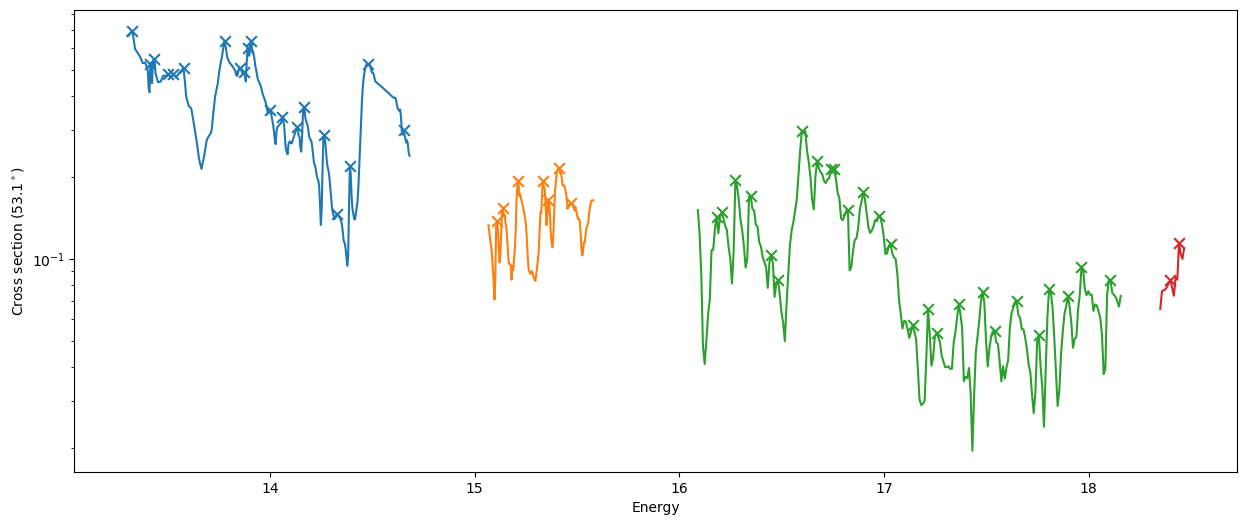

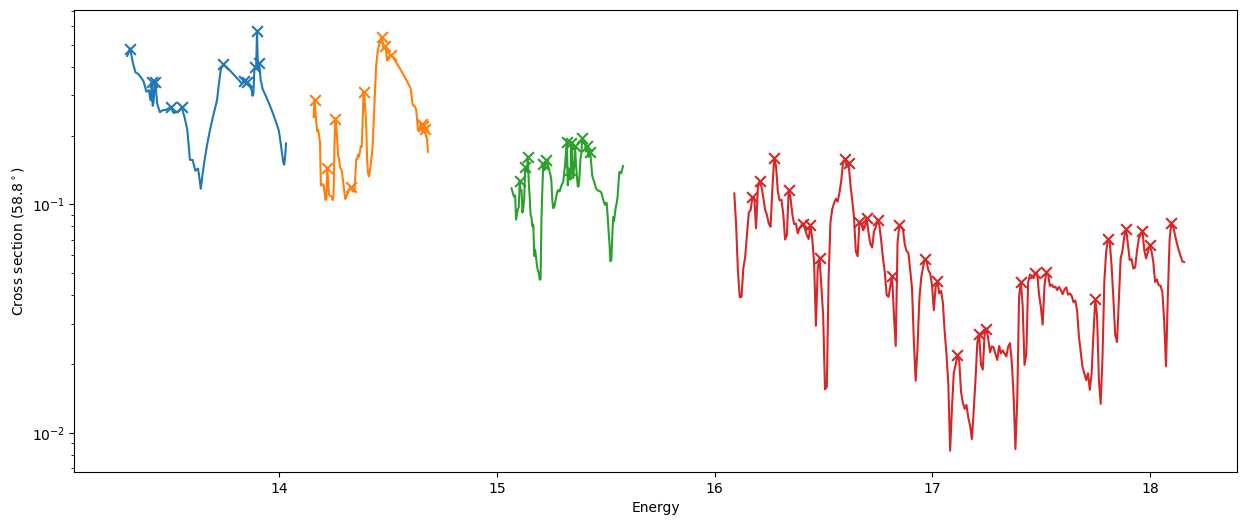

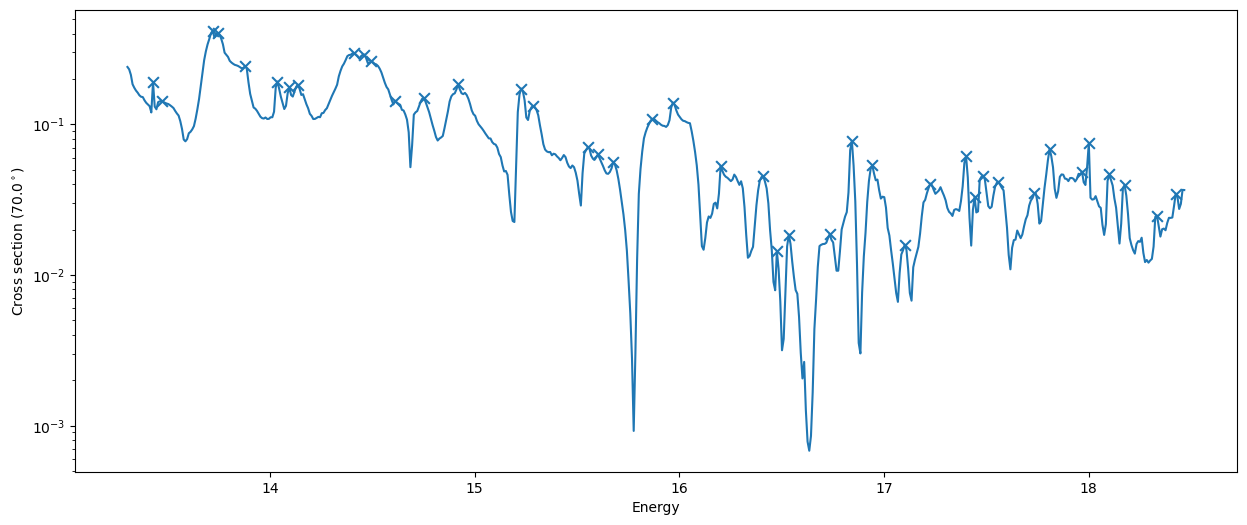

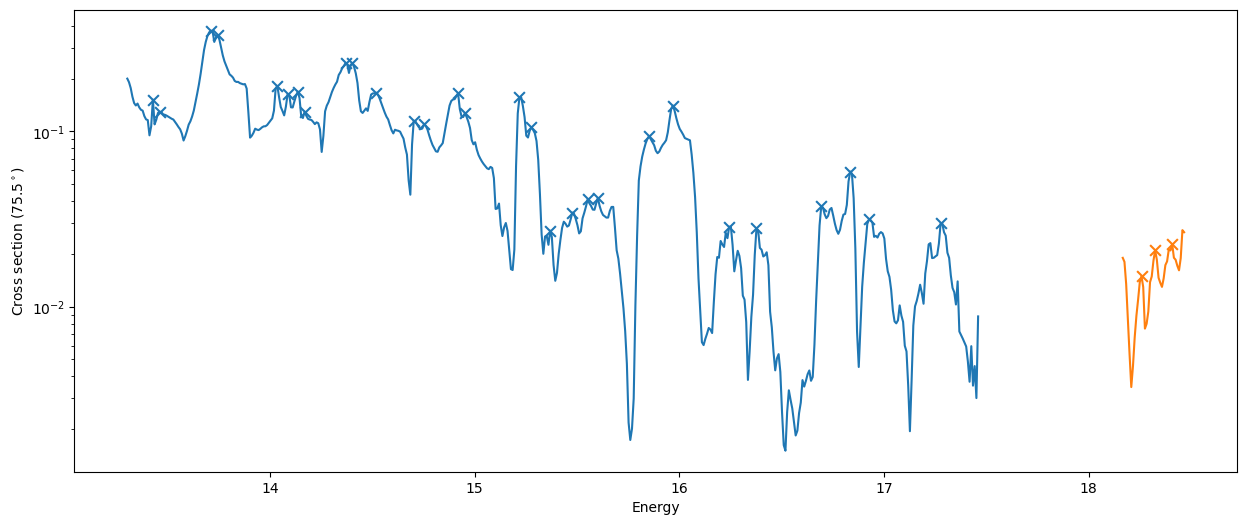

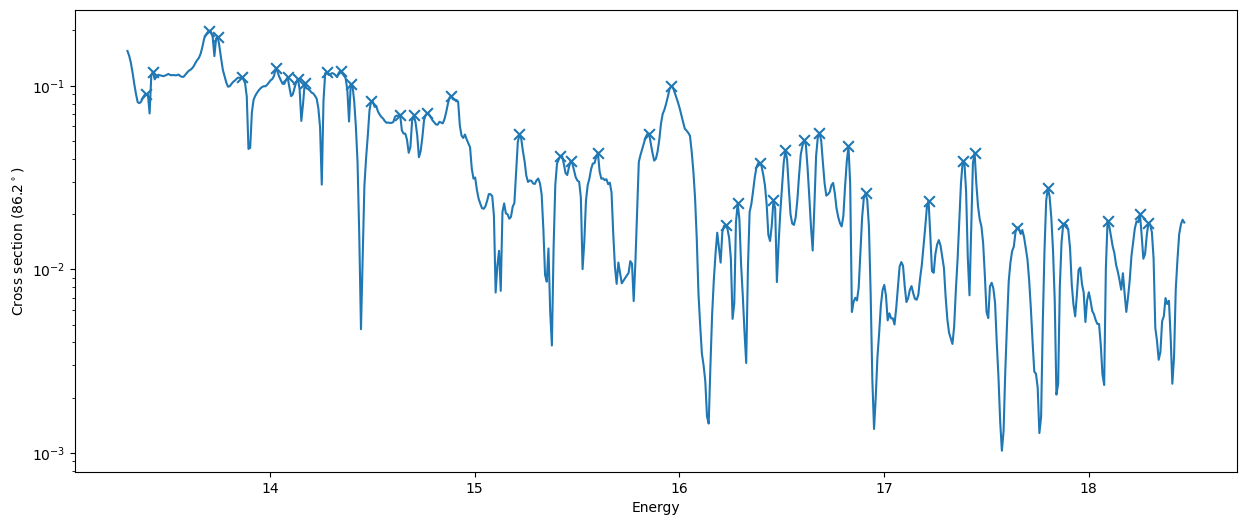

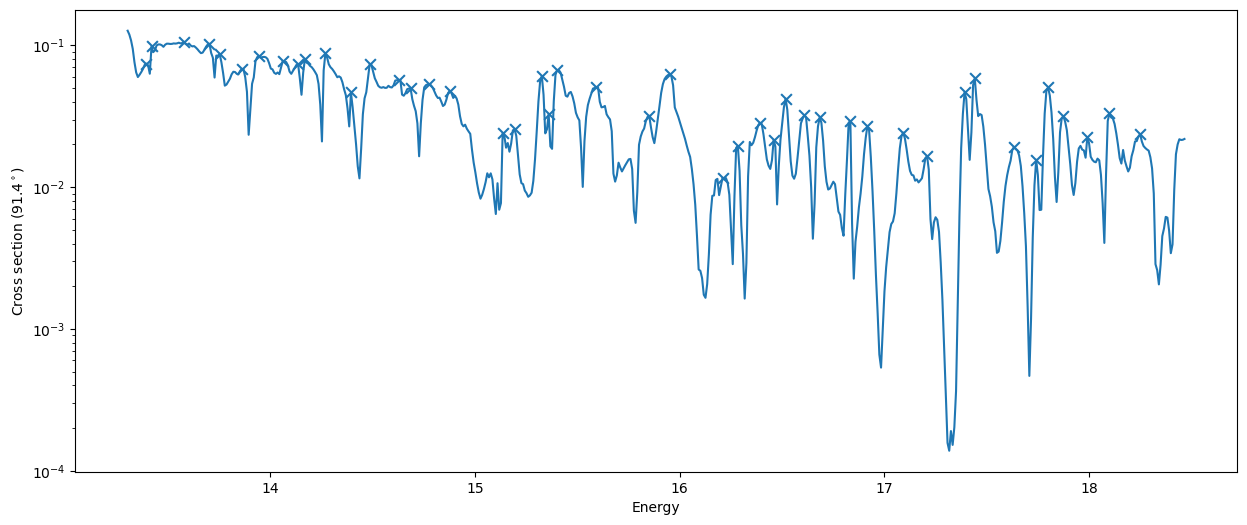

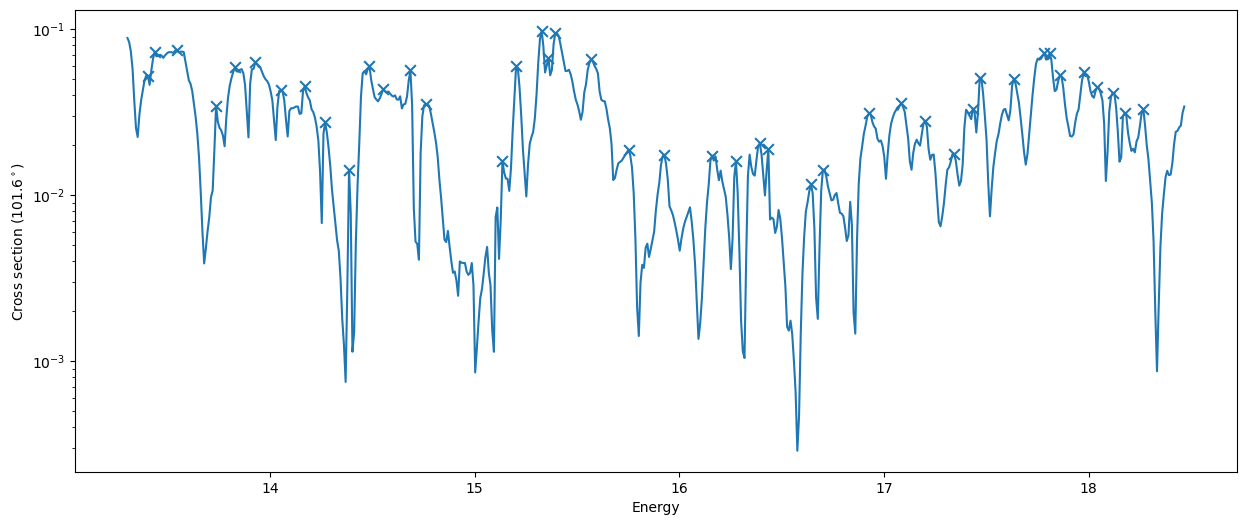

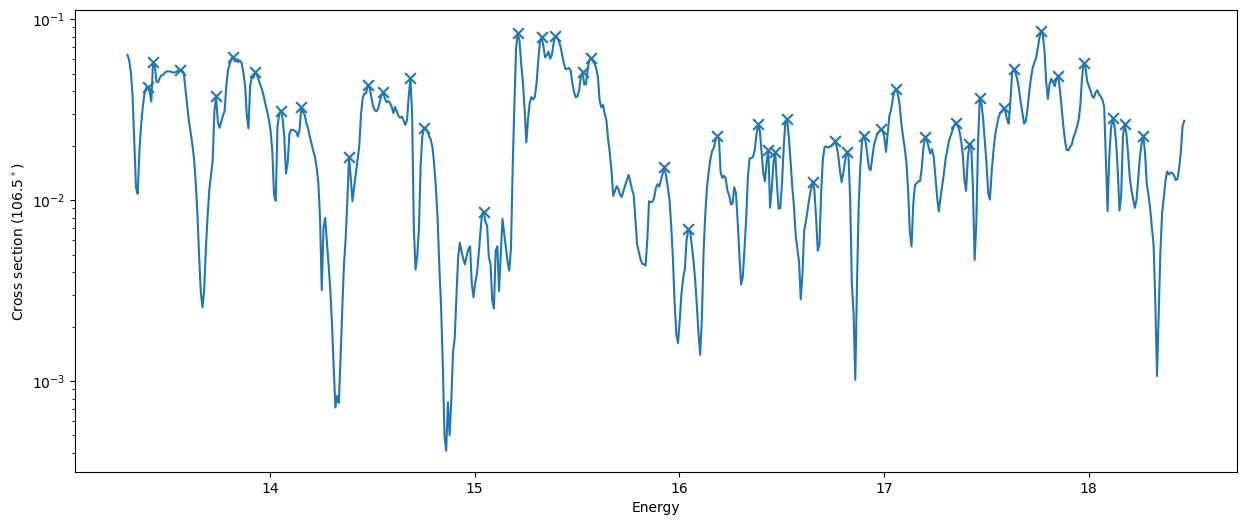

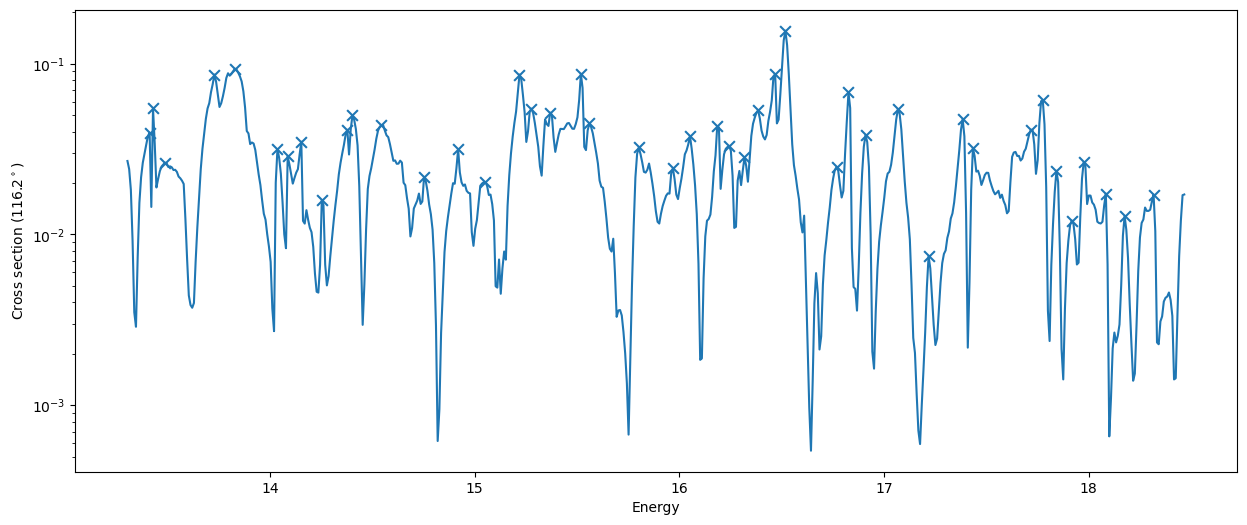

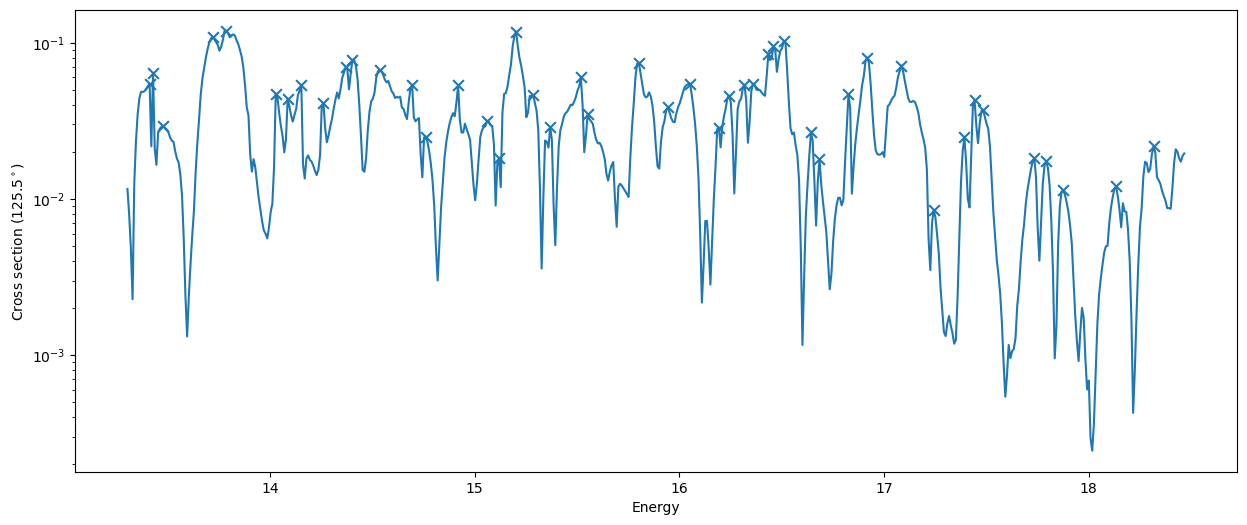

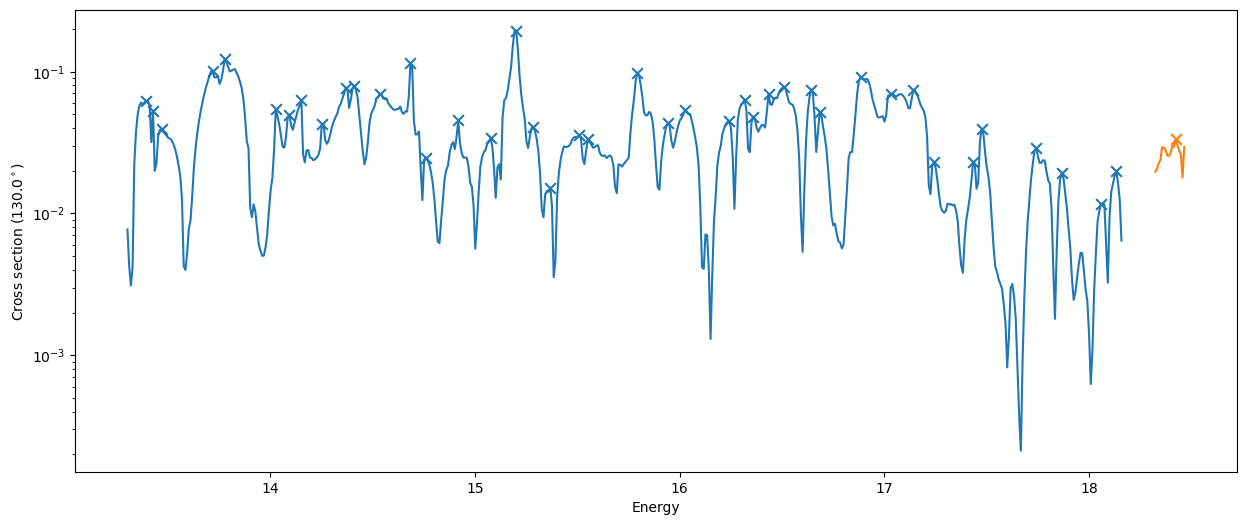

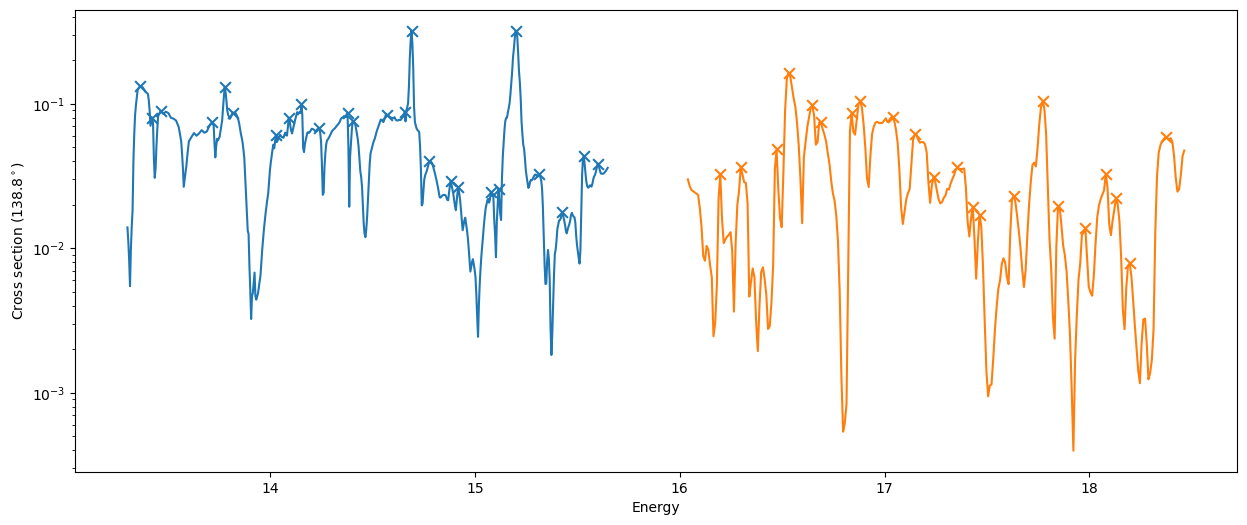

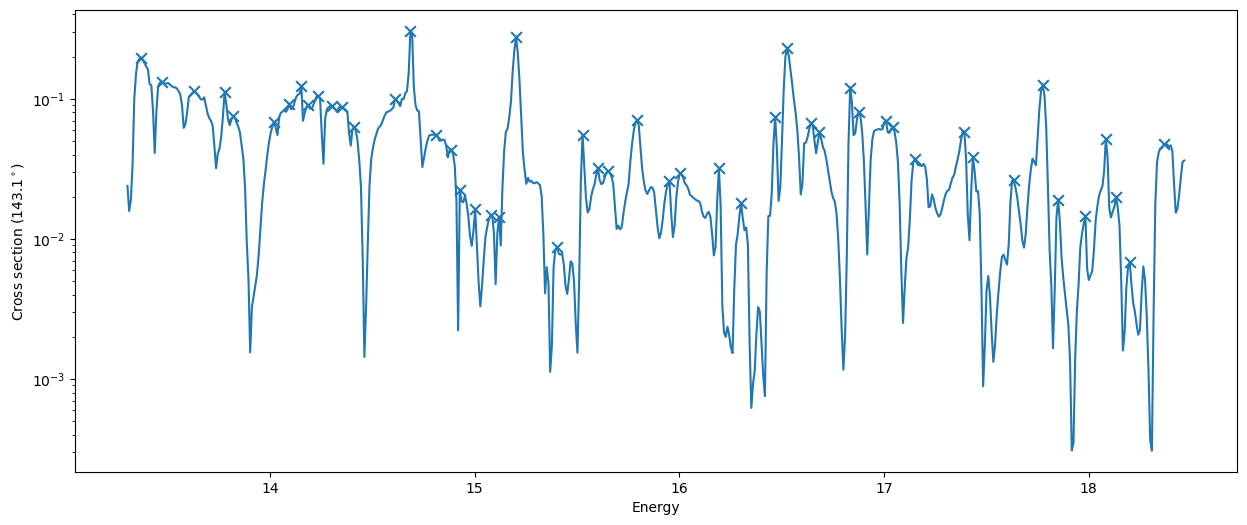

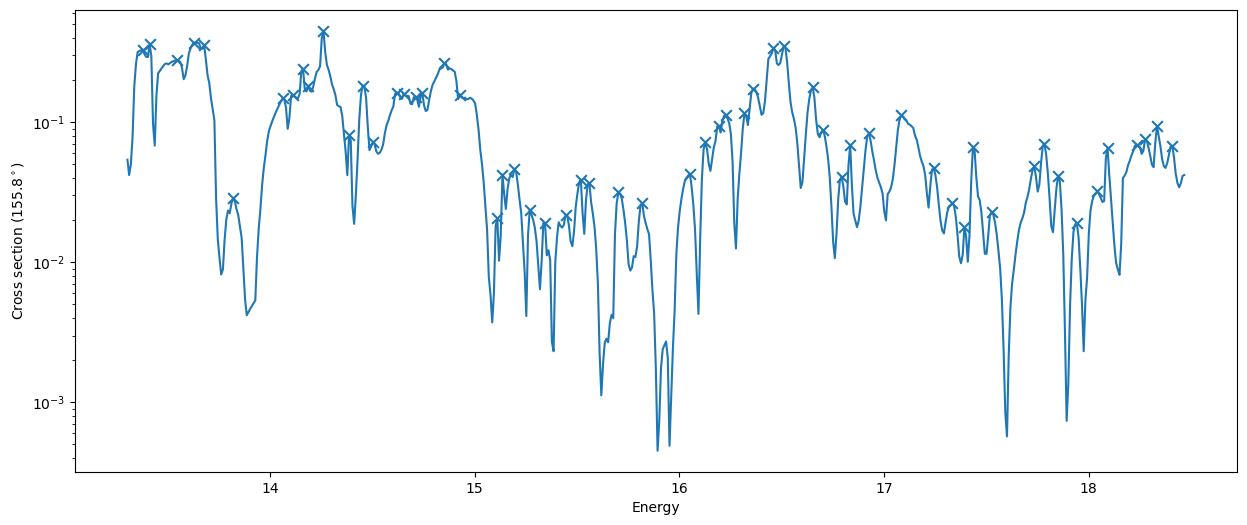

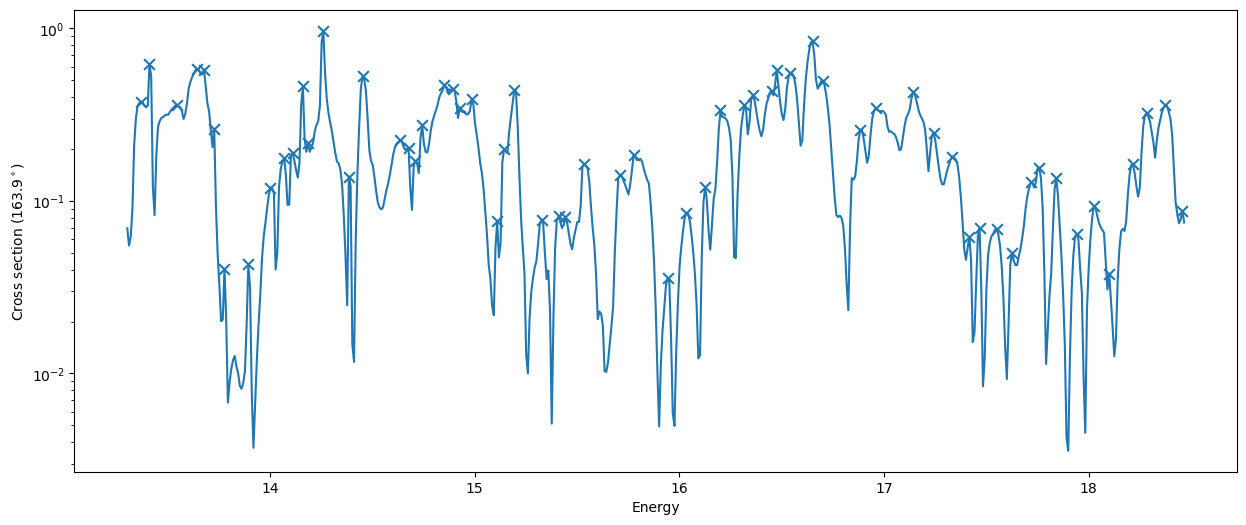

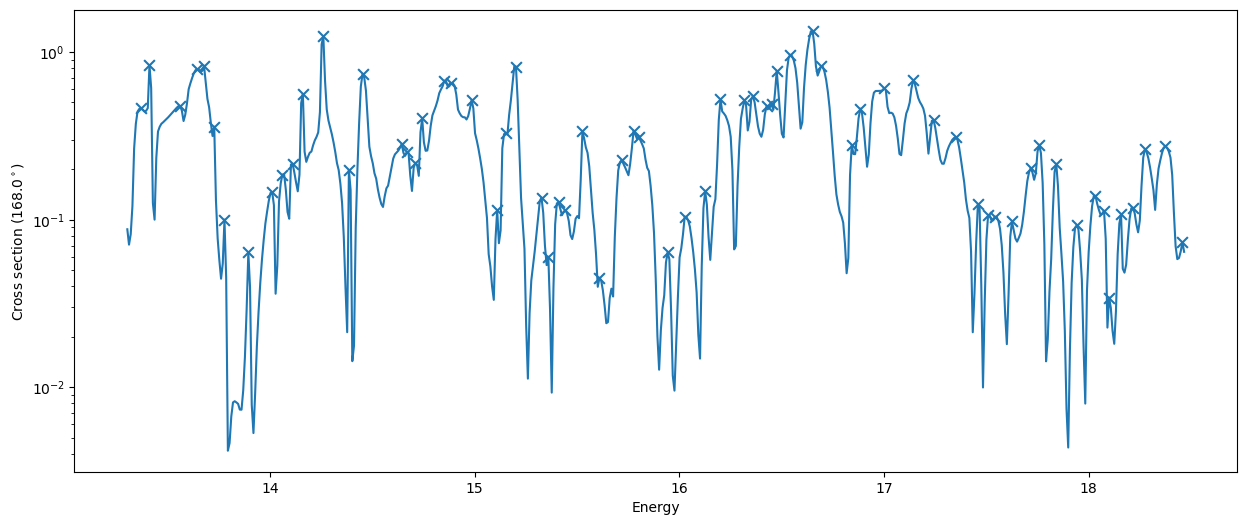

In [6]:
all_cs = functions.get_all_cs(rounded_theta_cm, ke_cm, sigma, dsigma, 9.31)
functions.visualise_all_peaks(all_cs)

In [7]:
clusters, clustered_energies = functions.get_clusters_sort(all_cs)
functions.get_dp_clusters_info(clusters)

number of clusters: 90
1 clusters of size 1
3 clusters of size 2
3 clusters of size 3
4 clusters of size 4
8 clusters of size 5
7 clusters of size 6
6 clusters of size 7
12 clusters of size 8
8 clusters of size 9
10 clusters of size 10
9 clusters of size 11
3 clusters of size 12
5 clusters of size 13
7 clusters of size 14
3 clusters of size 15
1 clusters of size 16
Clusters with repeated angles: 0


In [8]:
peaks = functions.get_all_peaks_lst(all_cs)

num_peaks_lst = [len(angle[1]) for angle in peaks]

print(max(num_peaks_lst), min(num_peaks_lst))


68 32


In [565]:
#for i, energies in enumerate(clustered_energies[:10]):
#    plt.scatter(energies, [i] * len(energies), s=3)

In [510]:
#green: zeroes
#red: maxima 
#functions.visualise_clusters(clusters[54:], 4)

In [233]:
#functions.visualise_clusters(clusters_hdbscan[:7], 3)

In [9]:
clusters_linkage = functions.get_clusters_linkage(all_cs)

In [10]:
print(len(clusters_linkage))

89


In [352]:
#functions.visualise_clusters(clusters_linkage[18:], 4)

In [11]:
clusters_midpoints, partition_midpoints = functions.get_clusters_midpoints(all_cs)

In [12]:
#print(partition_midpoints)
functions.get_dp_clusters_info(clusters_midpoints)

number of clusters: 117
6 clusters of size 1
8 clusters of size 2
9 clusters of size 3
12 clusters of size 4
12 clusters of size 5
12 clusters of size 6
12 clusters of size 7
10 clusters of size 8
11 clusters of size 9
9 clusters of size 10
3 clusters of size 11
5 clusters of size 12
5 clusters of size 13
2 clusters of size 14
1 clusters of size 15
Clusters with repeated angles: 0


In [540]:
#functions.visualise_clusters(clusters_midpoints[106:], 6)

In [13]:
repeat_a_factors = [0.001, 0.005, 0.01]

for i in repeat_a_factors:
    add_c_factors = [i + n*0.001 for n in range(5)]
    for j in add_c_factors:
        print("repeat_p= {}, new_cluster_p = {}".format(i, j))
        clusters_dp = functions.get_clusters_dp(all_cs, i, j)
        functions.get_dp_clusters_info(clusters_dp)

repeat_p= 0.001, new_cluster_p = 0.001
number of clusters: 783
783 clusters of size 1
Clusters with repeated angles: 0
repeat_p= 0.001, new_cluster_p = 0.002
number of clusters: 673
580 clusters of size 1
76 clusters of size 2
17 clusters of size 3
Clusters with repeated angles: 0
repeat_p= 0.001, new_cluster_p = 0.003
number of clusters: 122
3 clusters of size 2
20 clusters of size 3
10 clusters of size 4
16 clusters of size 5
22 clusters of size 6
13 clusters of size 7
13 clusters of size 8
6 clusters of size 9
6 clusters of size 10
5 clusters of size 11
5 clusters of size 12
2 clusters of size 13
1 clusters of size 15
Clusters with repeated angles: 14
repeat_p= 0.001, new_cluster_p = 0.004
number of clusters: 102
2 clusters of size 2
6 clusters of size 3
8 clusters of size 4
11 clusters of size 5
11 clusters of size 6
15 clusters of size 7
13 clusters of size 8
11 clusters of size 9
4 clusters of size 10
6 clusters of size 11
8 clusters of size 12
4 clusters of size 13
1 clusters of

In [14]:
clusters_dp_chosen = functions.get_clusters_dp(all_cs, 0.001, 0.005)

In [564]:
functions.get_dp_clusters_info(clusters_dp_chosen)

number of clusters: 92
1 clusters of size 2
1 clusters of size 3
6 clusters of size 4
10 clusters of size 5
11 clusters of size 6
13 clusters of size 7
12 clusters of size 8
11 clusters of size 9
4 clusters of size 10
5 clusters of size 11
6 clusters of size 12
4 clusters of size 13
2 clusters of size 14
2 clusters of size 15
1 clusters of size 16
1 clusters of size 17
2 clusters of size 21
Clusters with repeated angles: 28


In [18]:
#functions.visualise_clusters(clusters_dp_chosen, 5)

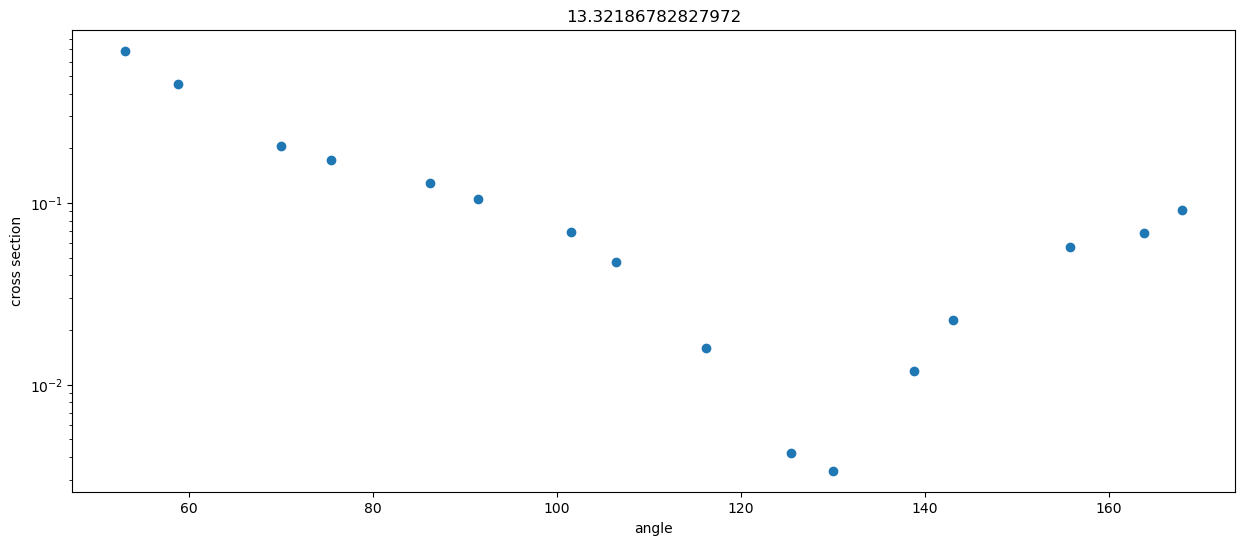

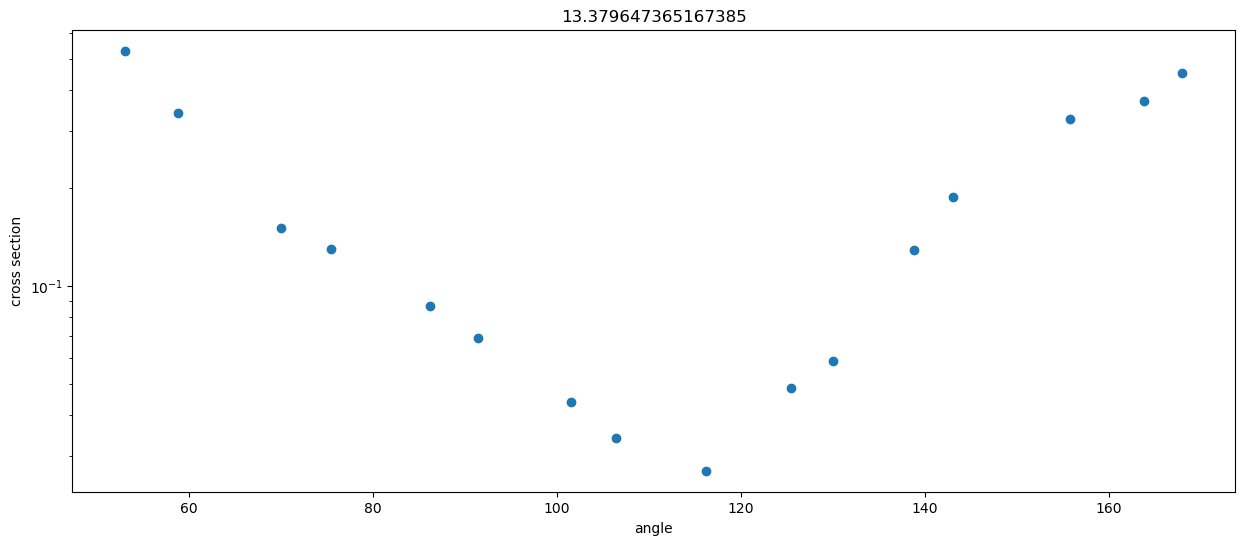

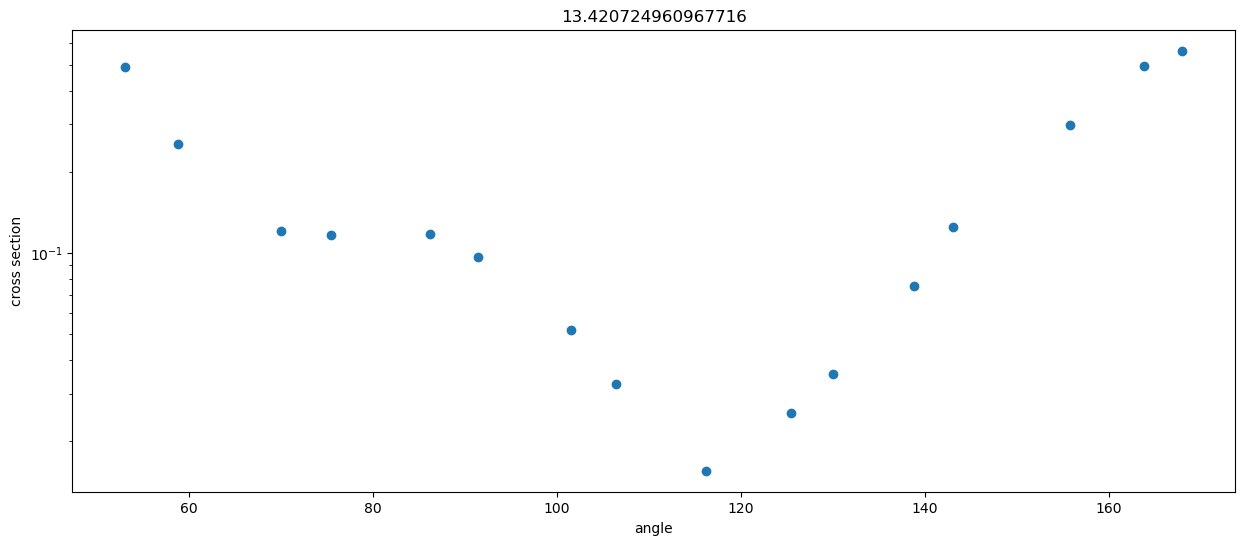

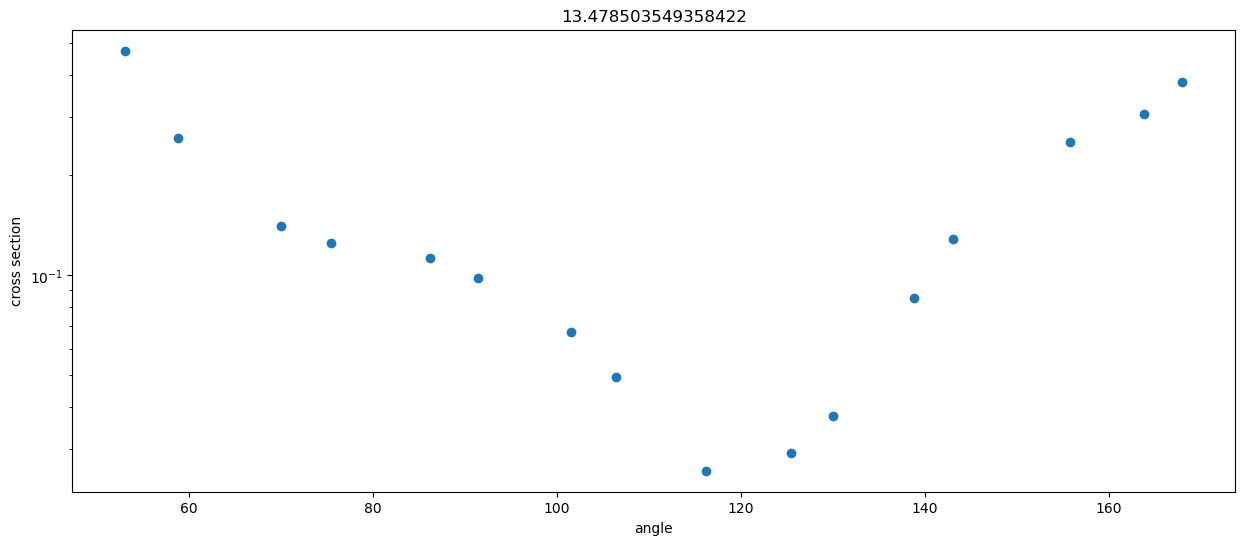

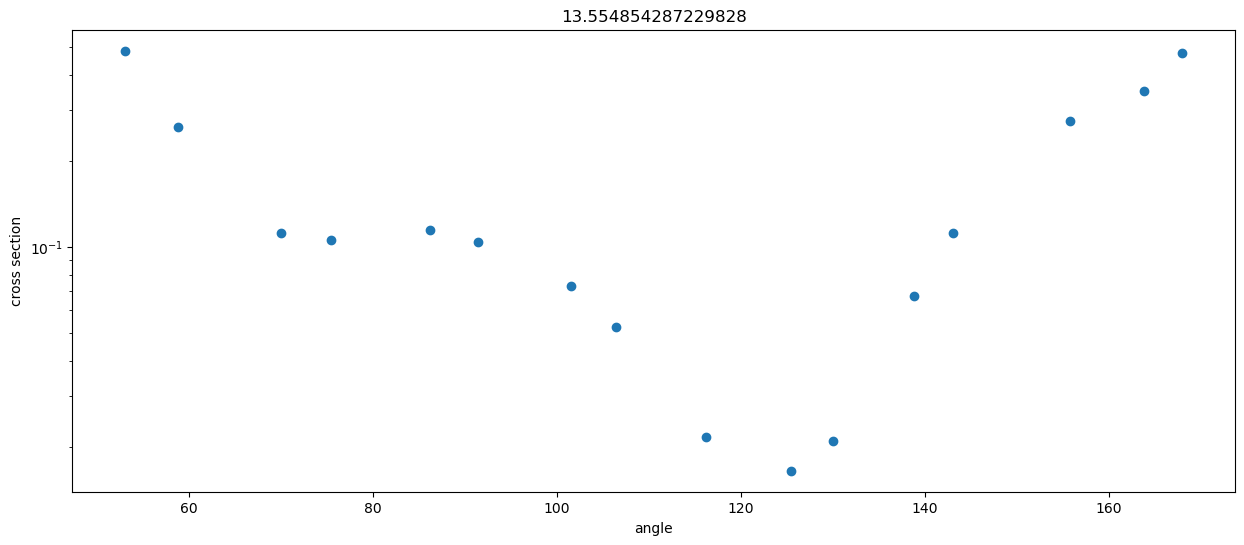

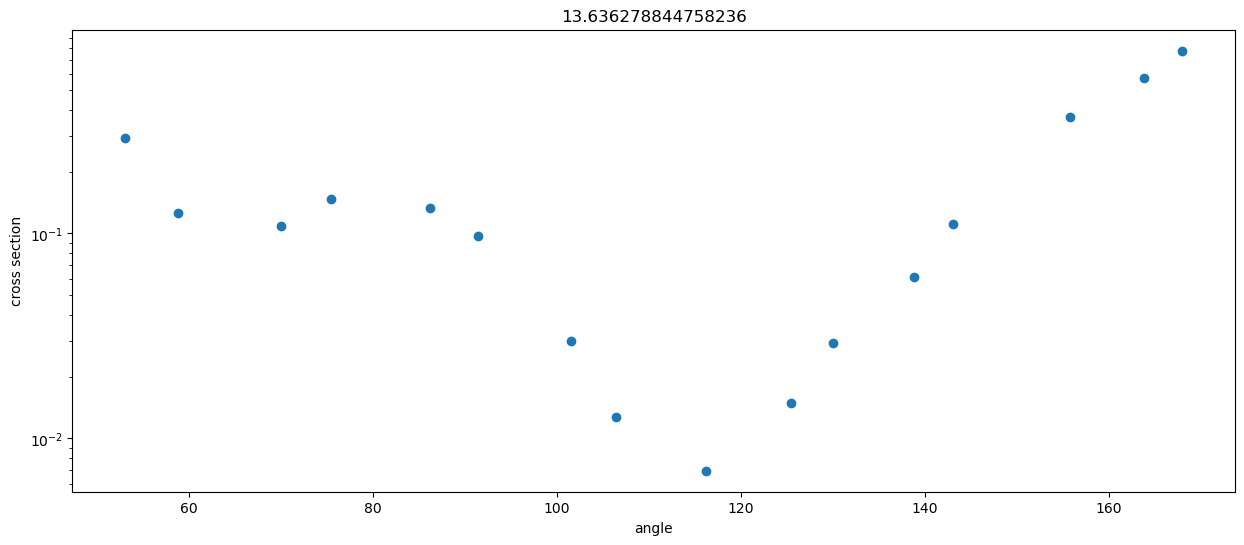

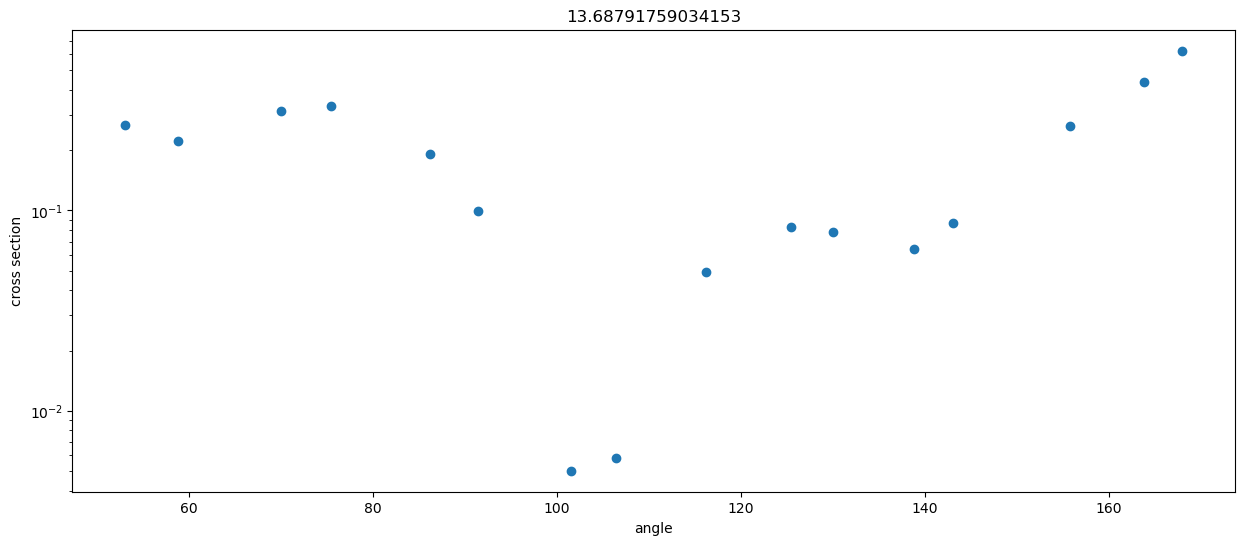

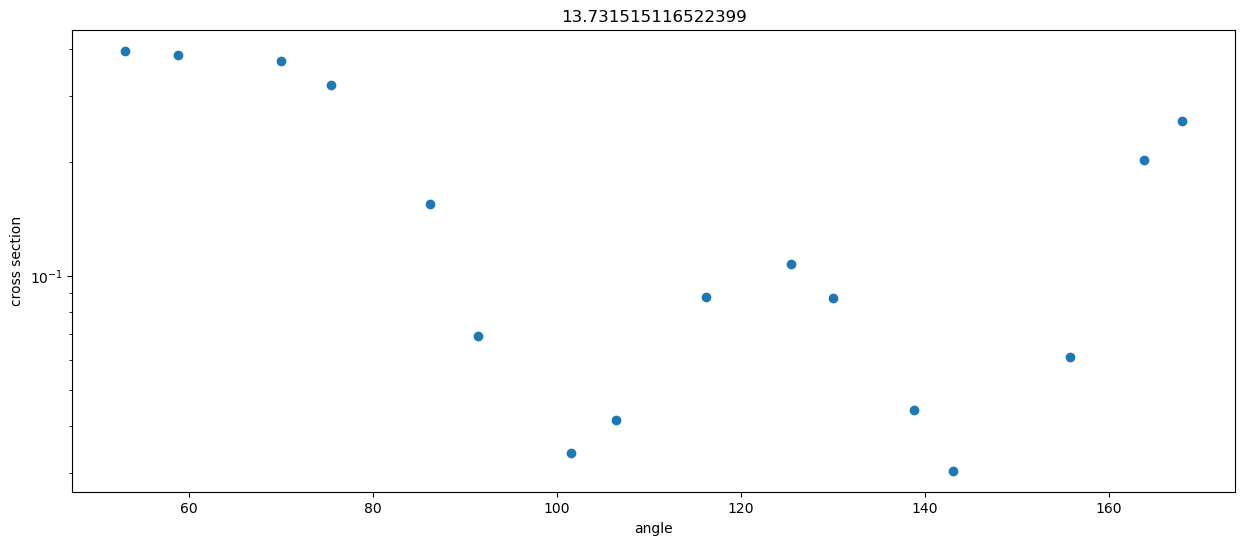

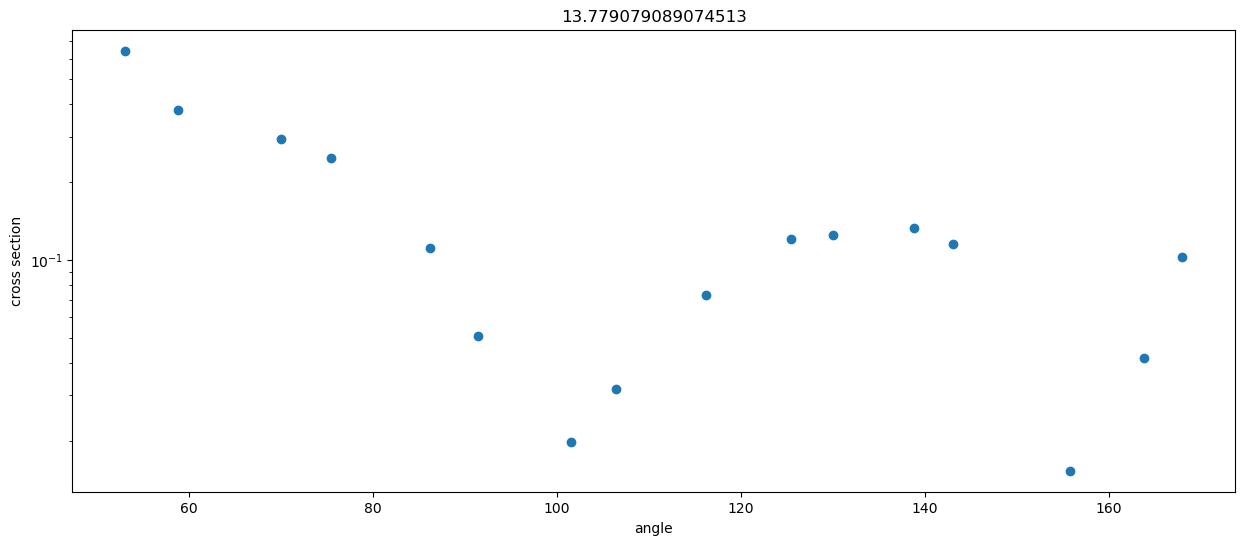

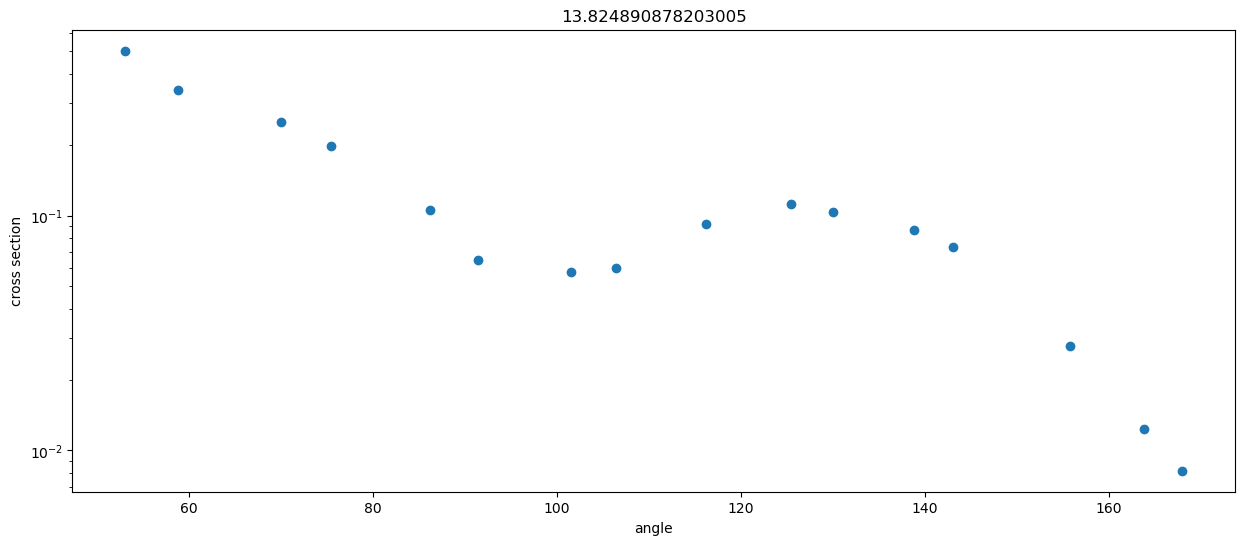

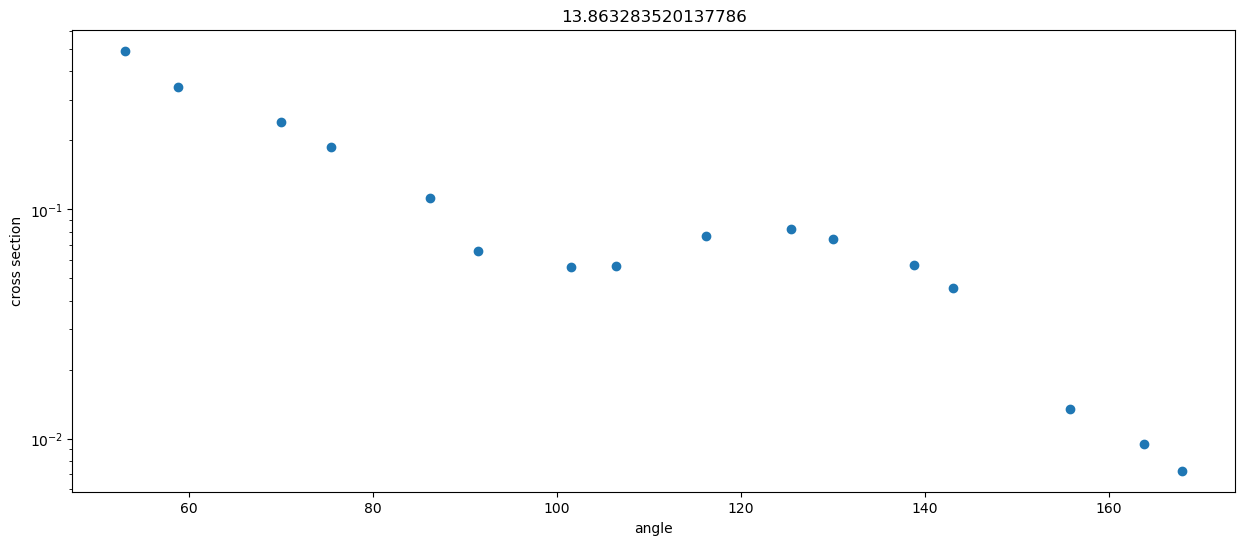

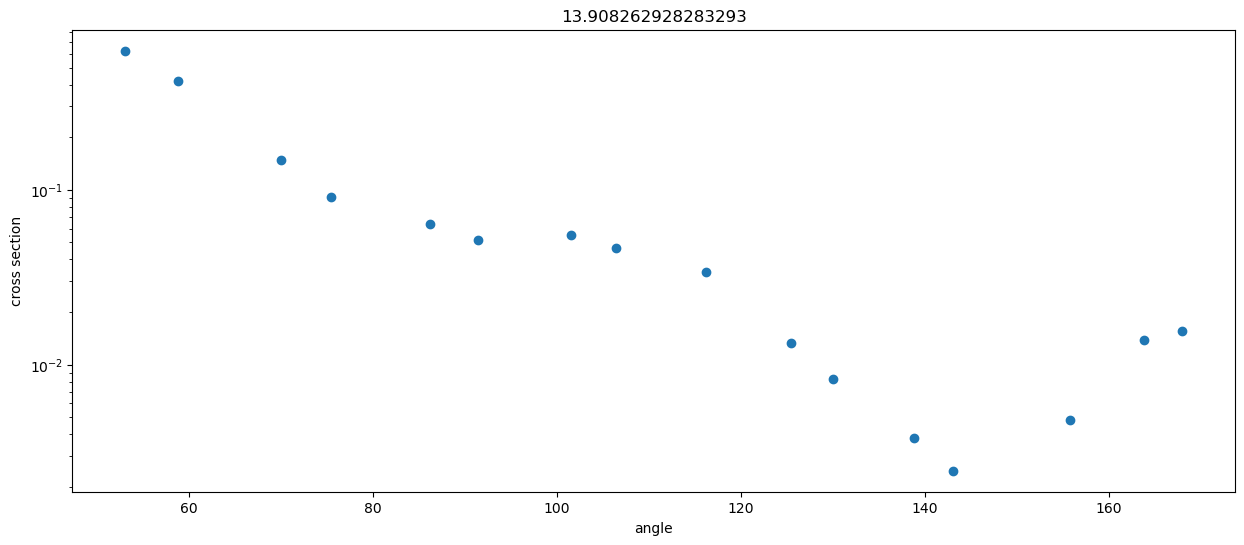

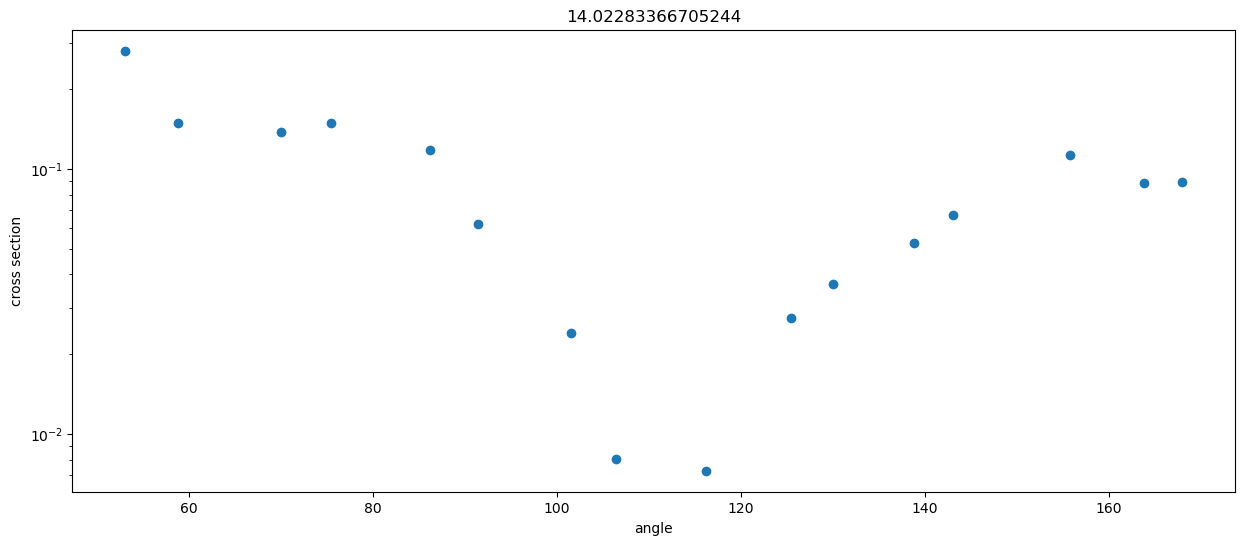

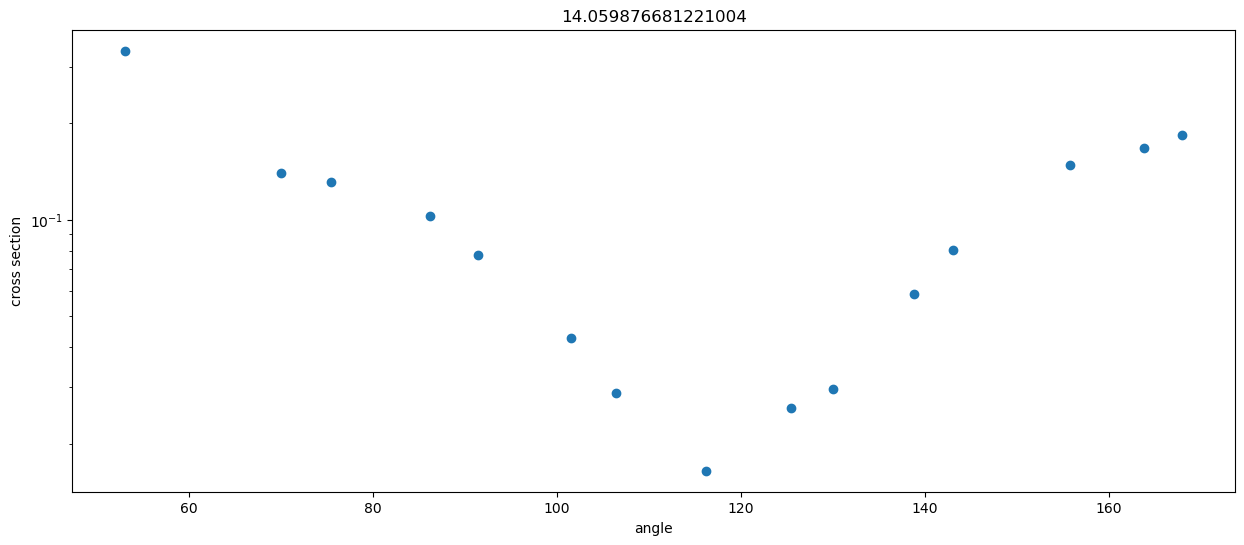

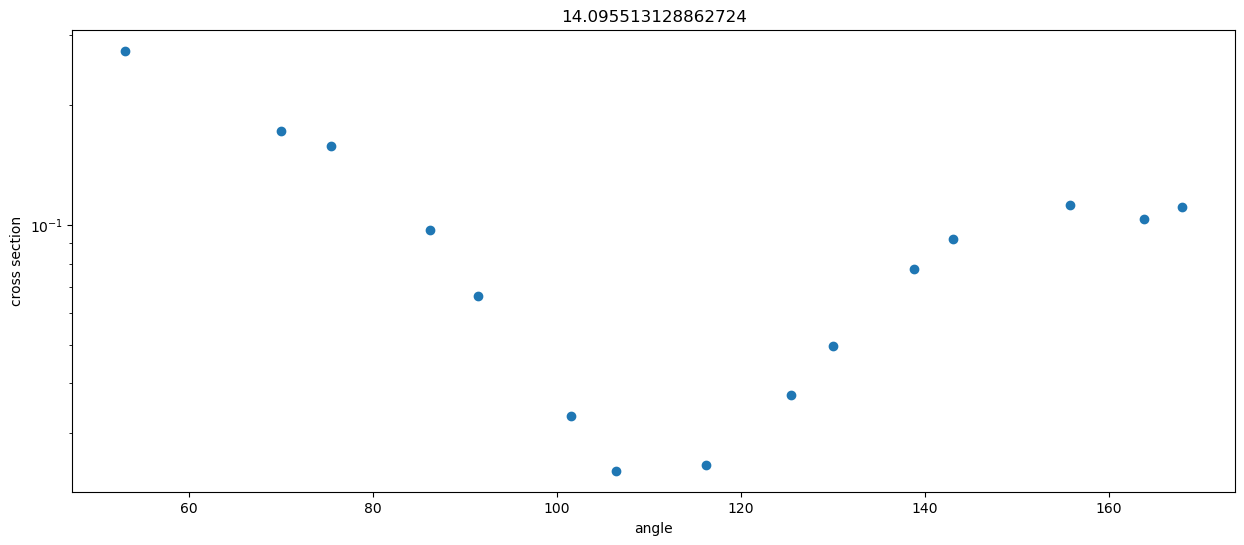

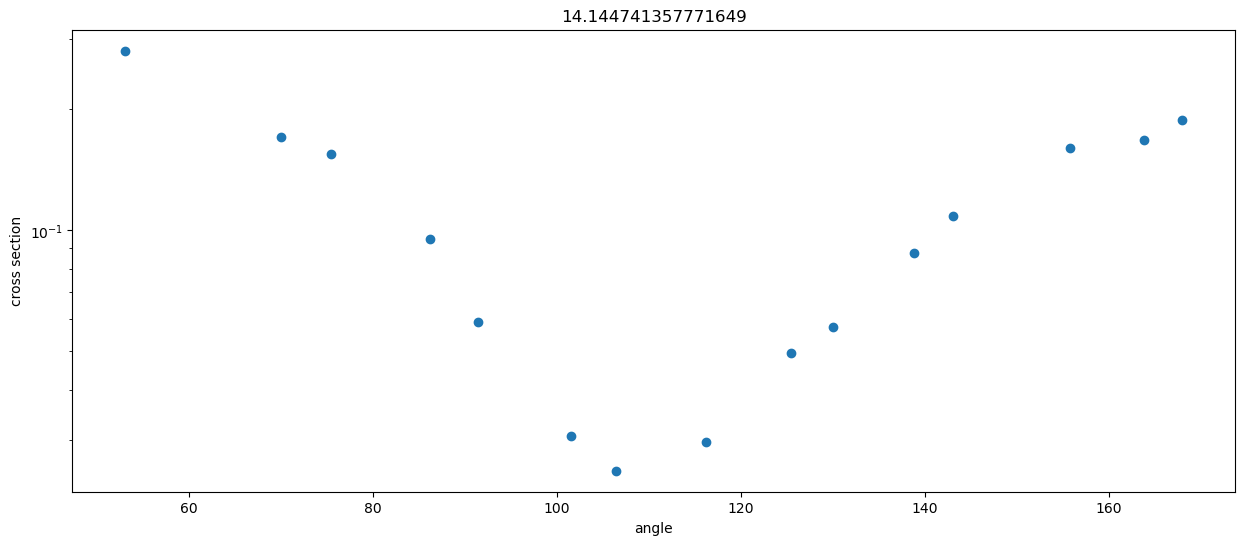

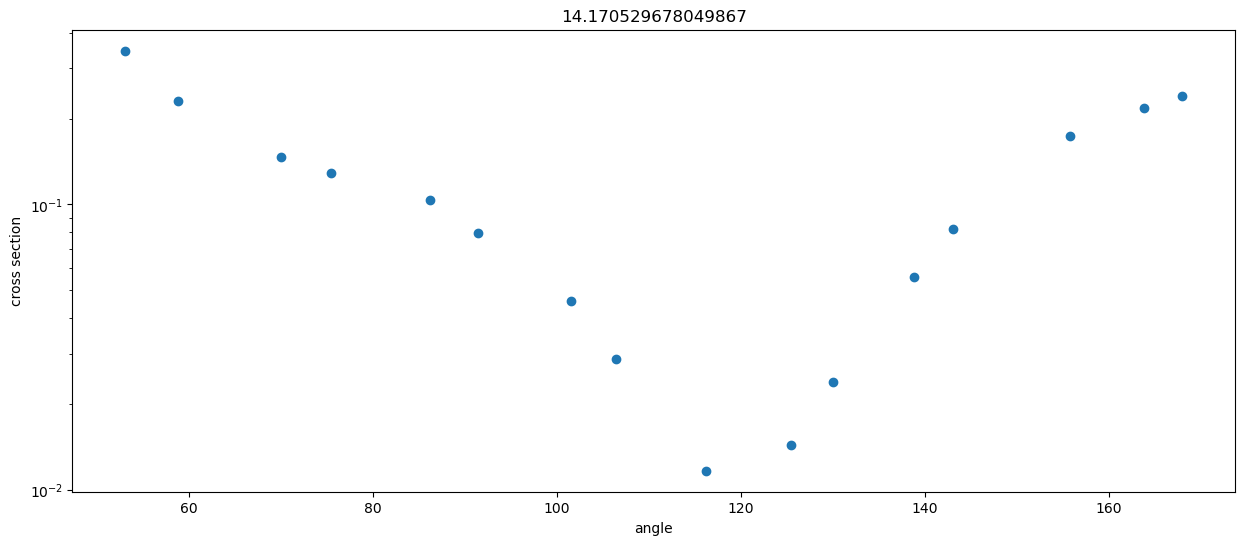

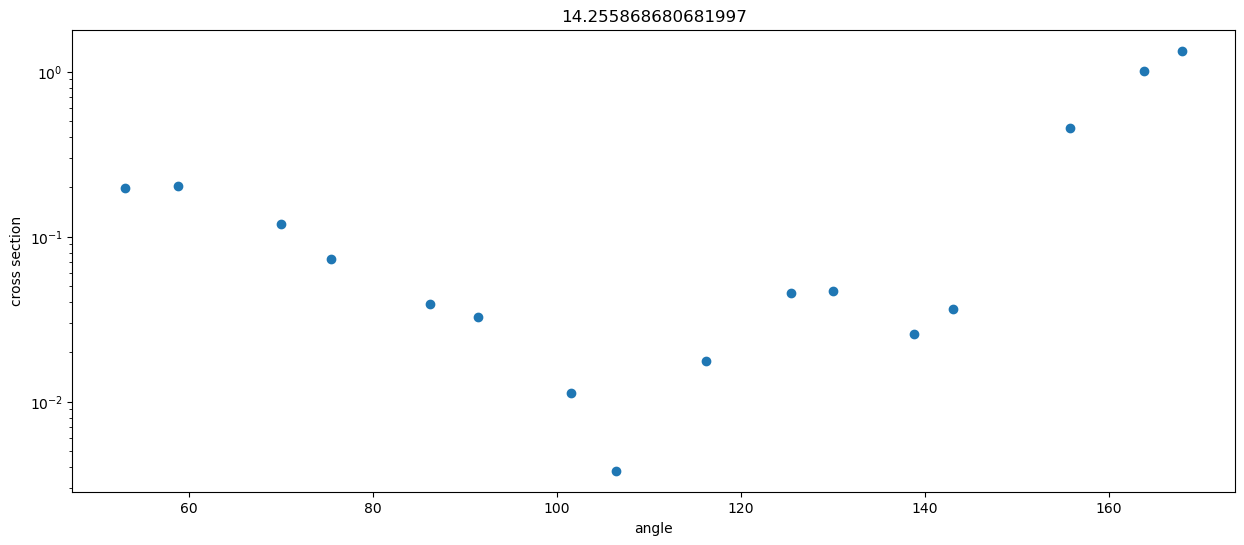

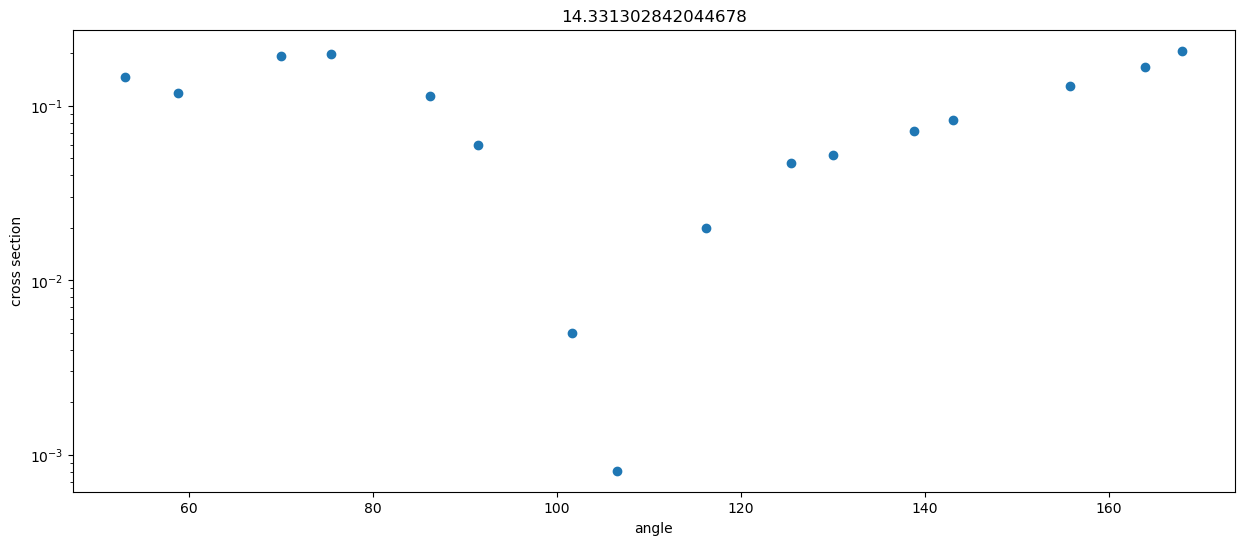

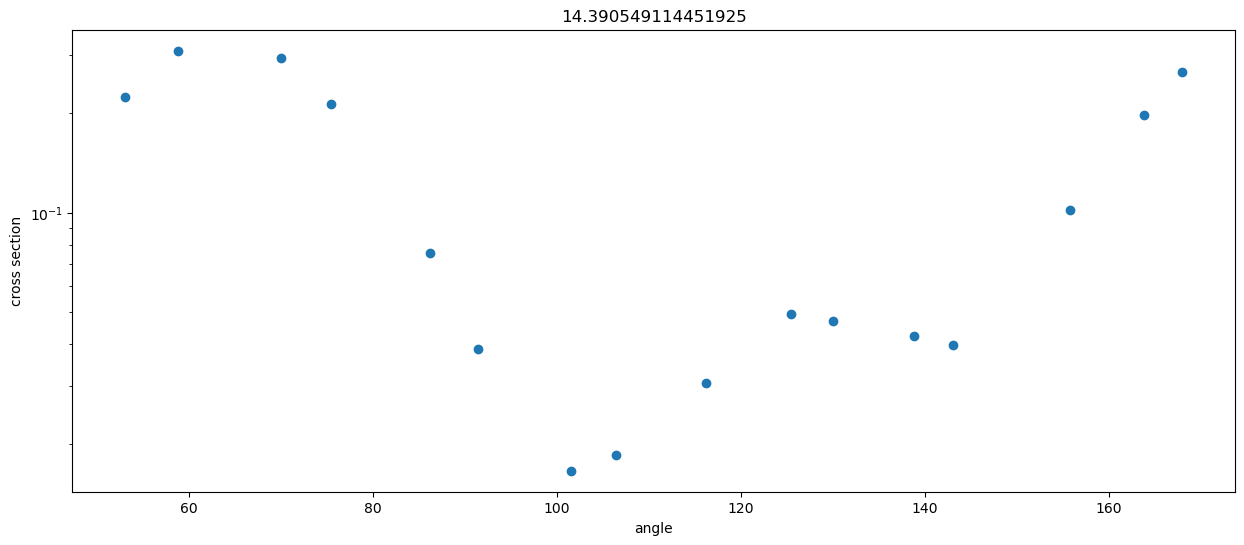

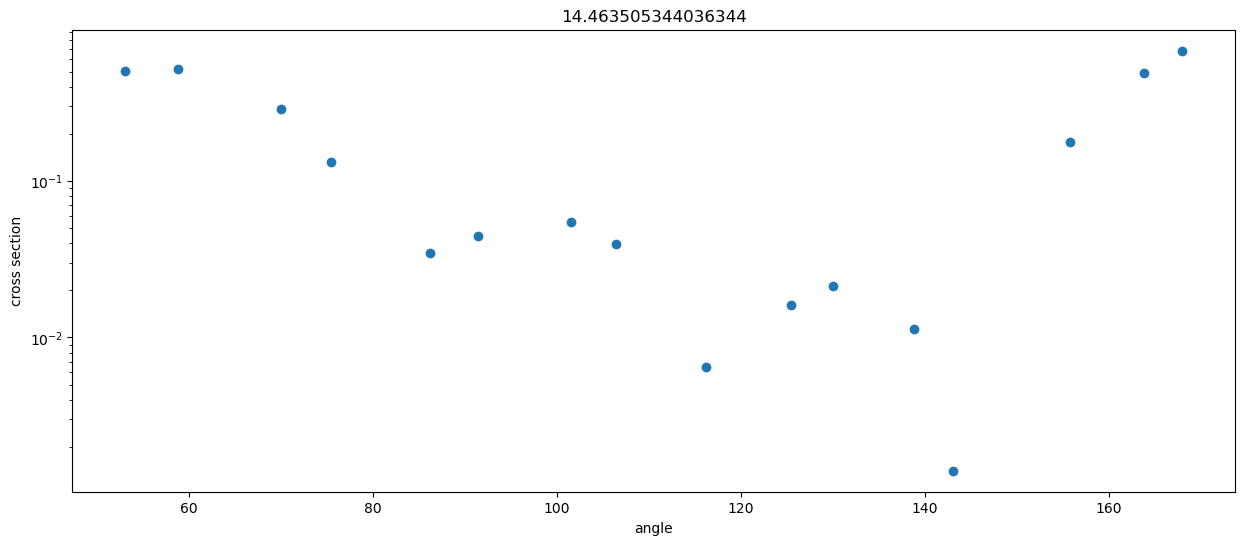

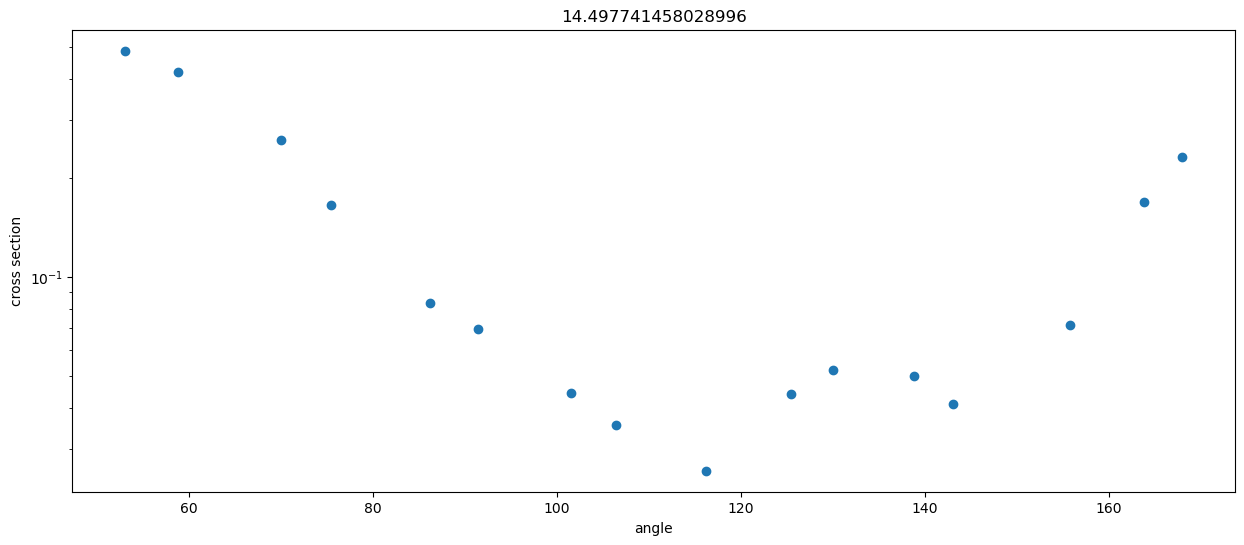

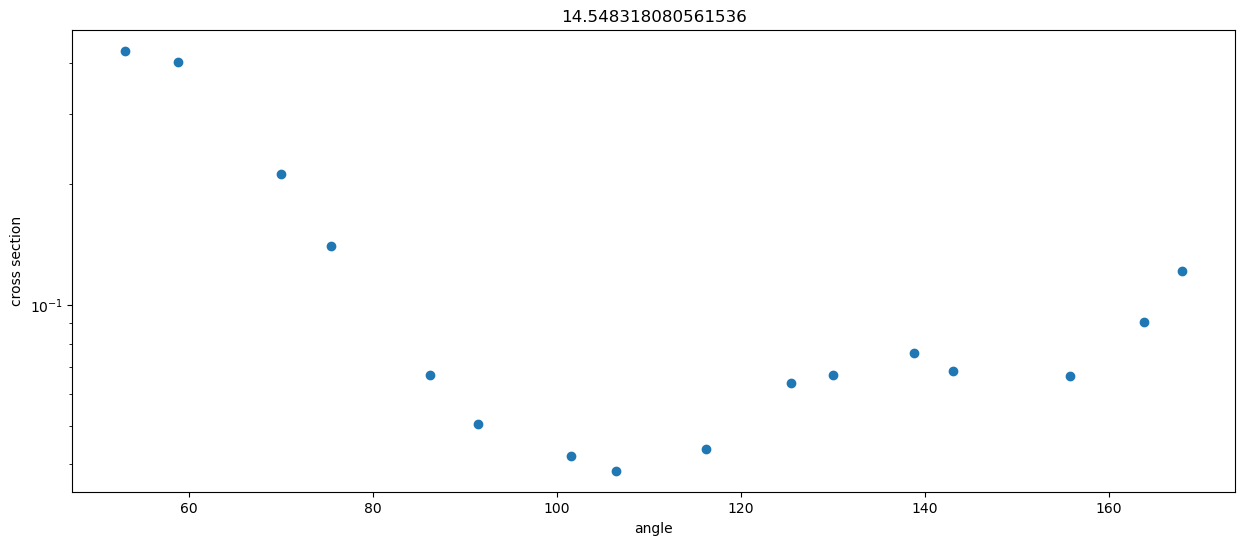

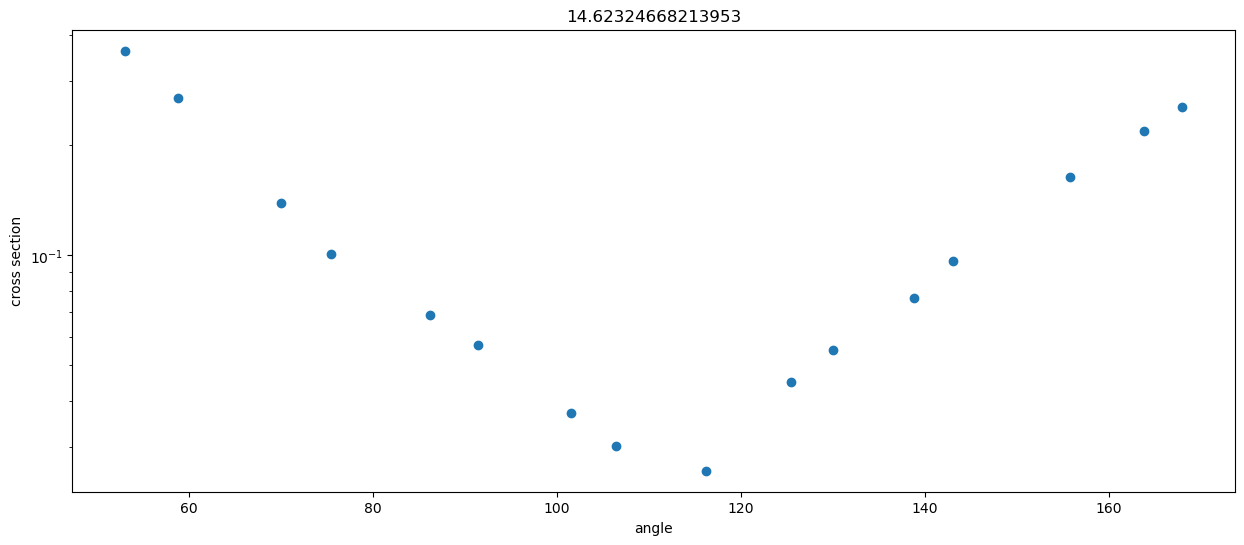

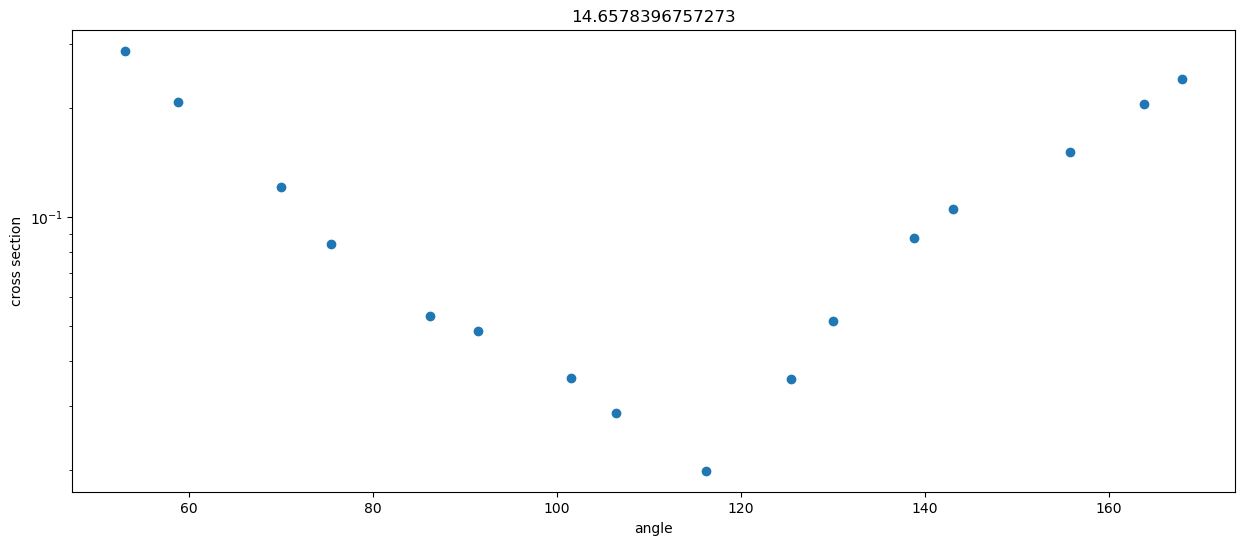

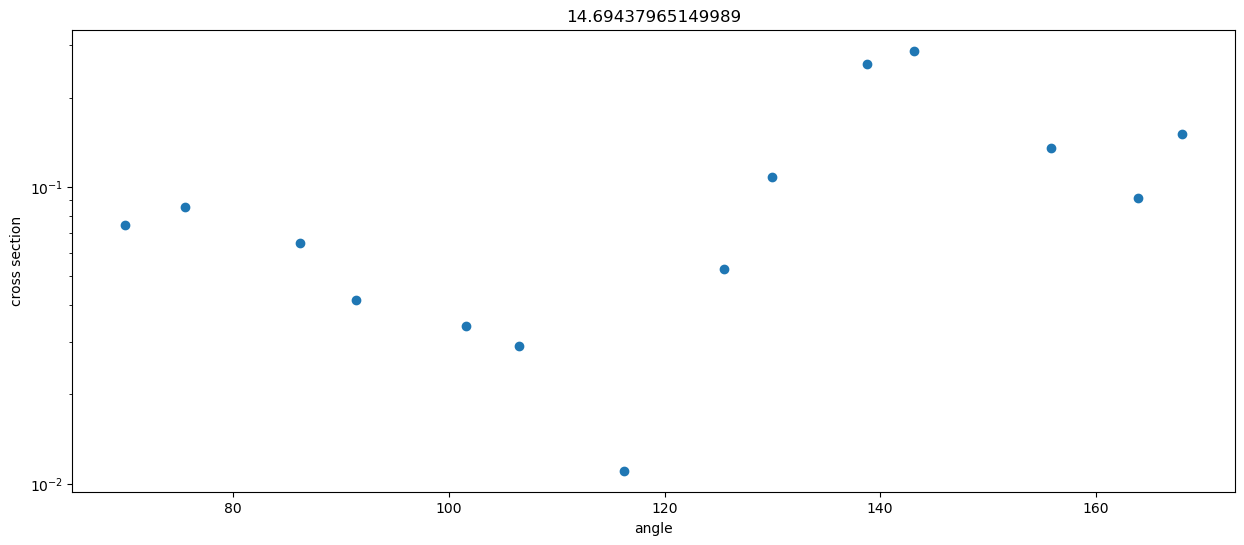

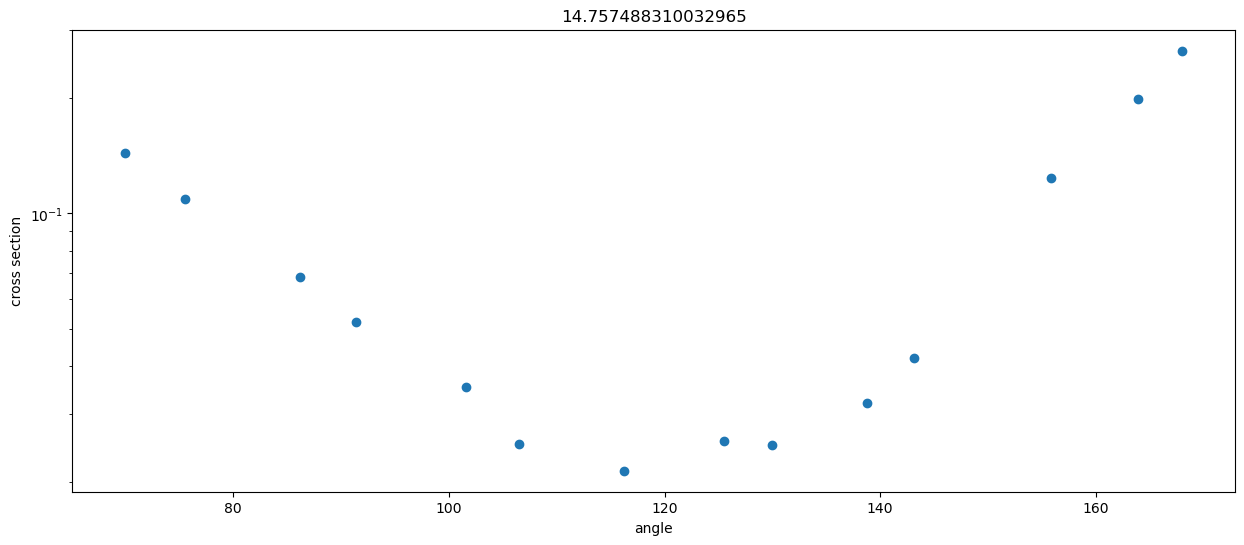

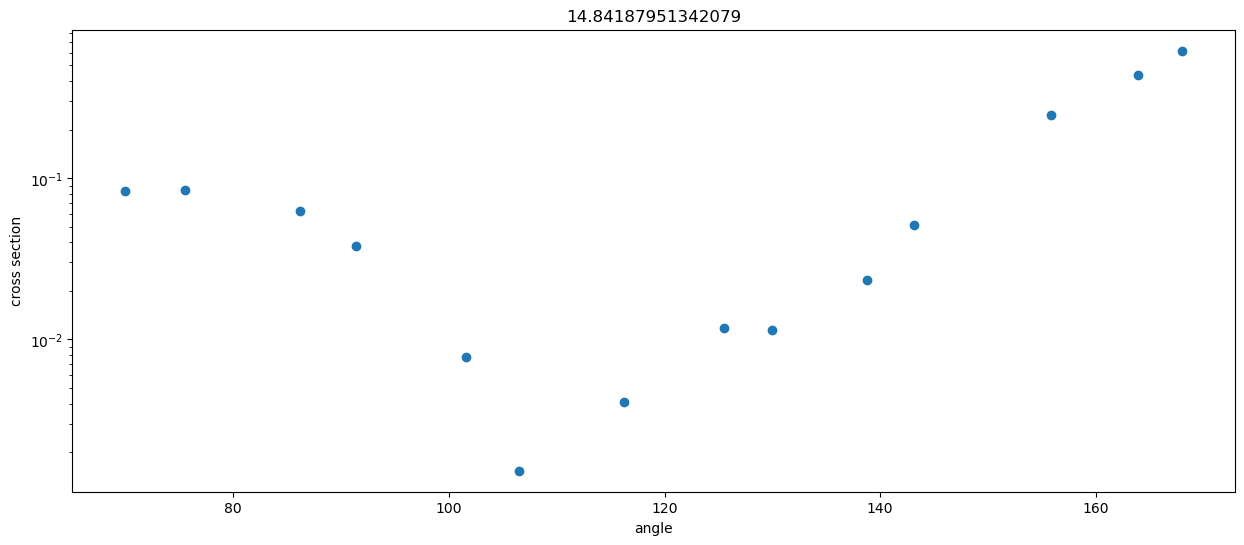

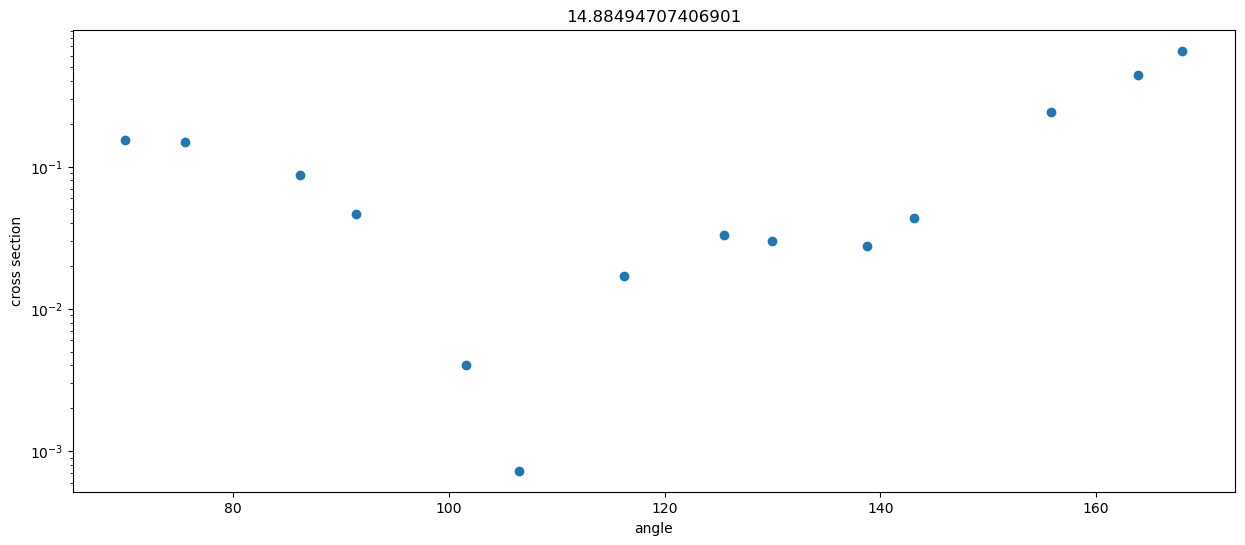

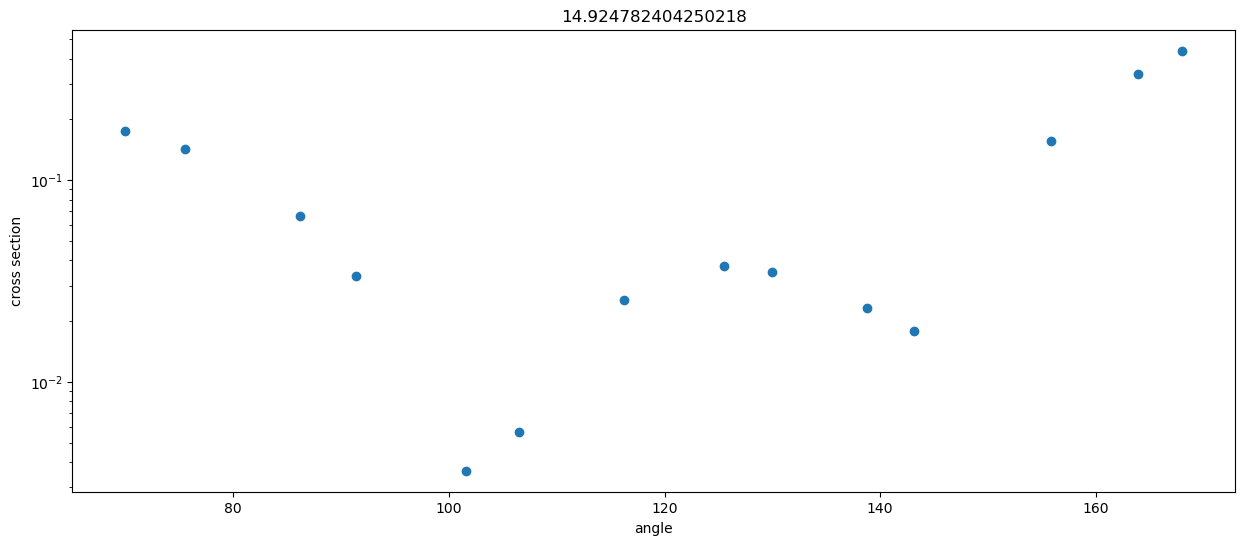

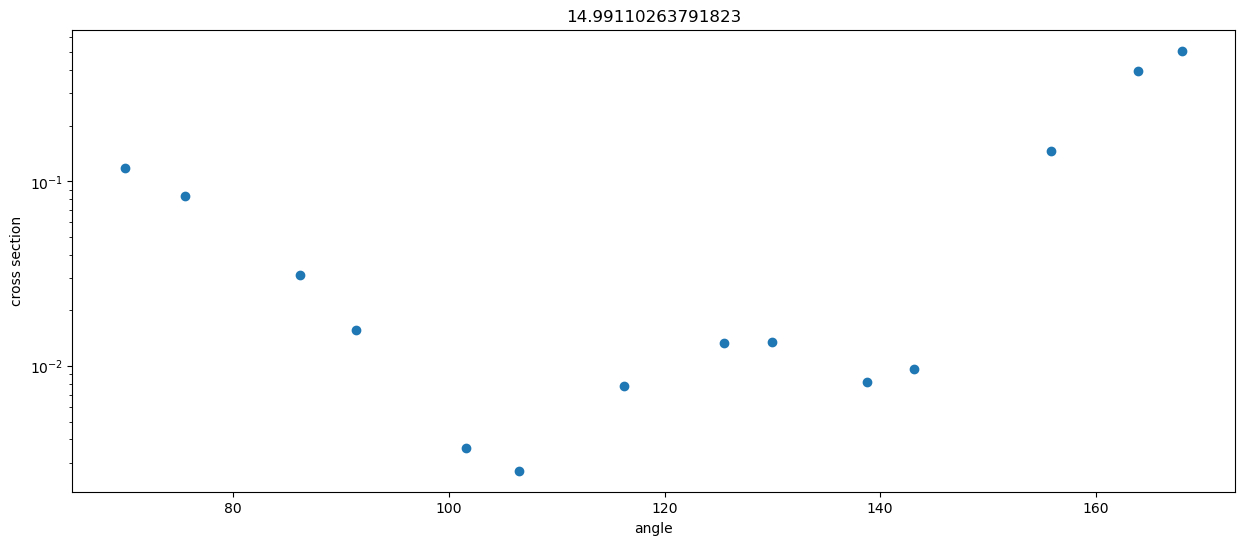

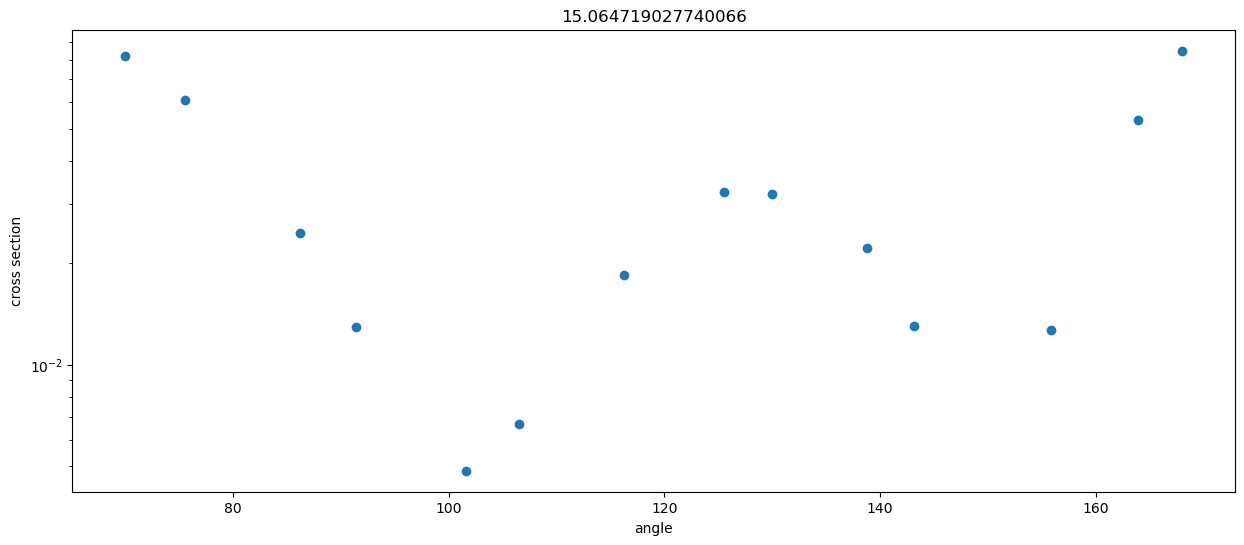

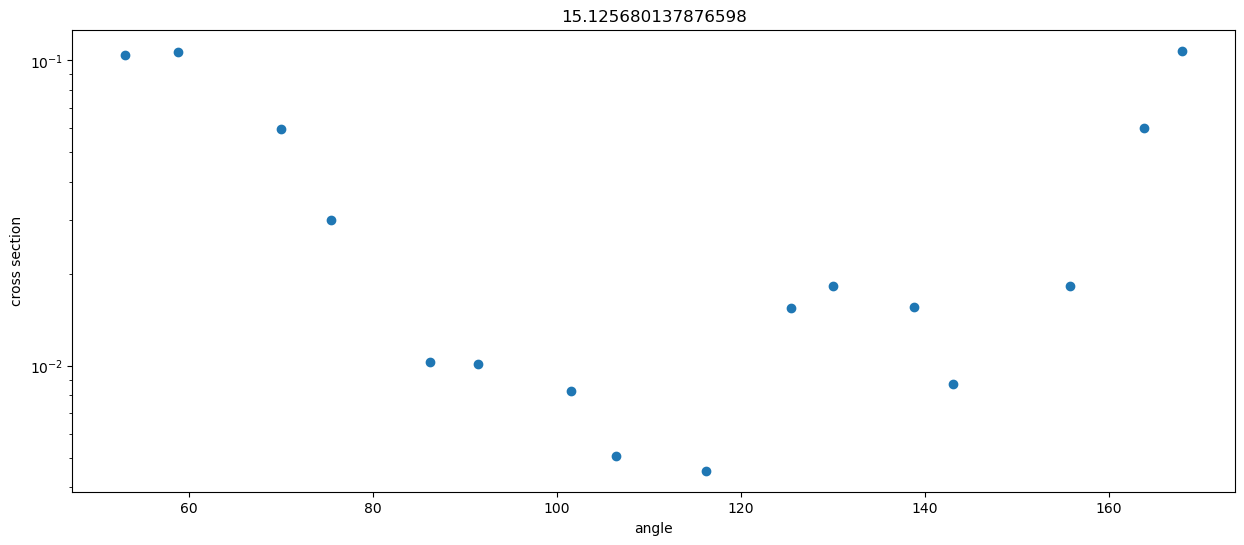

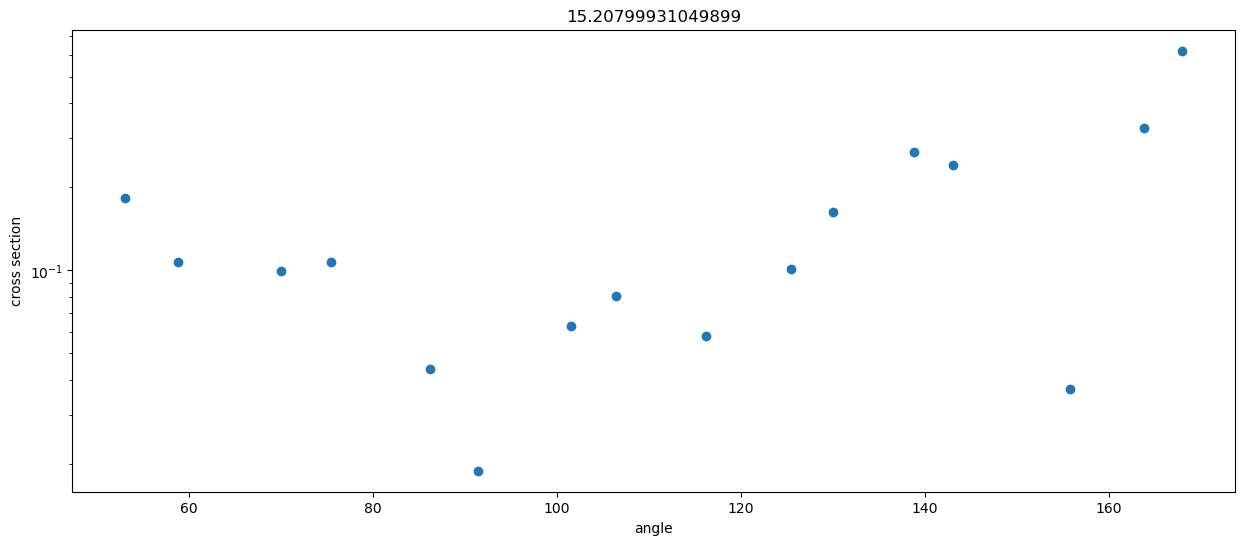

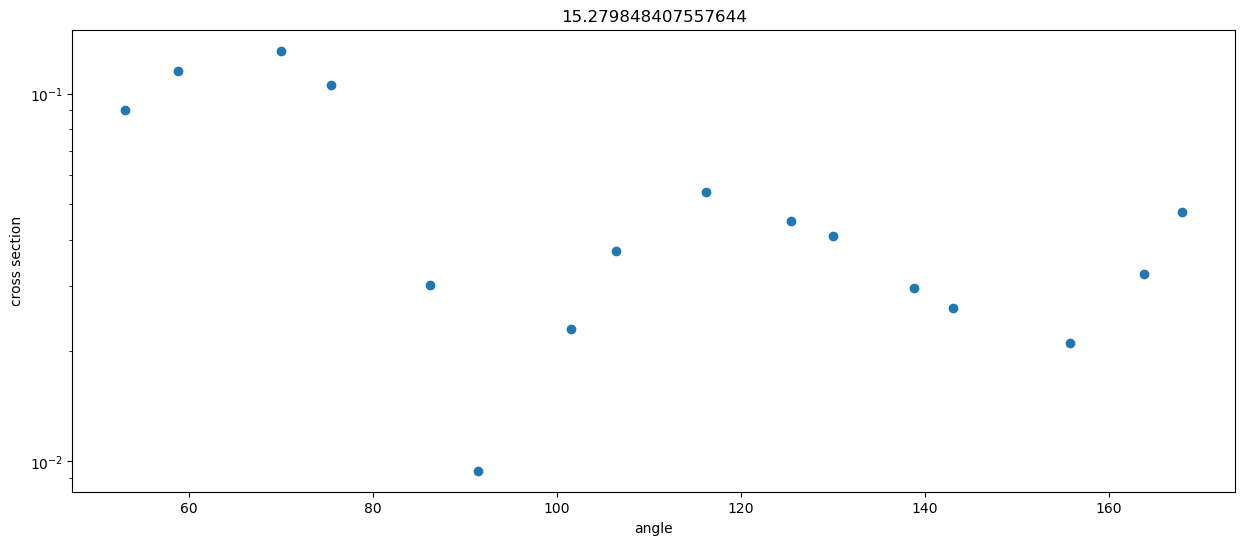

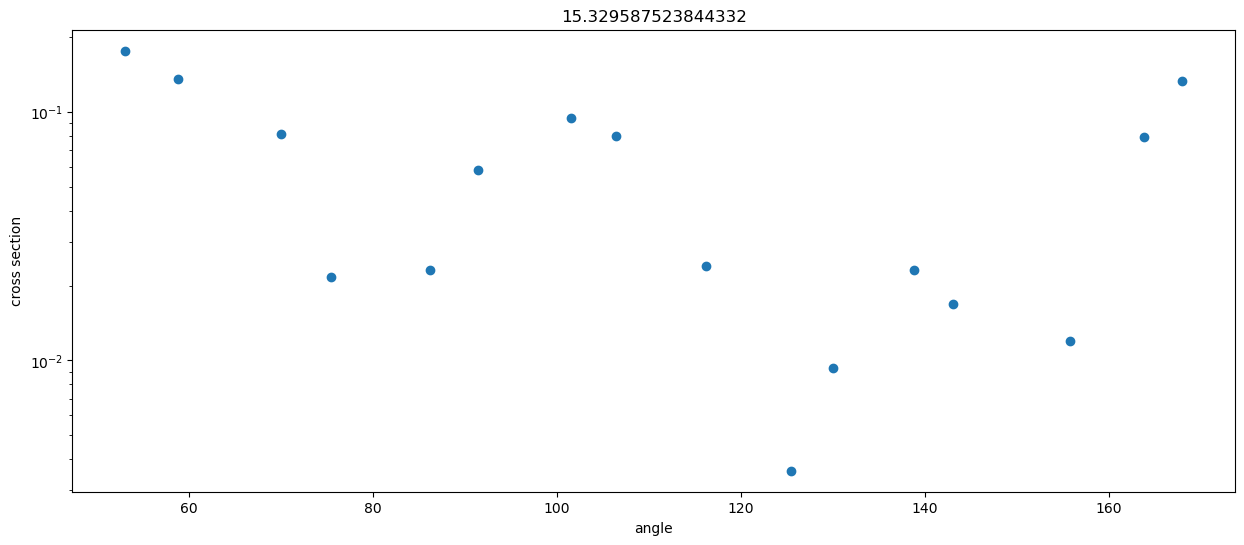

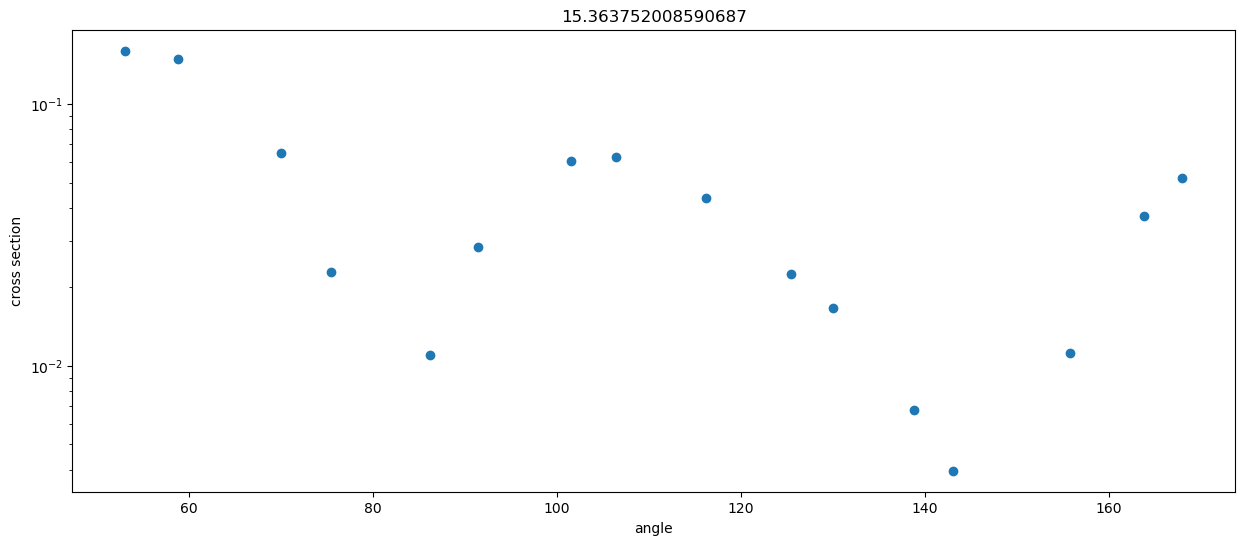

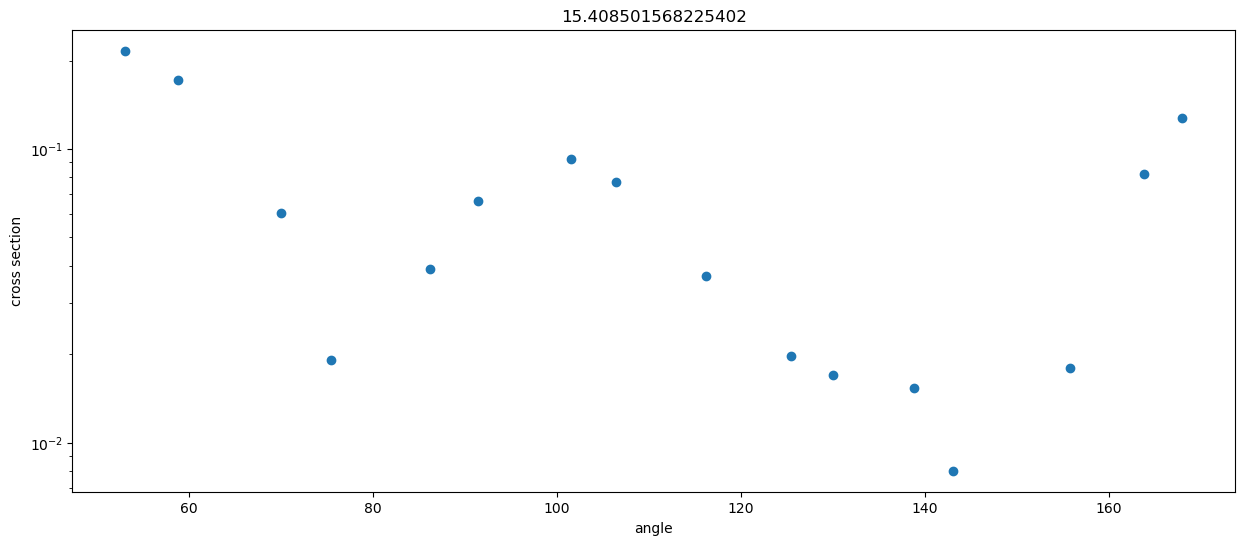

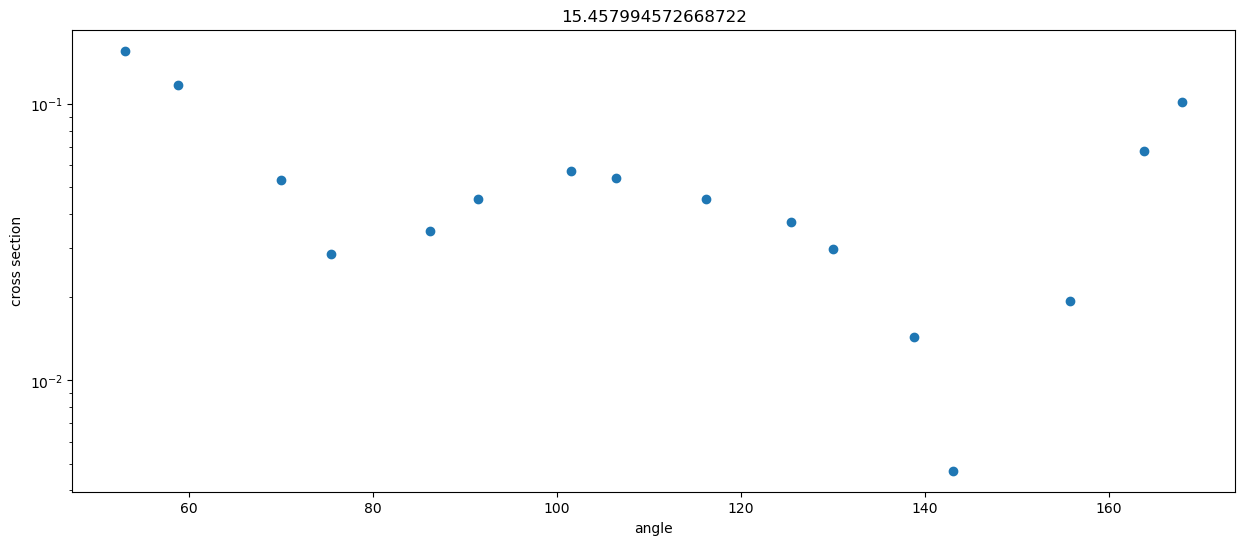

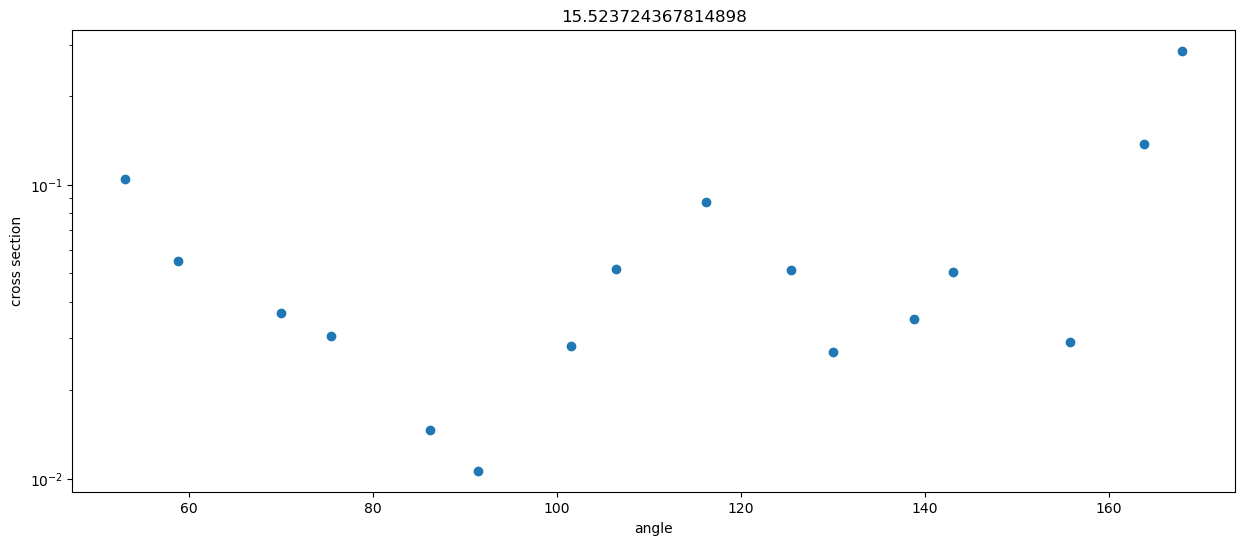

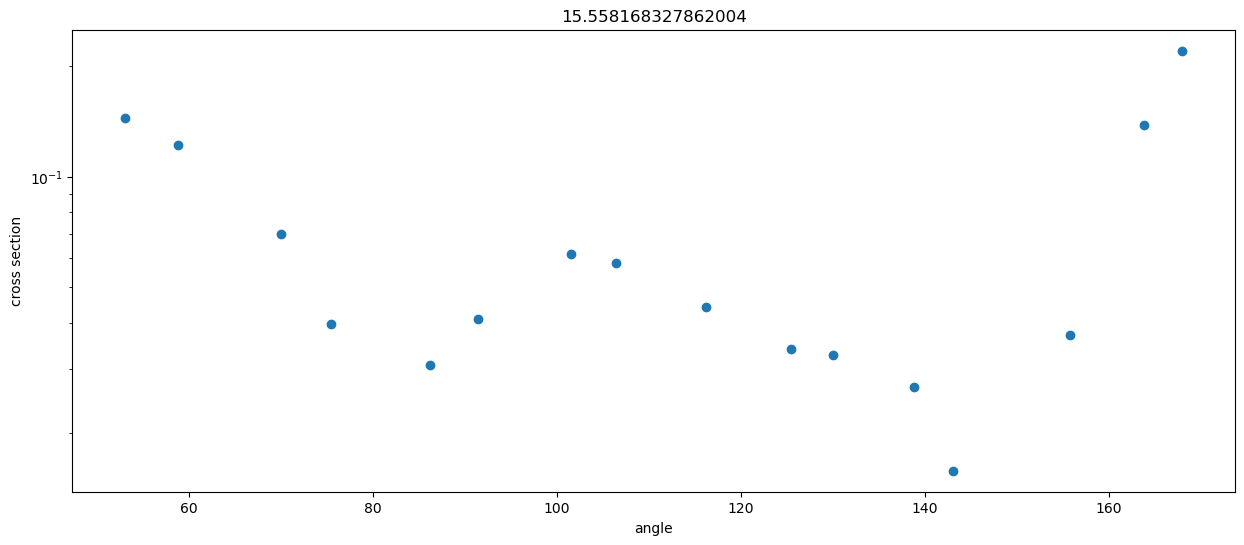

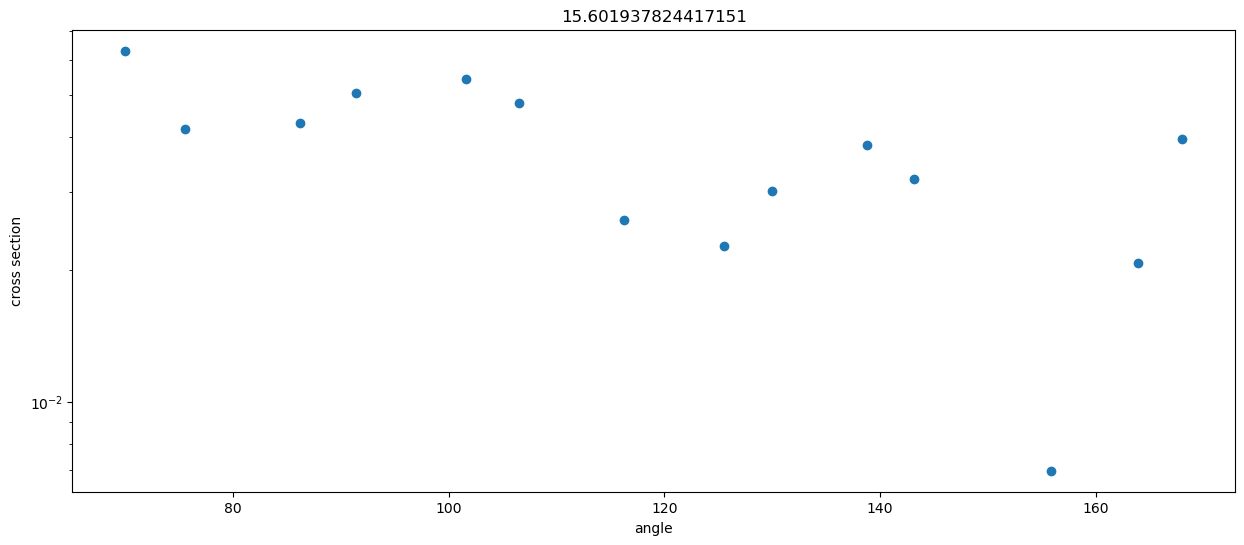

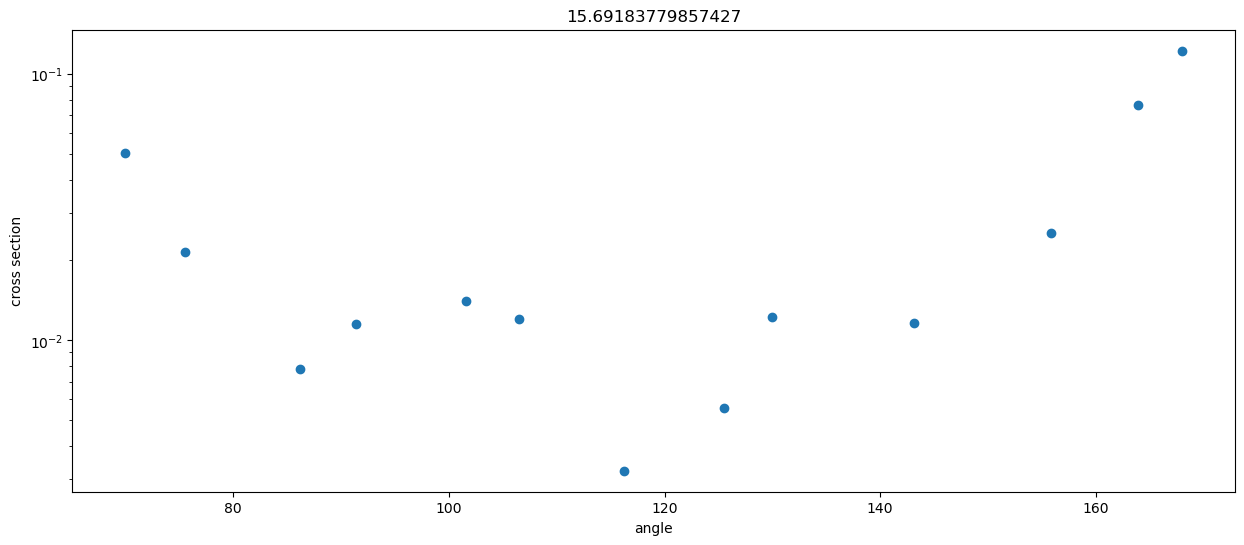

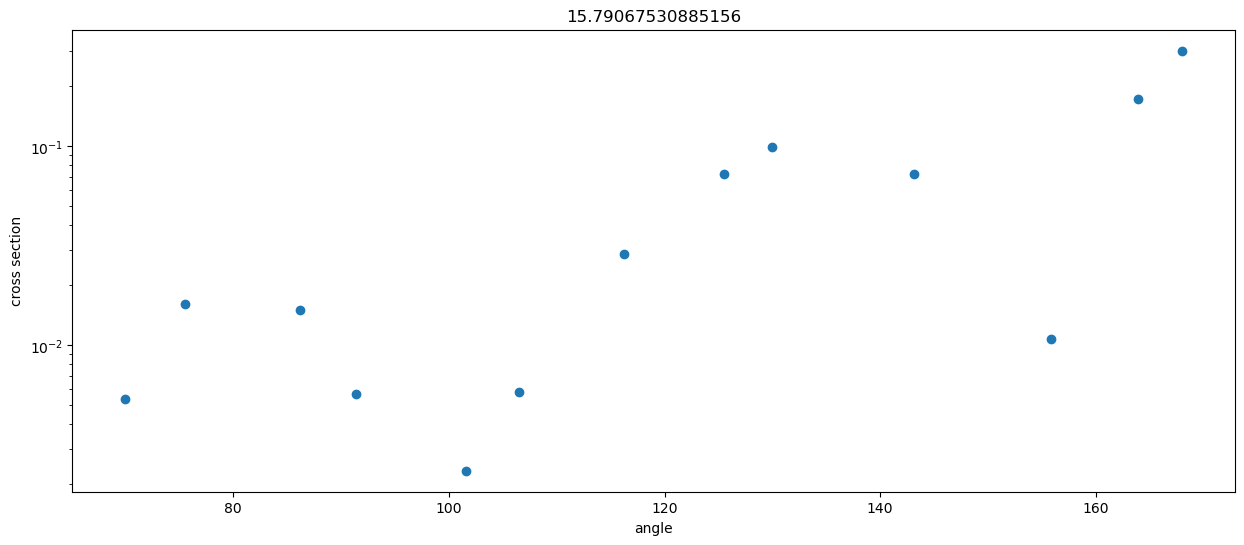

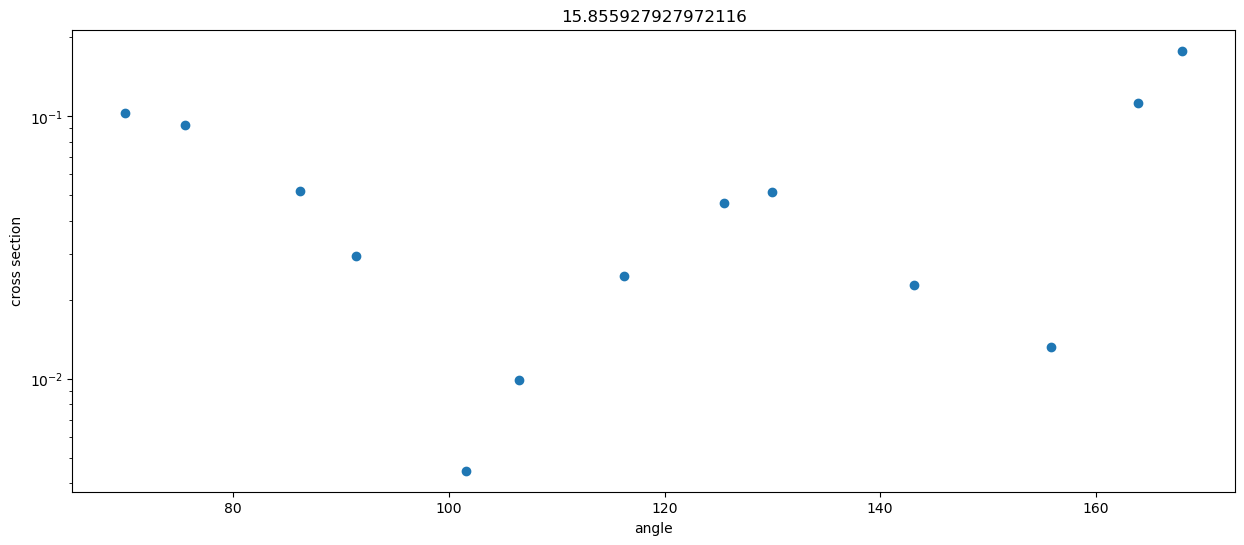

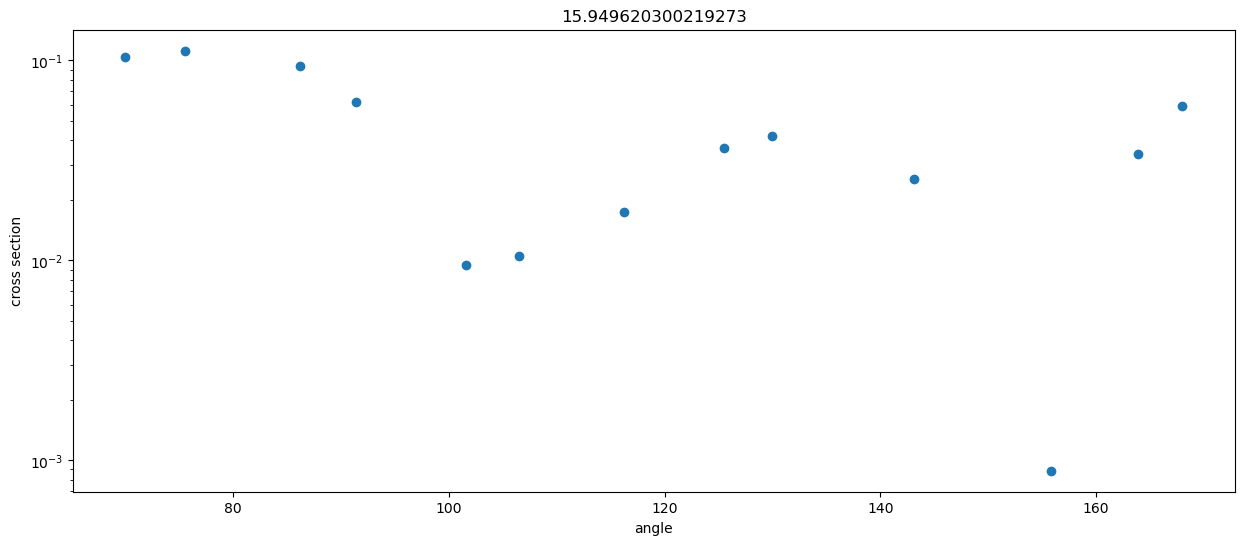

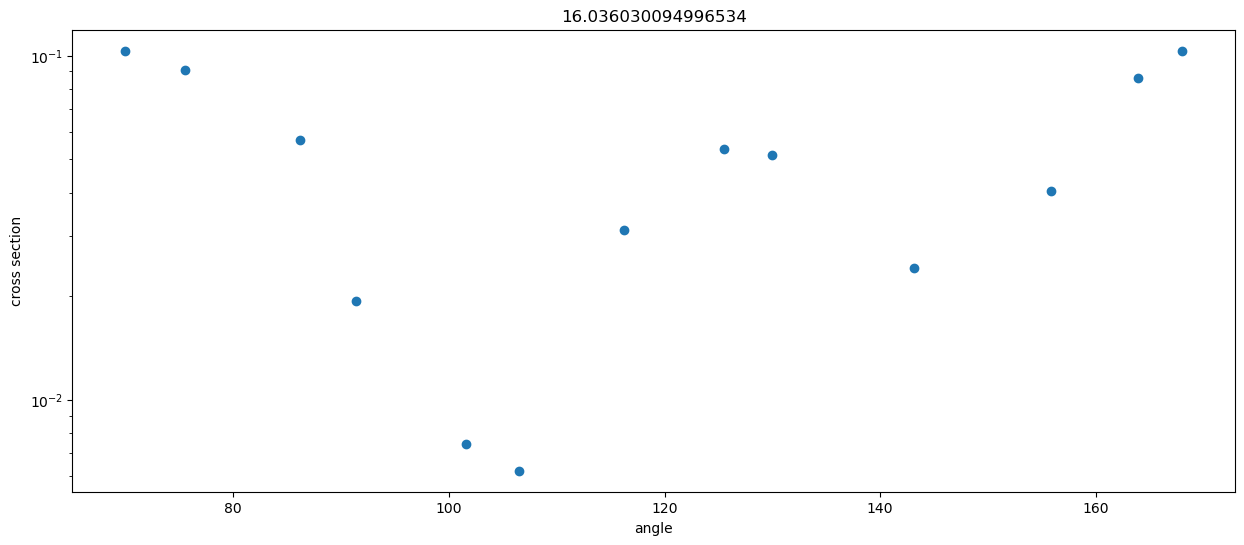

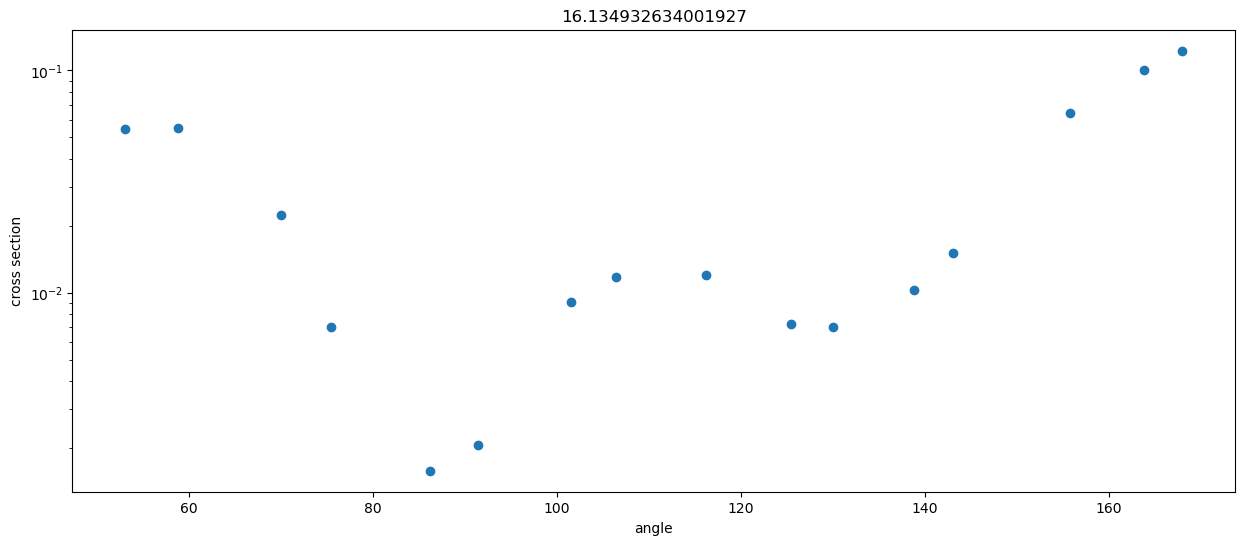

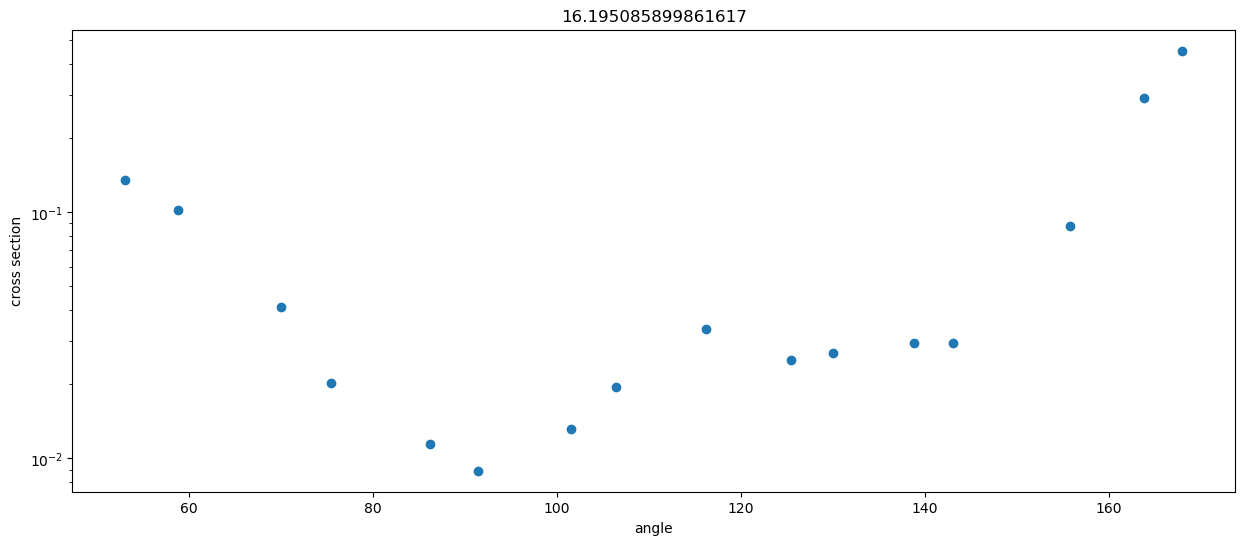

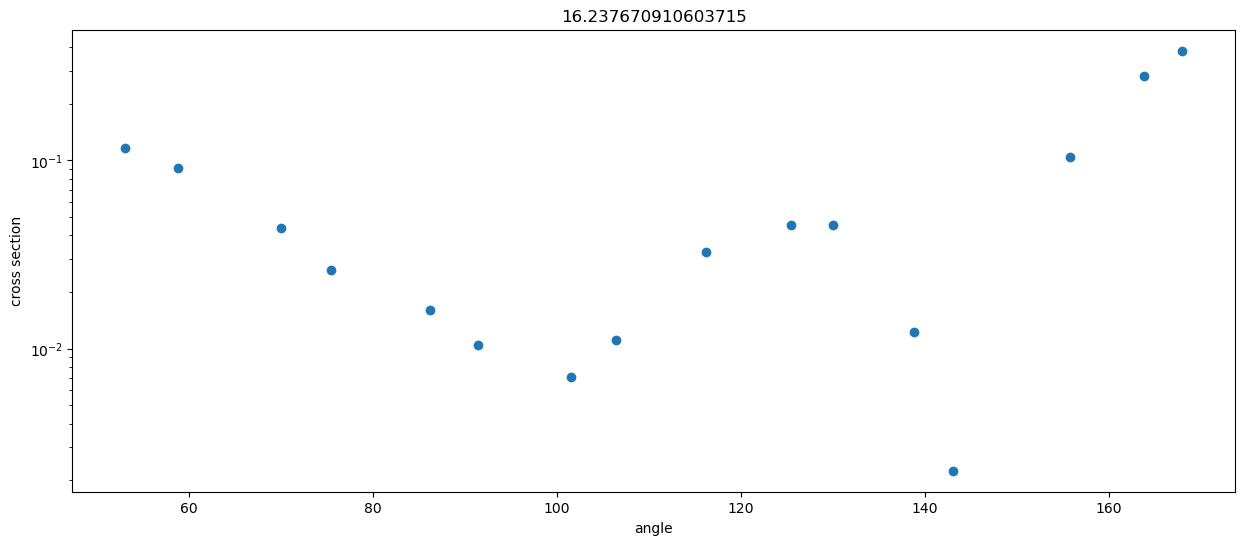

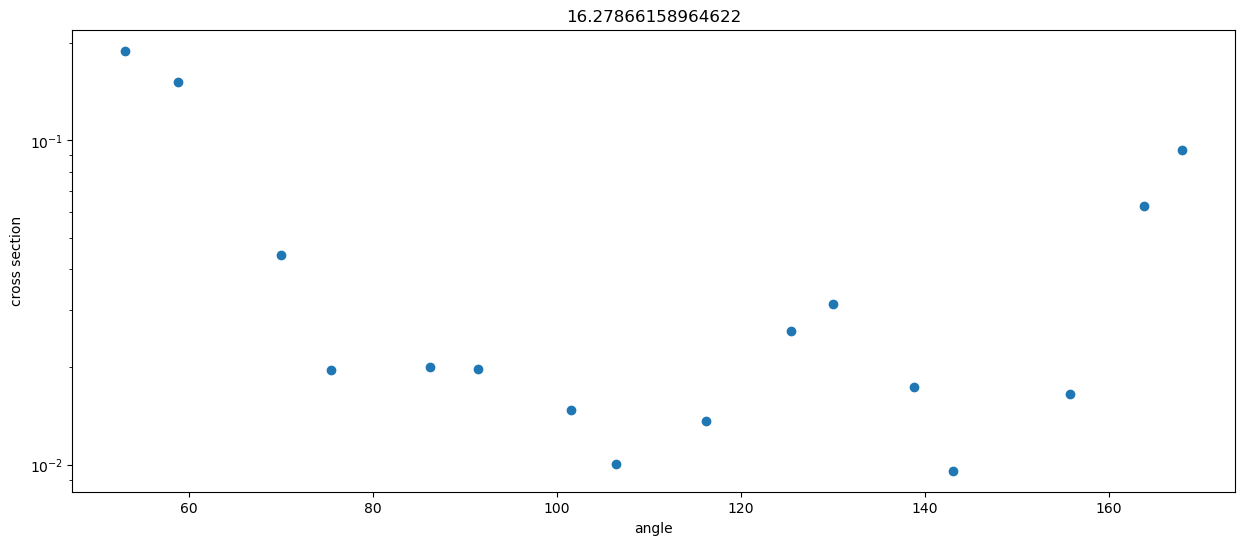

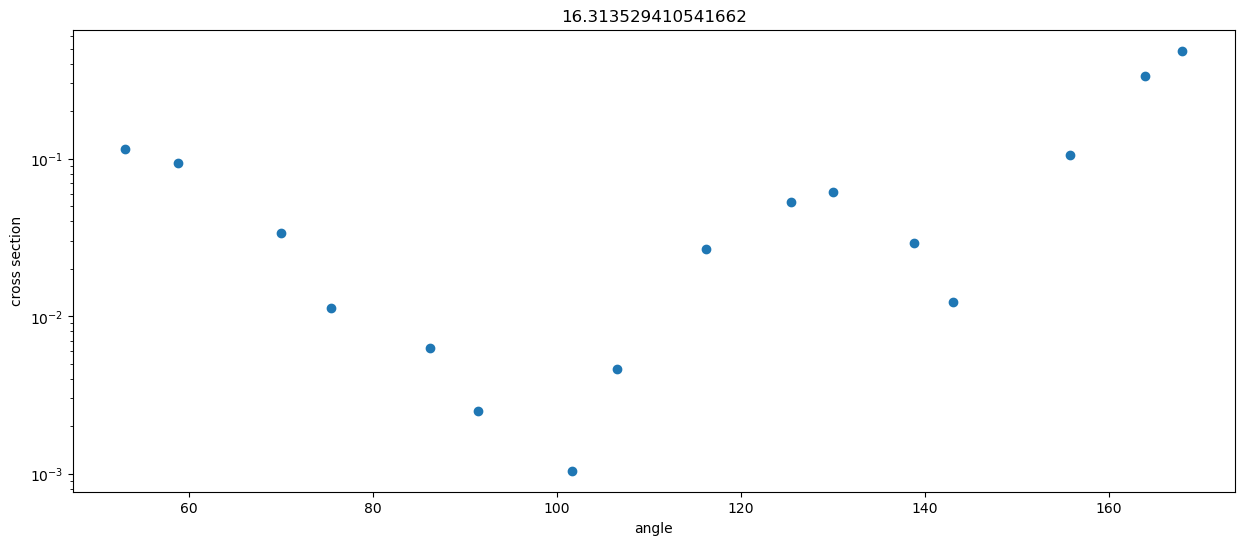

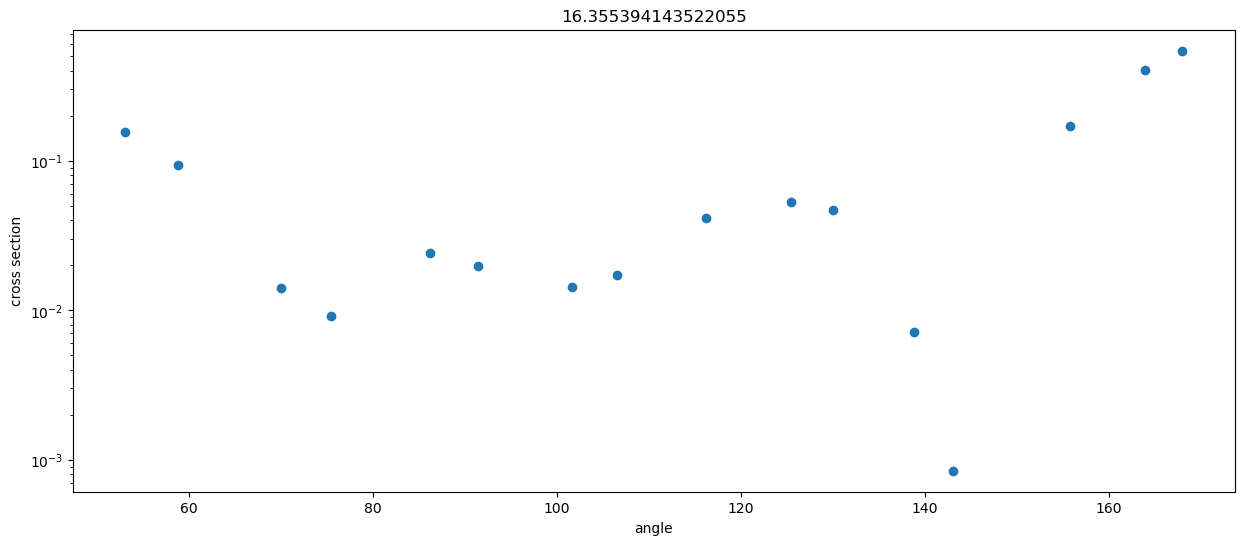

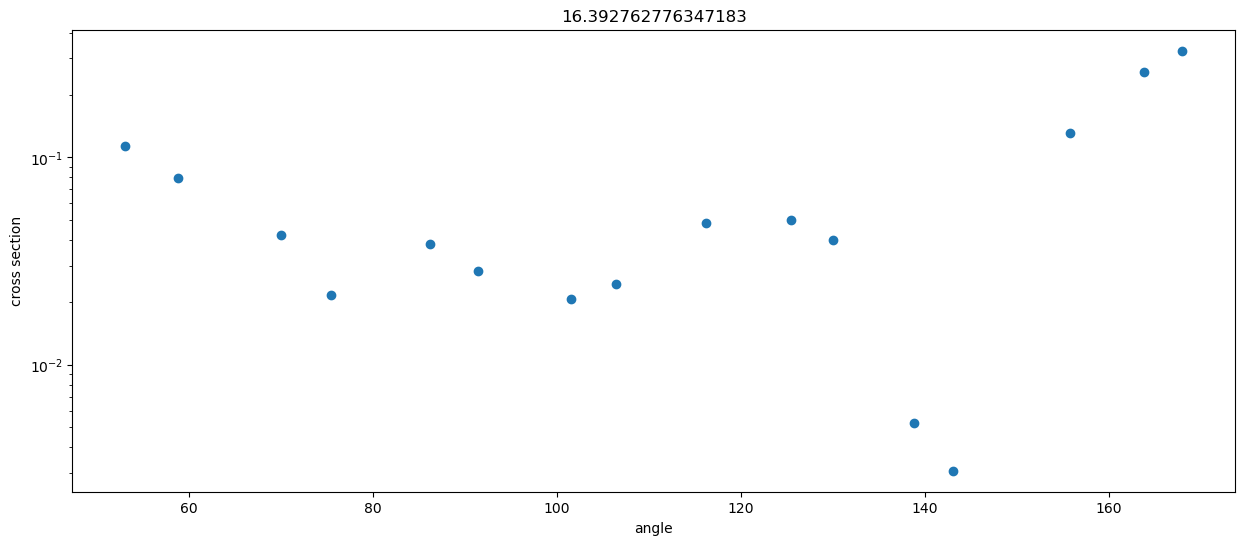

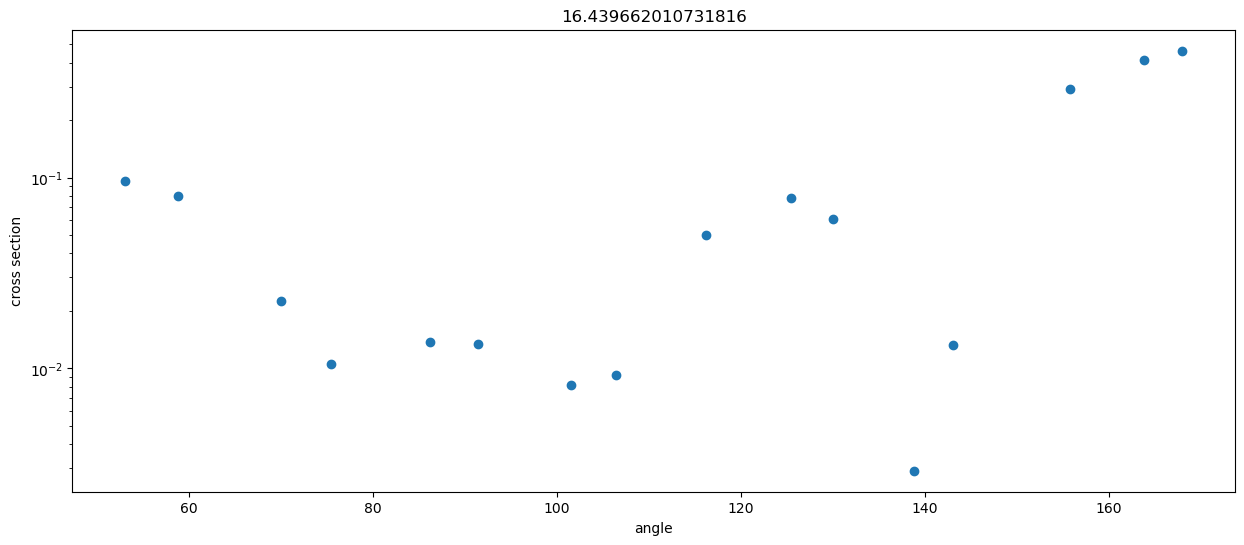

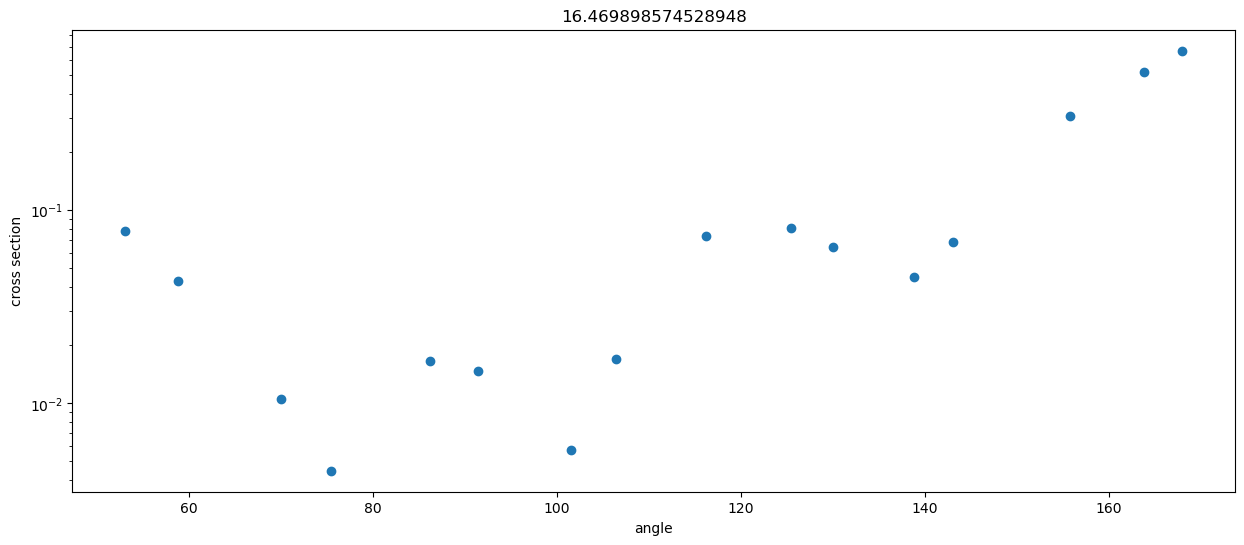

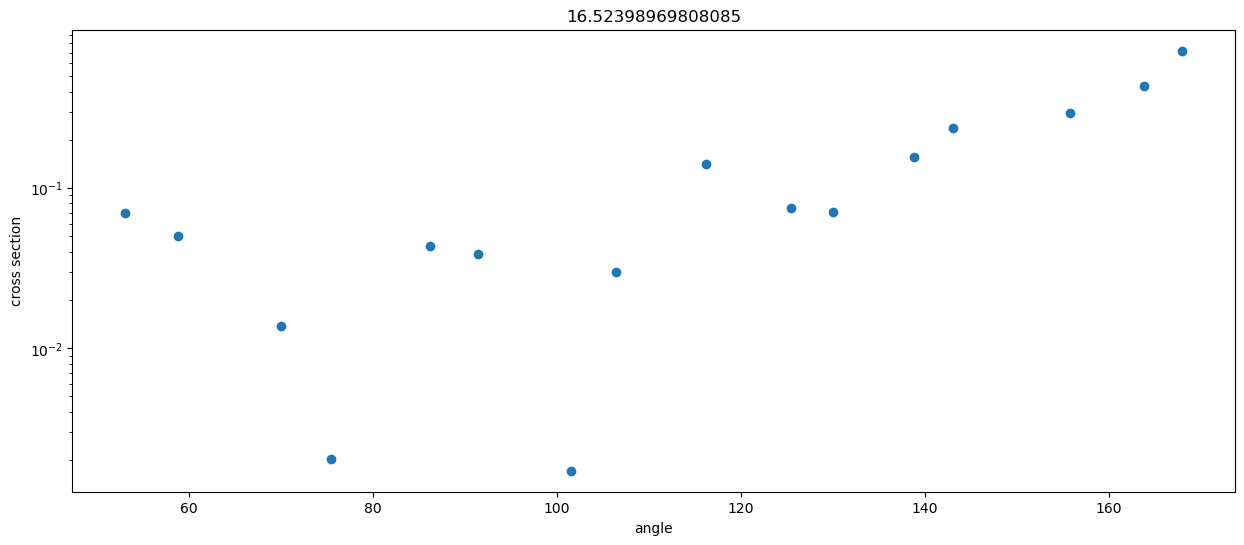

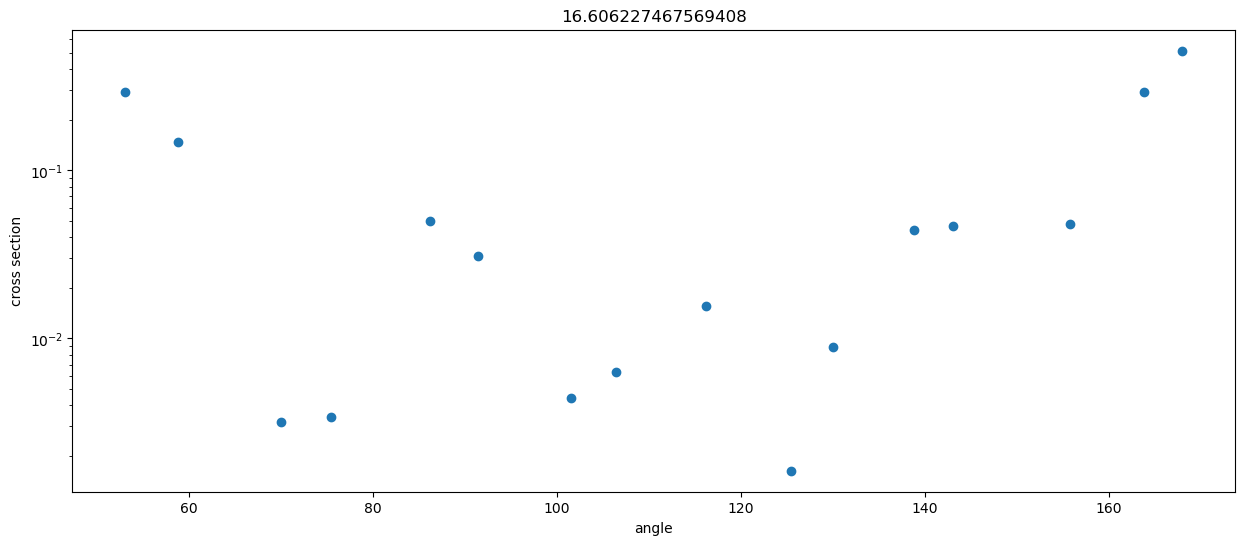

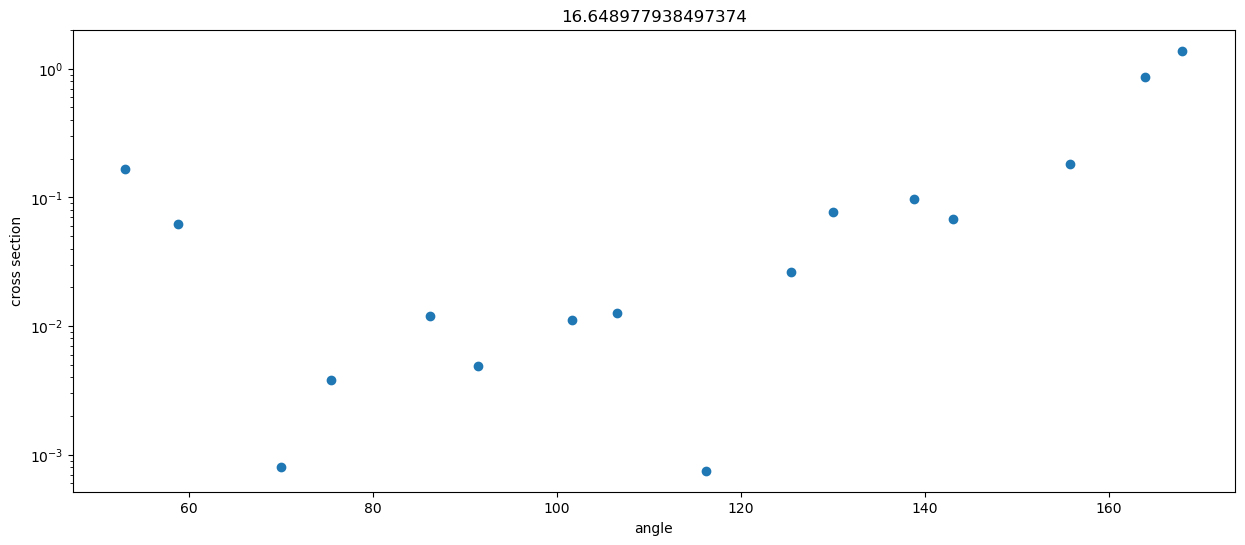

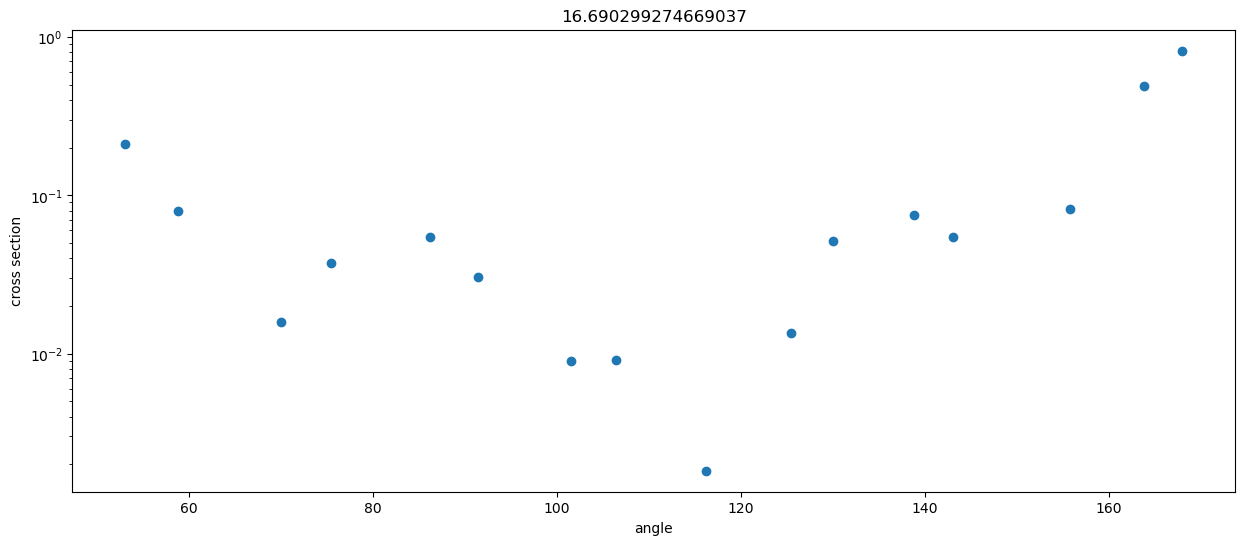

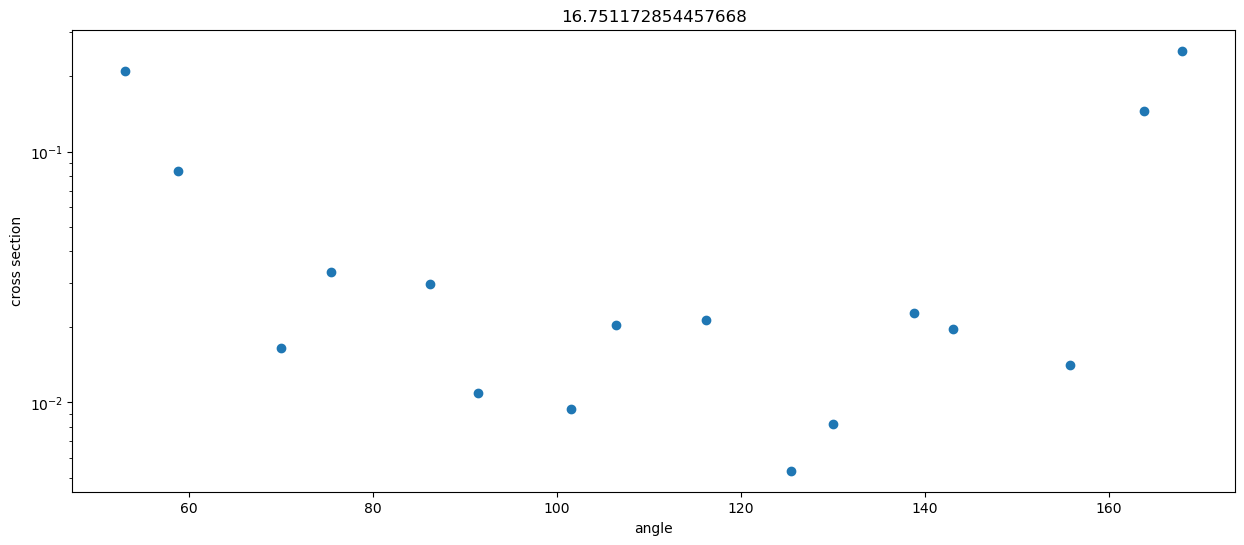

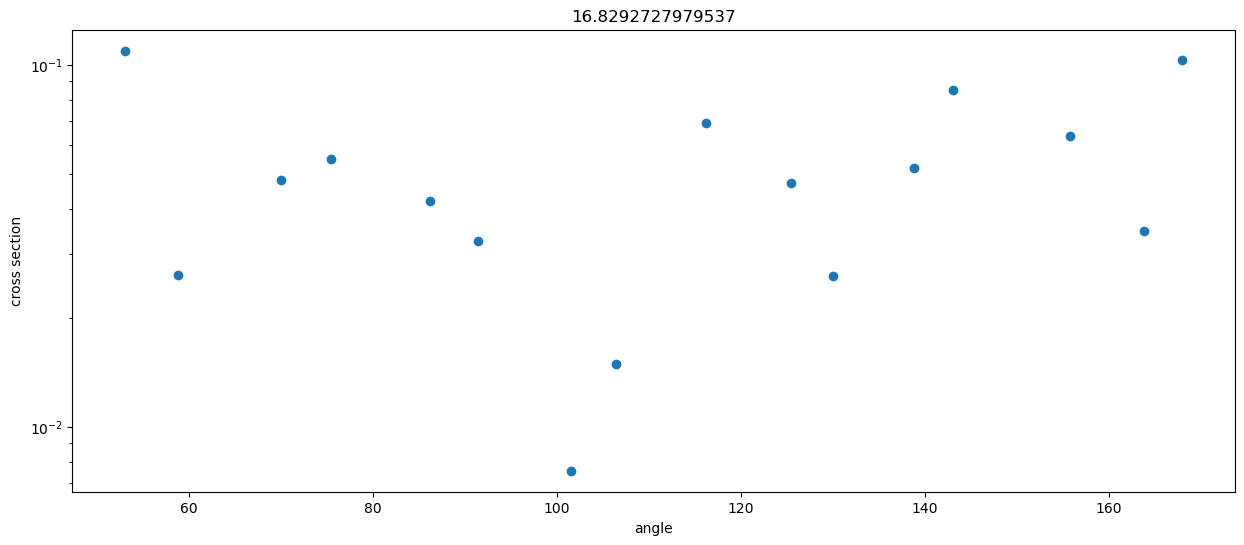

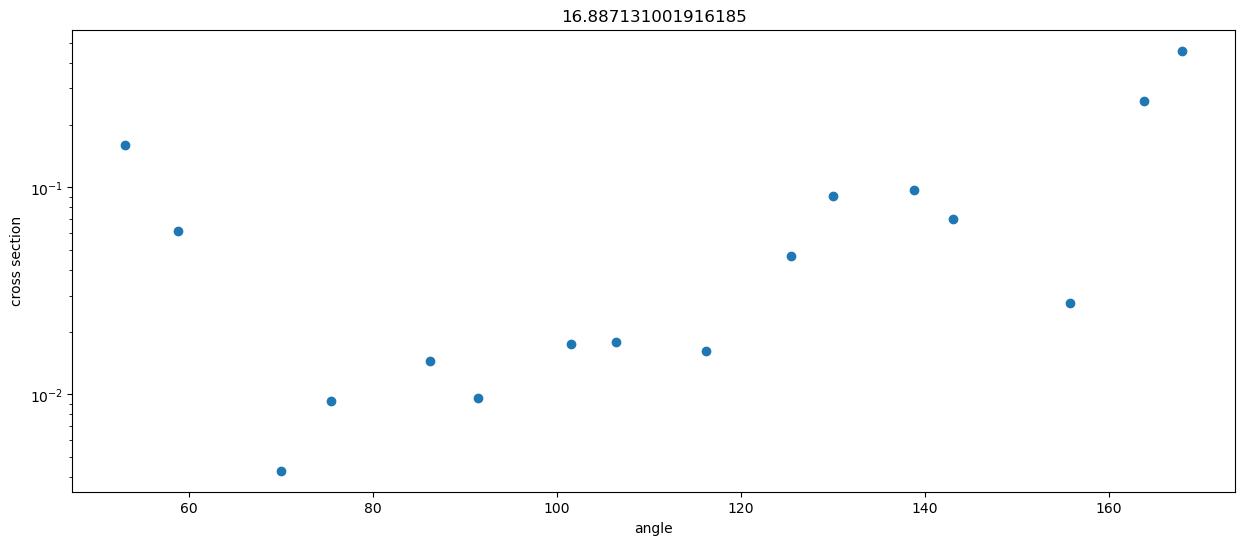

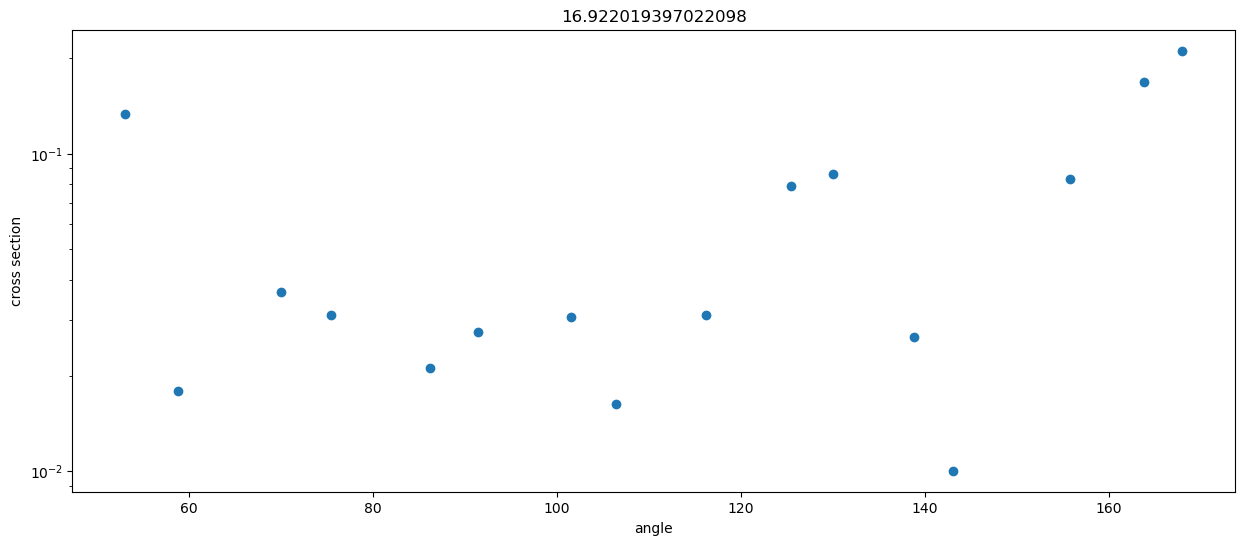

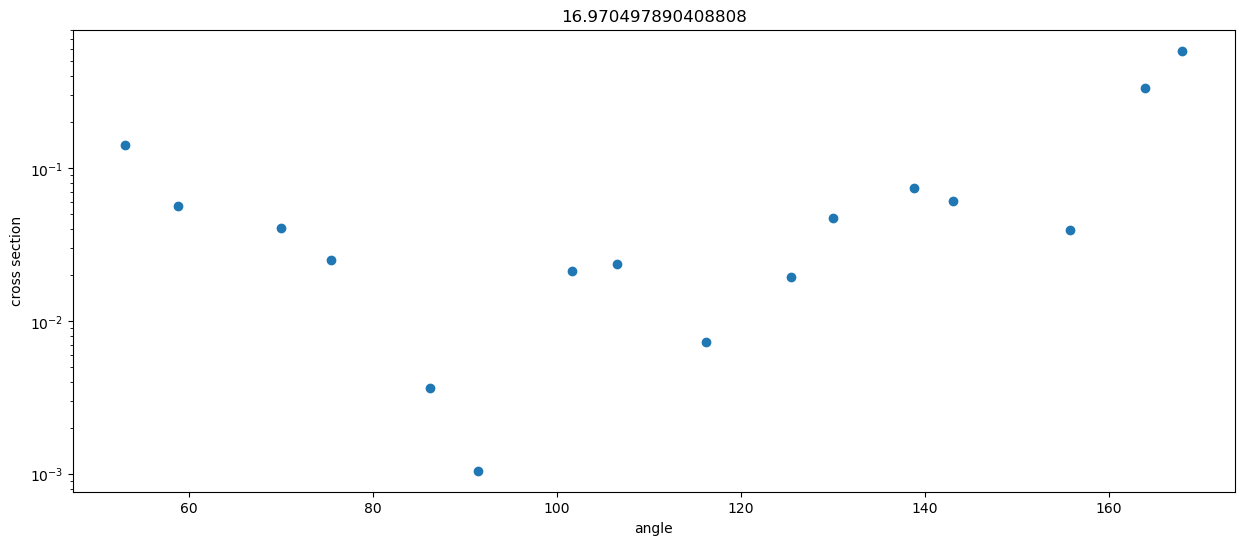

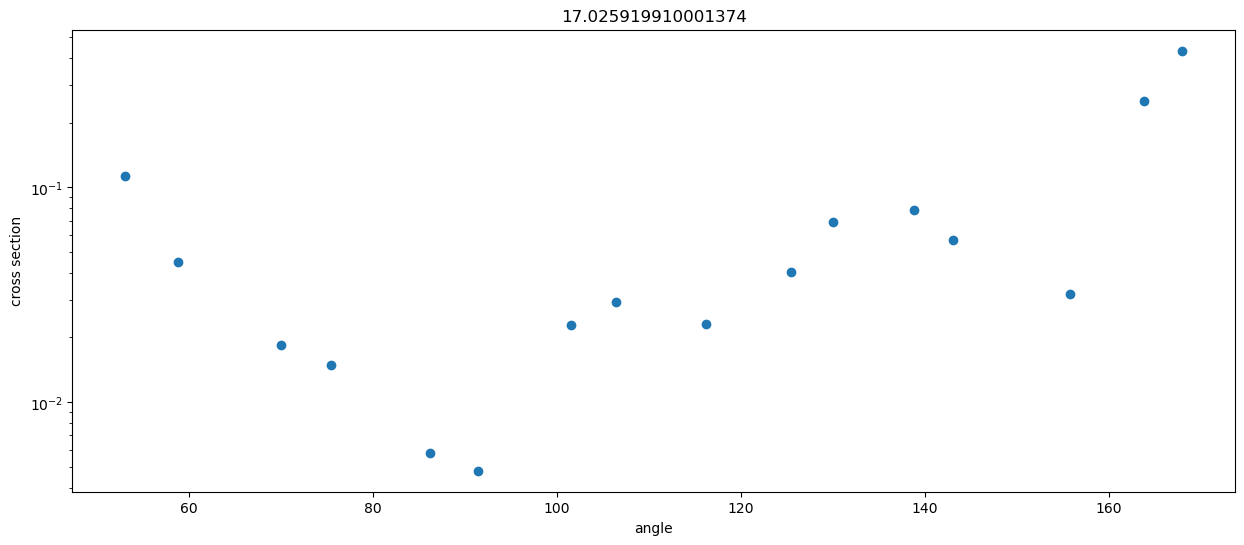

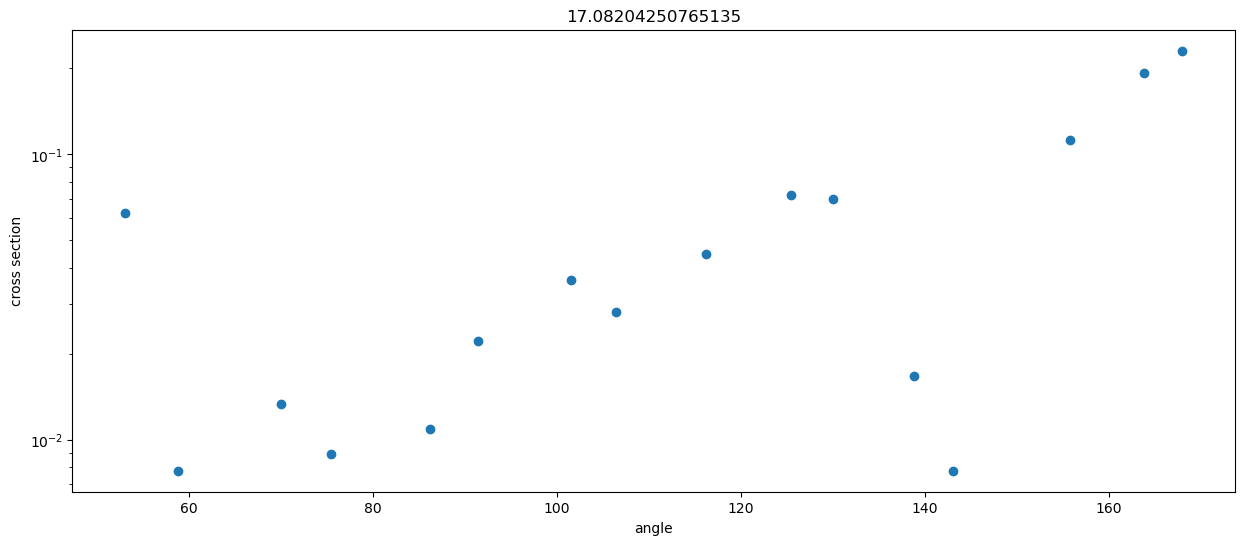

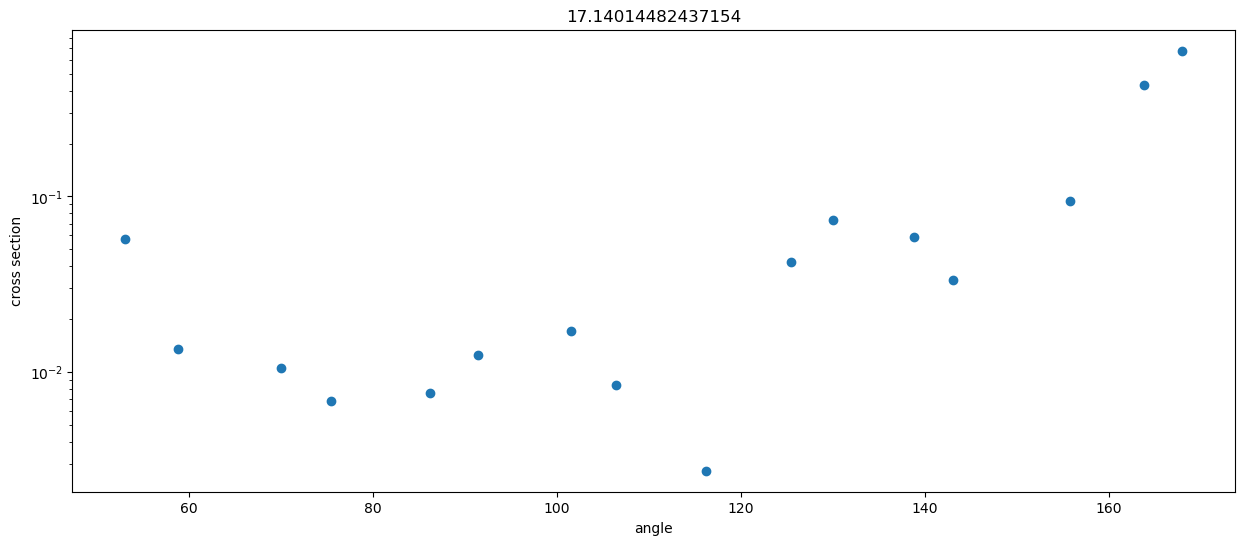

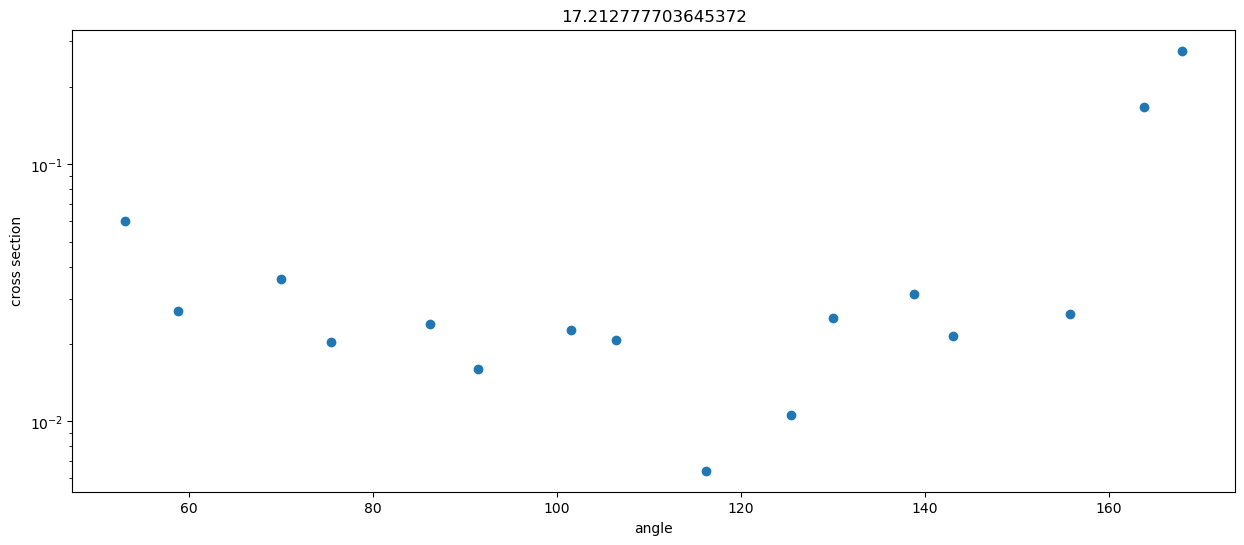

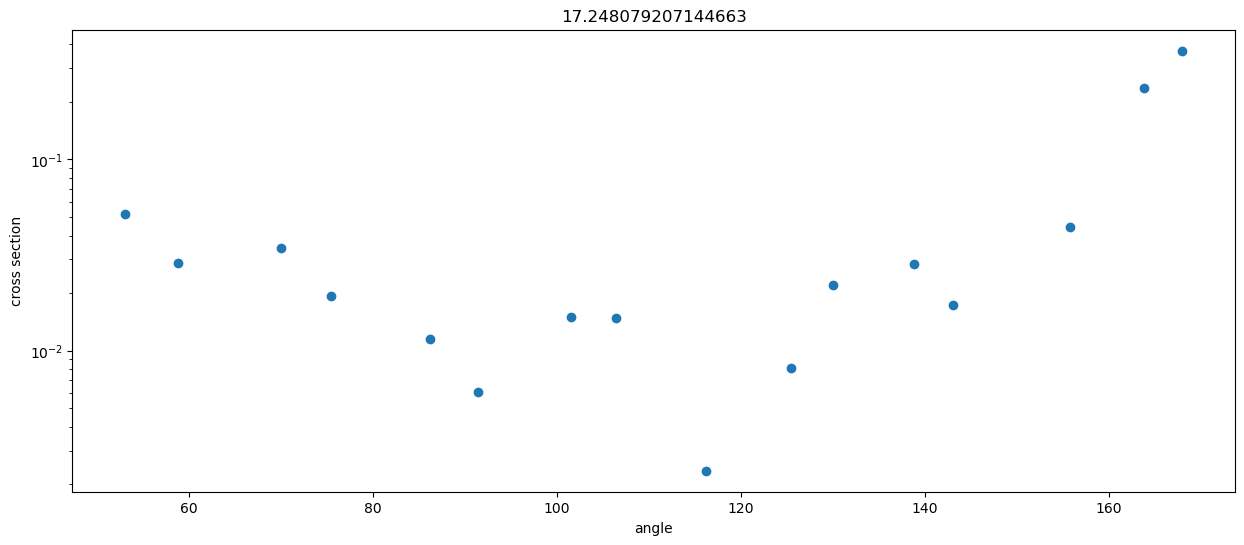

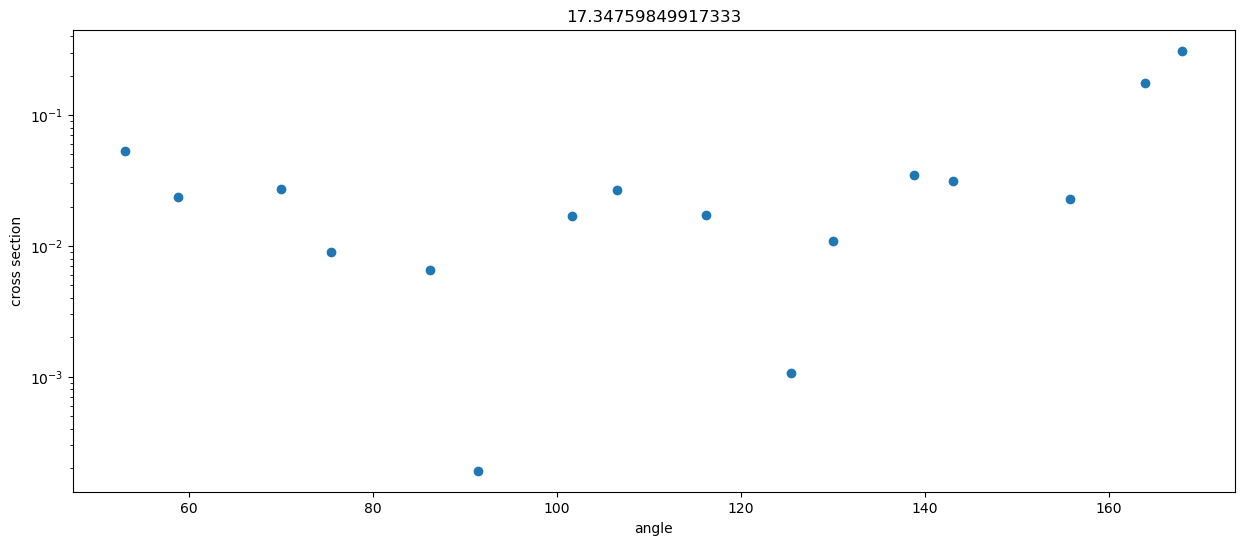

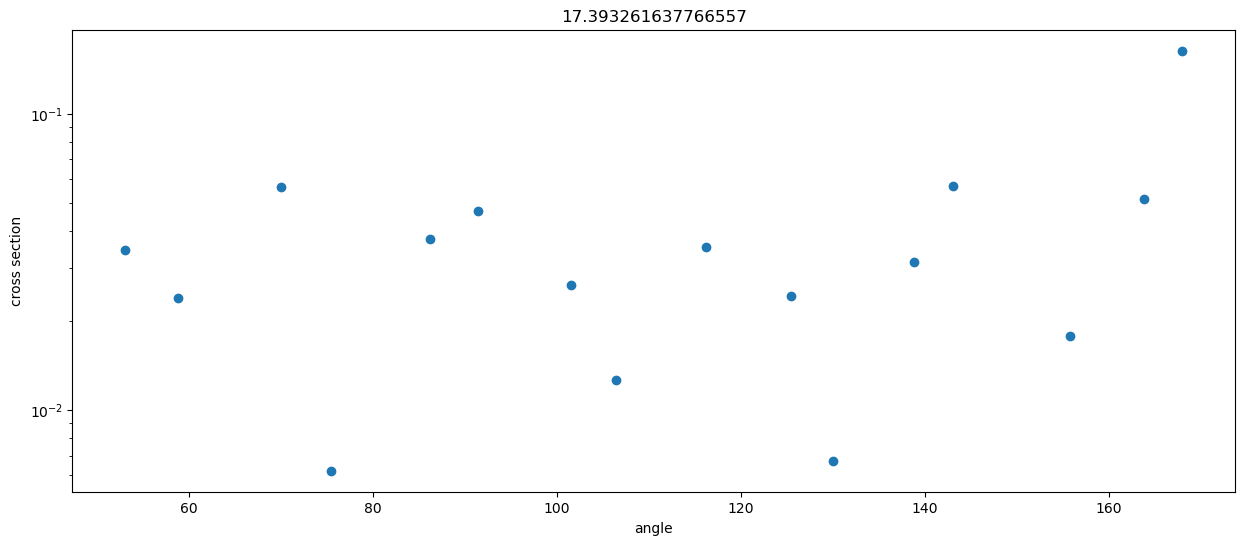

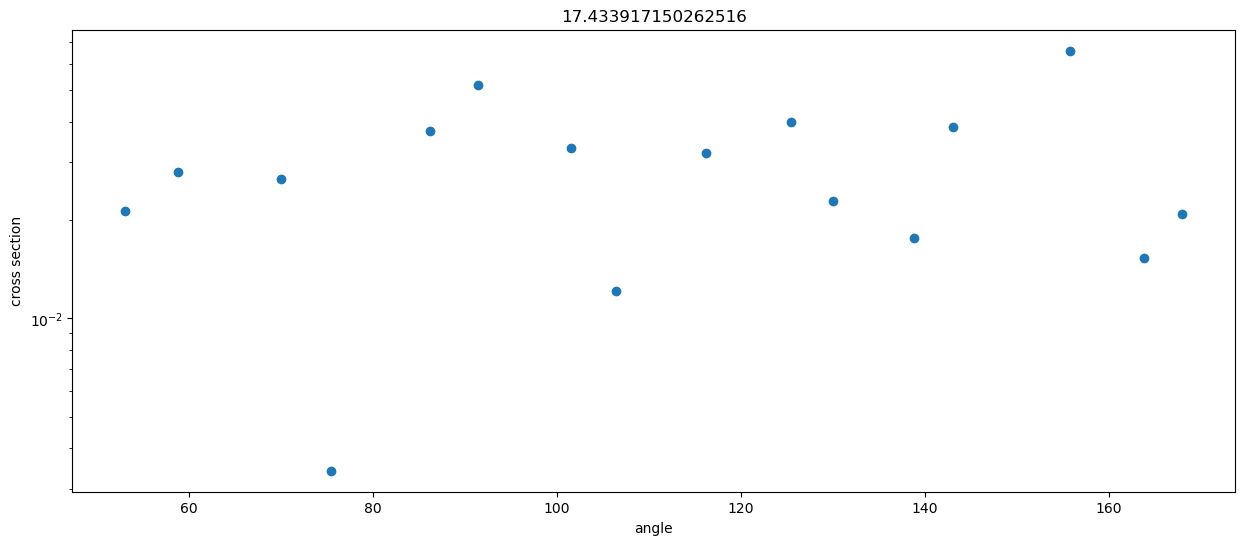

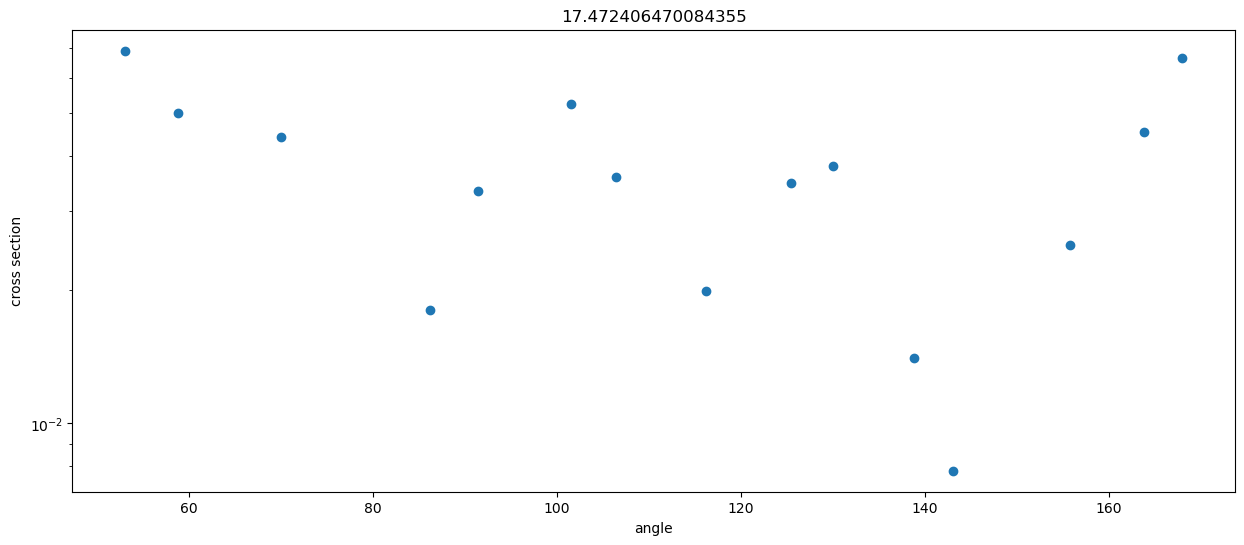

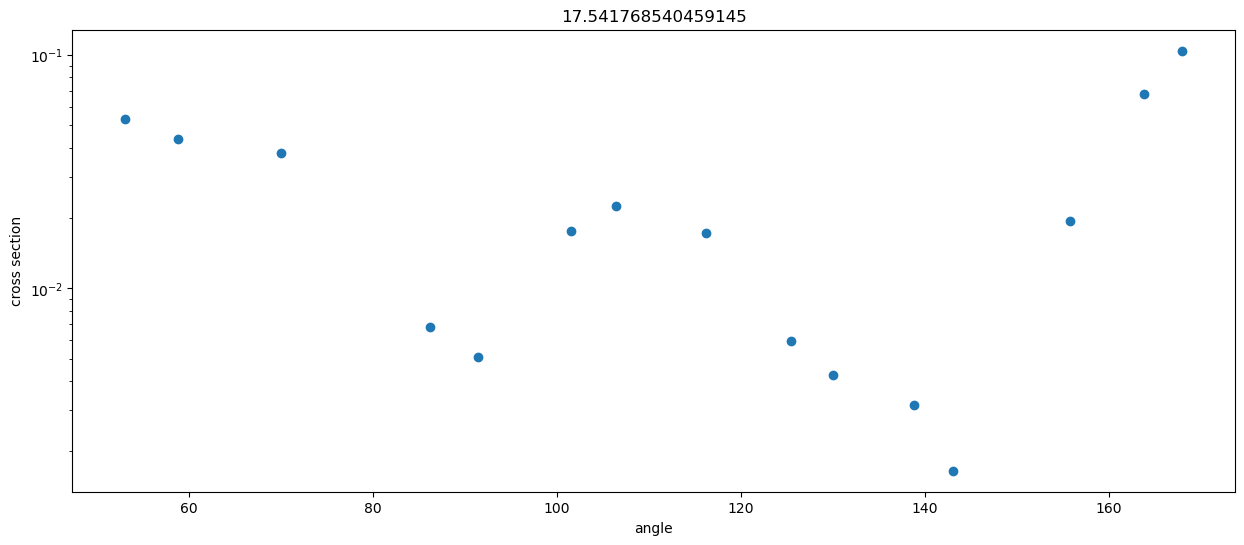

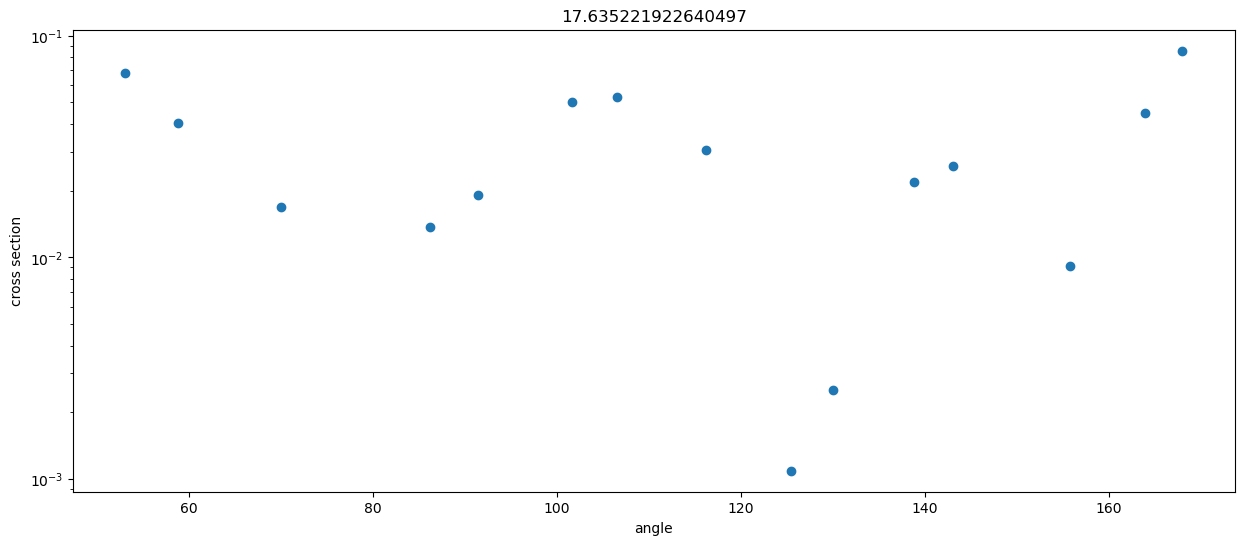

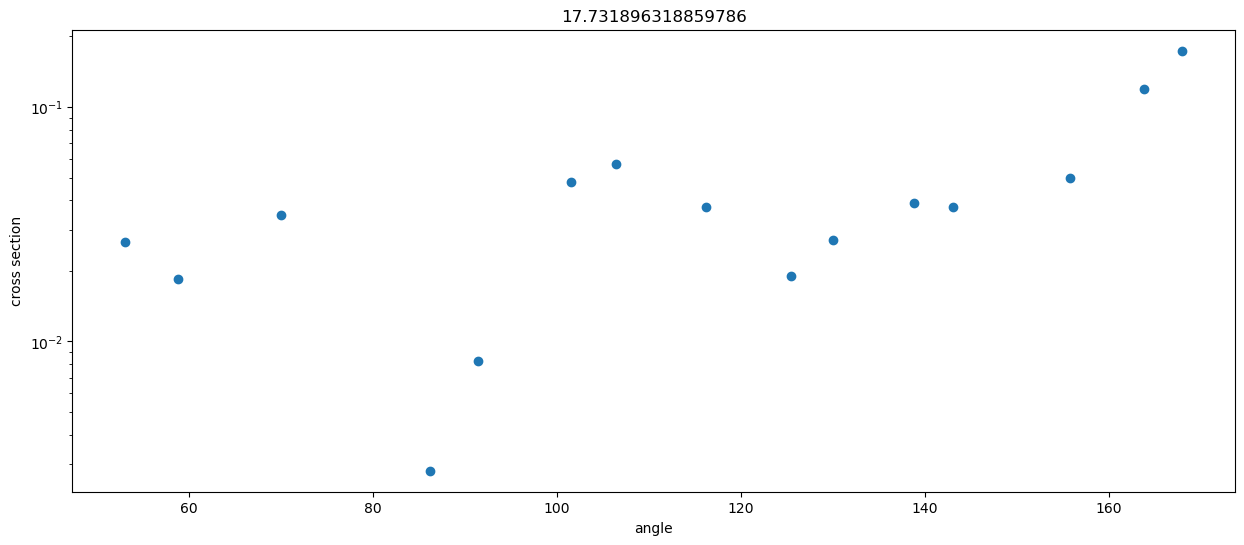

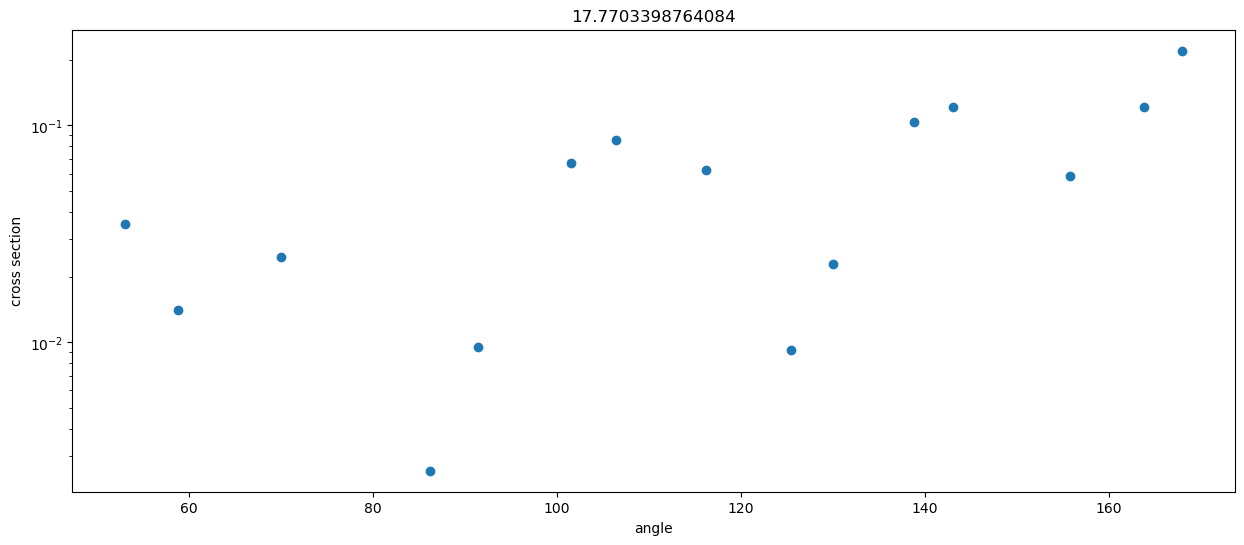

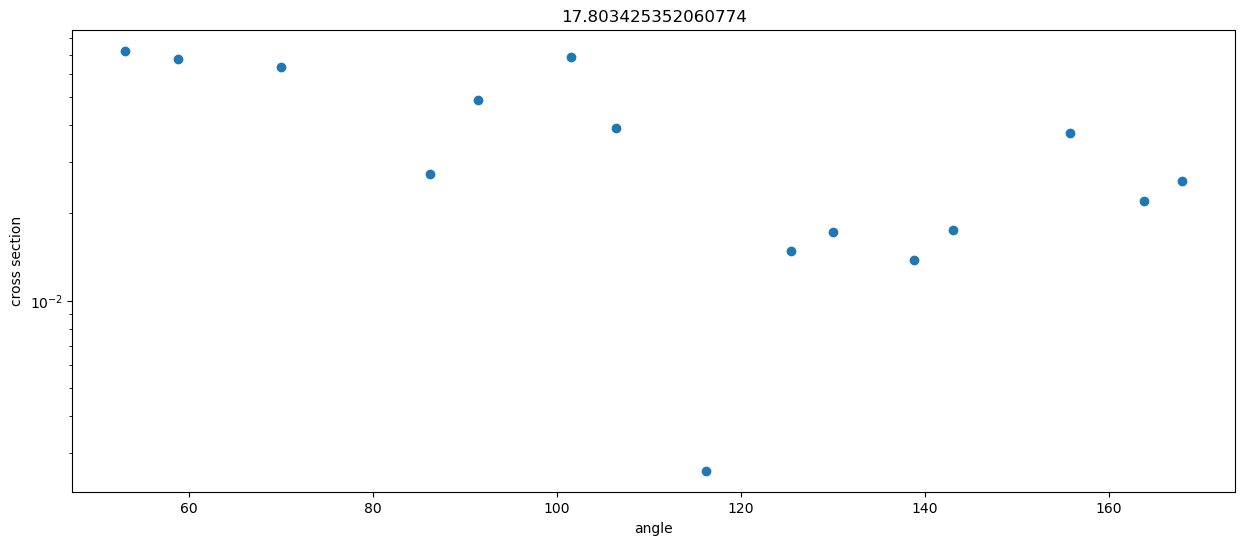

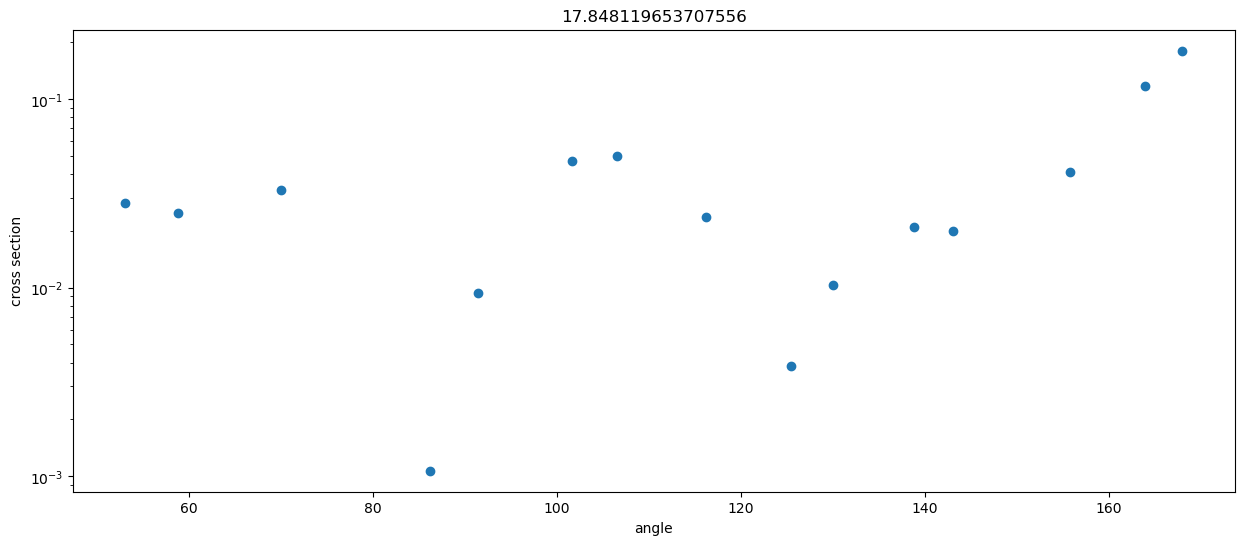

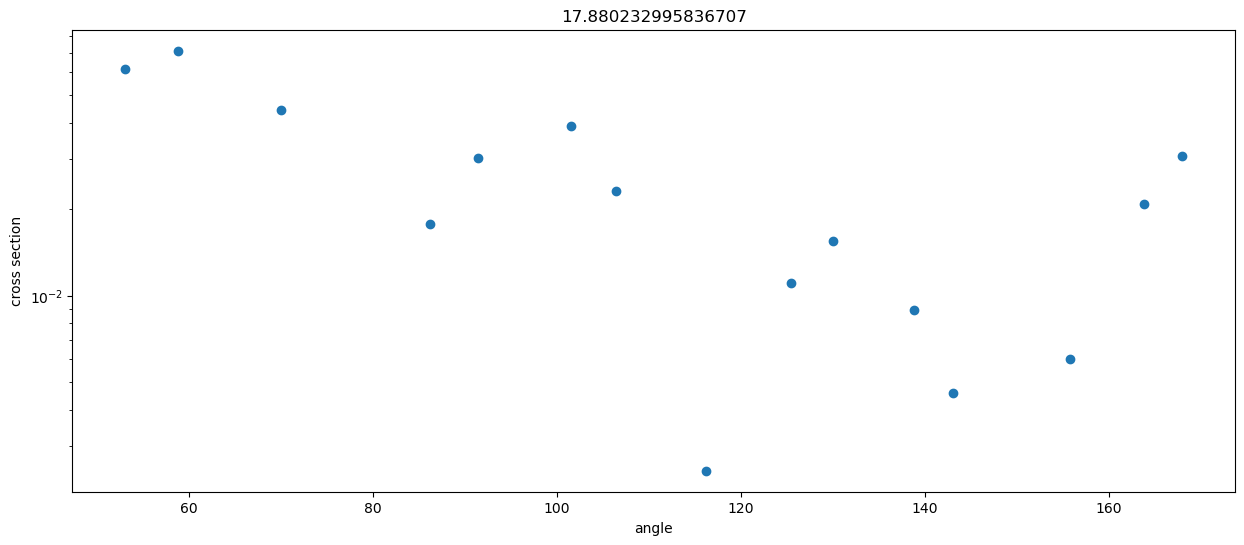

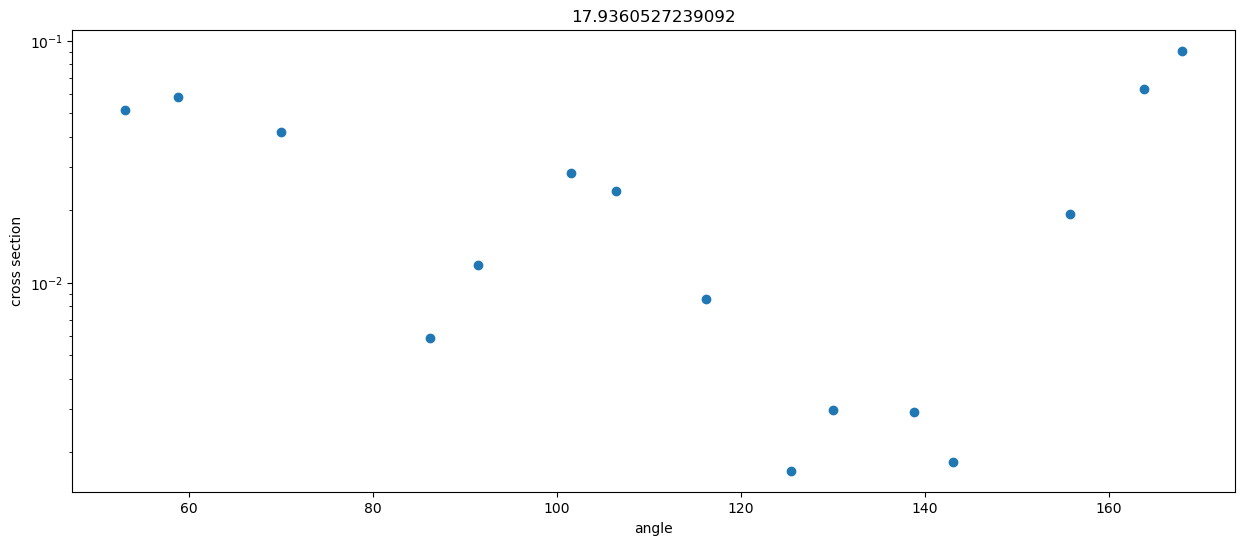

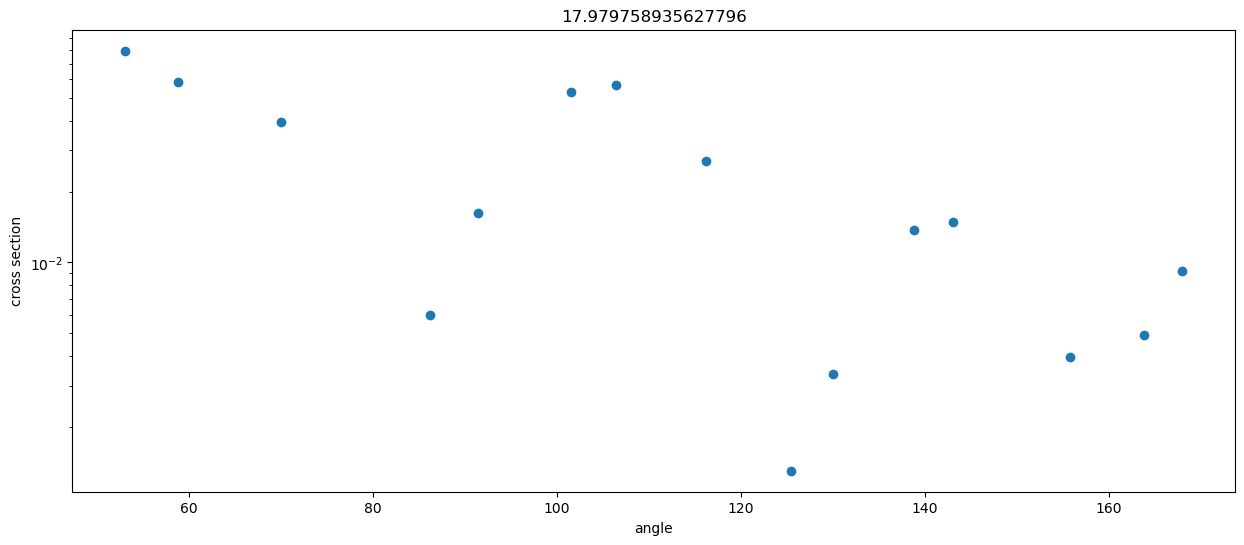

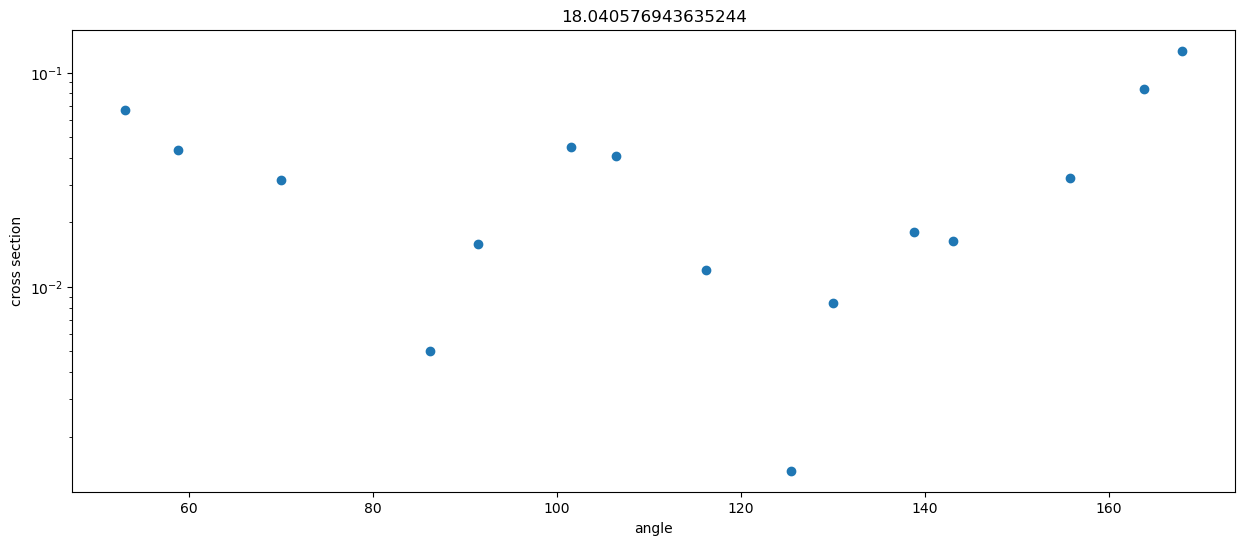

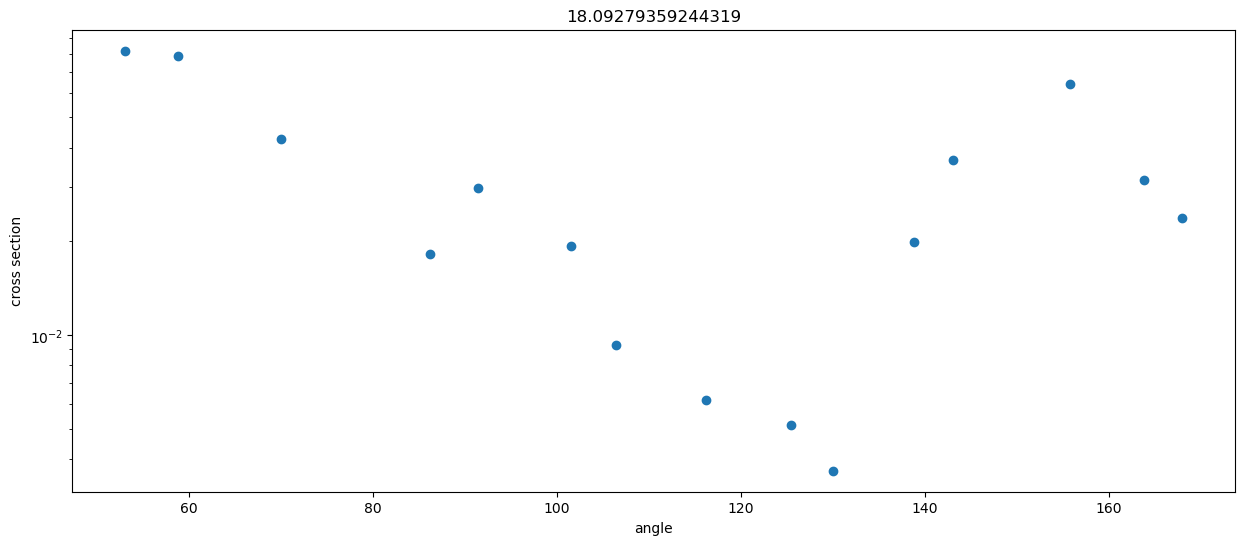

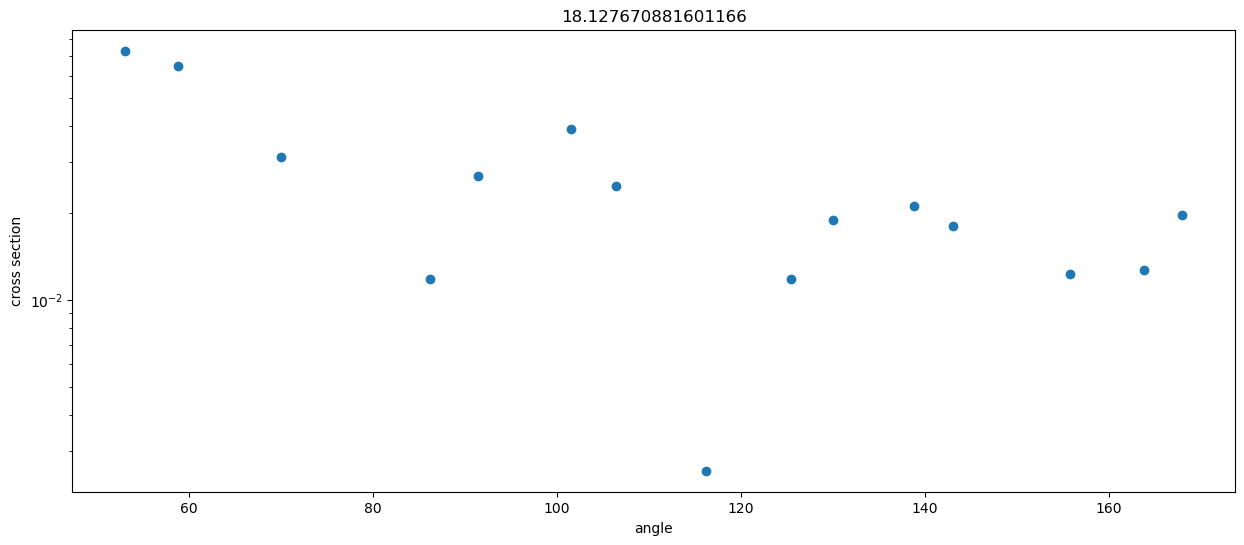

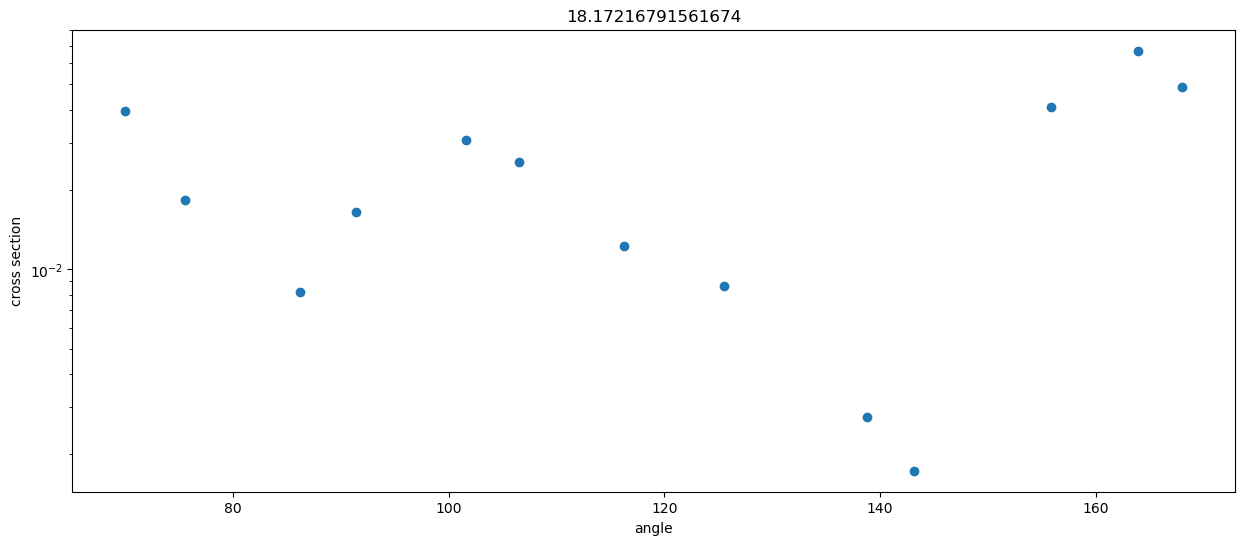

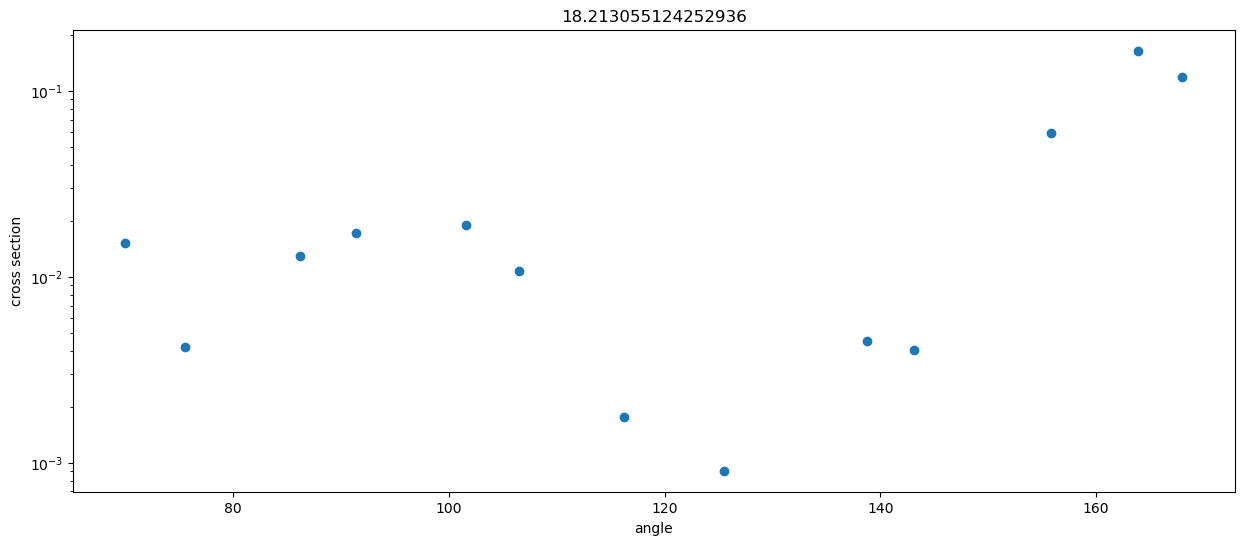

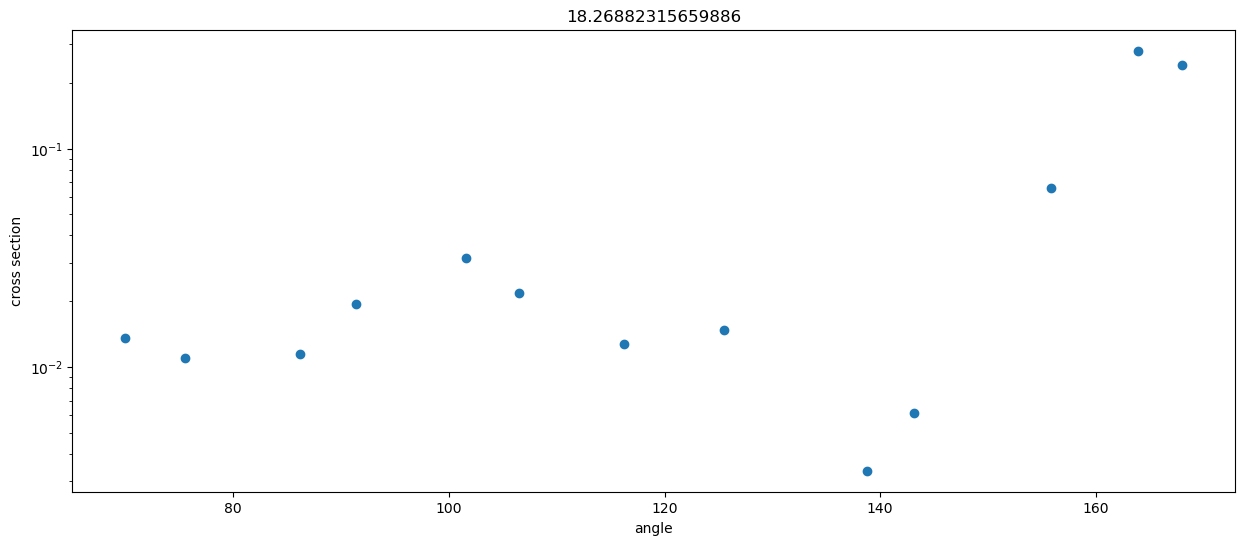

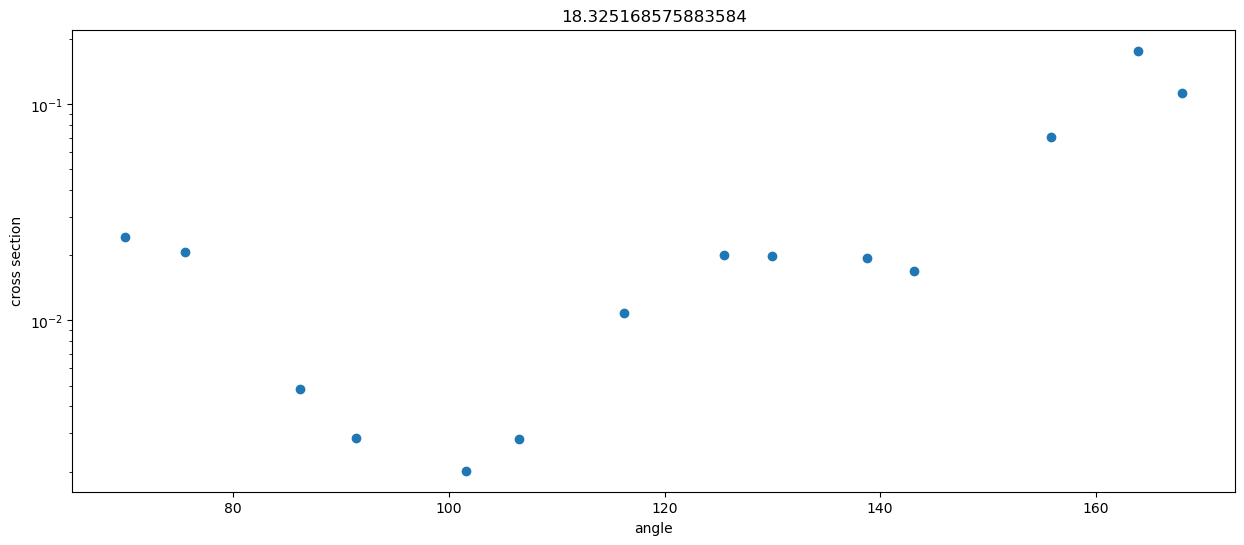

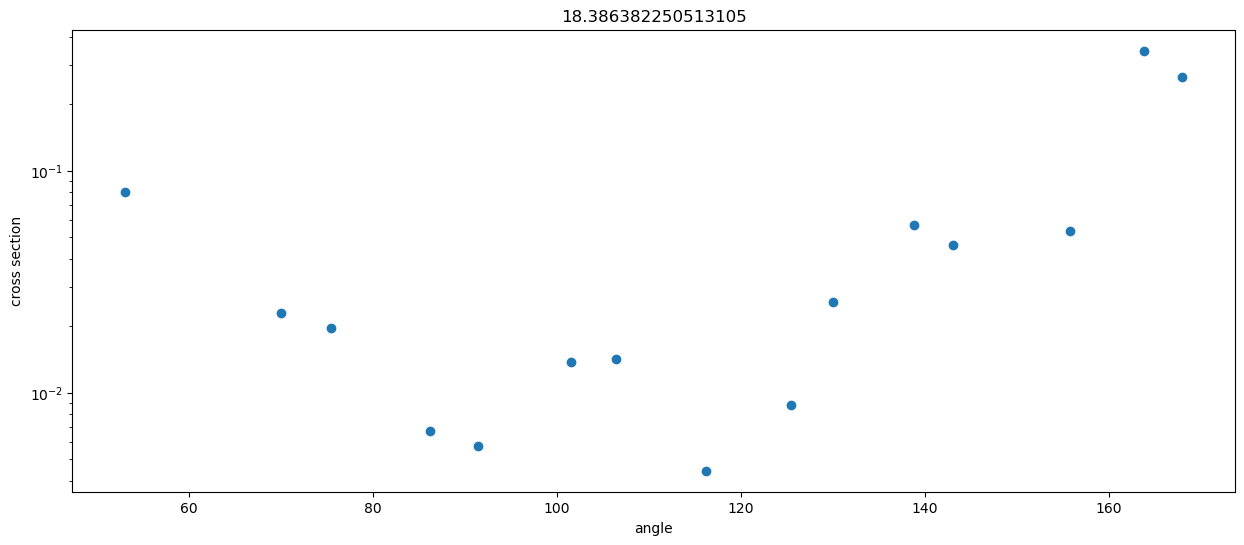

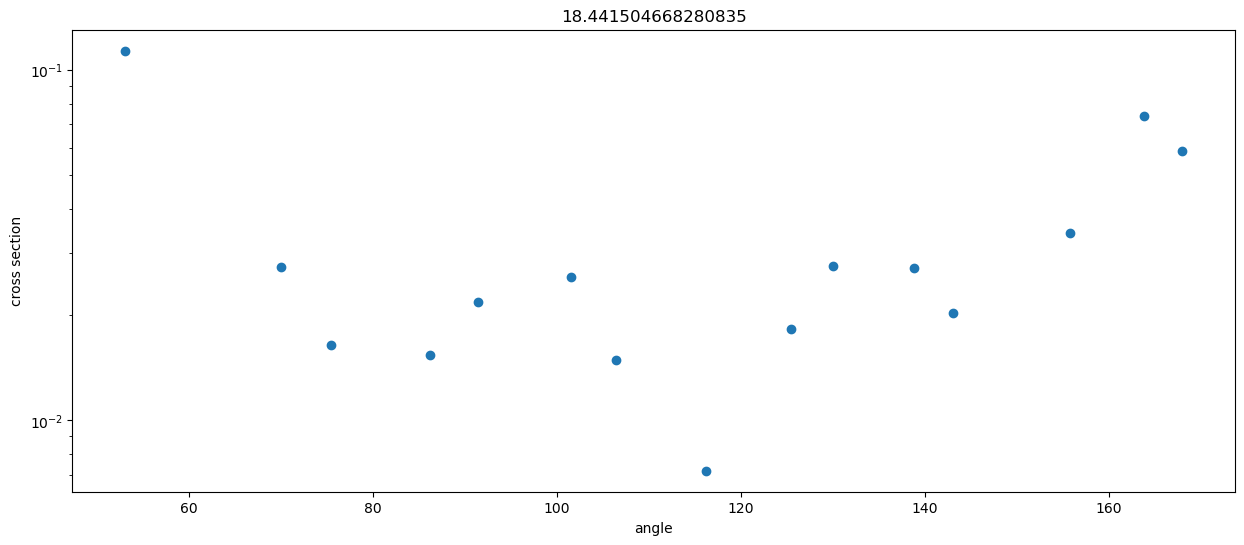

In [56]:
energies = [cluster[0] for cluster in clusters_dp_chosen]

functions.visualise_height_fix_energy(all_cs, energies)